Viés de uso de códons como preditor do grupo taxonômico: uma comparação de algoritmos de aprendizado de máquina
=====================================

**Entrega:** Criatura Lendária "Tiamat" <br>
**Autoria:** Giovanna Avellar Machado <br>
**Disciplina:** Aprendizado de Máquina - 2º Semestre - T26 <br>
**Docente Responsável:** Daniel Roberto Cassar <br>
**Instituição:** Ilum - Escola de Ciência

## Índice

1. [Introdução](#intro)
2. [Metodologia](#metodologia)
3. [Desenvolvimento](#desenvolvimento) <br>
   3.1 [Preparação do Ambiente Inicial](#pre) <br>
   3.2 [Carregamento, Limpeza e Escolha do Target](#carr) <br>
   3.3 [Separação dos Dados de Treino e Teste](#sep) <br>
   3.4 [Análise Exploratória](#exp) <br>
   3.5 [Modelo Baseline](#base) <br>
   3.6 [Algoritmos, Pipeline e Otimização de Hiperparâmetros](#opt) <br>
   3.7 [Comparação dos Modelos por Validação Cruzada](#val) <br>
   3.8 [Avaliação Final no Conjunto de Teste](#teste) <br>
   3.9 [Interpretação dos Resultados](#interp) <br>
5. [Conclusões e Principais Aprendizados](#conclusao)
6. [Descrição do uso de IA neste trabalho](#interacao)
7. [Agradecimentos](#agradecimentos)
8. [Referências](#refs)

<a id="intro"></a>
## 1. Introdução

$ \ \ \ \ \ $ O presente trabalho busca estudar o desempenho de diferentes modelos induzidos por algoritmos diferentes de Machine Learning (Regressão Logística, k-NN, Decision Tree, Random Forest e Gradient Boosting) em um conjunto de dados que contém informações sobre a Identidade Taxonômica de Organismos, de acordo com o Viés de Uso de Códons, considerando diferentes conjuntos de hiperparâmetros e analisando seu impacto sobre as predições realizadas. 

$ \ \ \ \ \ $ Toda proteína é produzida a partir de uma "receita" escrita no DNA. Durante a tradução, o RNA mensageiro é lido de três em três nucleotídeos, e cada trio, chamado códon, indica qual aminoácido deve ser adicionado à proteína ou se a tradução deve parar. Com quatro bases possíveis em cada uma das três posições, existem 4 × 4 × 4 = 64 códons. Porém, as proteínas são formadas por apenas 20 aminoácidos padrão, e somente três códons funcionam como sinais de parada. Sobram, portanto, mais códons do que aminoácidos [[1]](#refs).

$ \ \ \ \ \ $ Essa sobra faz com que o código genético seja redundante/degenerado, isto é, a maioria dos aminoácidos pode ser codificada por mais de um códon. Os códons que codificam o mesmo aminoácido são chamados de sinônimos. A leucina, por exemplo, possui seis códons sinônimos, enquanto a metionina e o triptofano possuem apenas um cada (Figura 1). Assim, uma mesma proteína pode ser escrita no DNA de muitas formas diferentes, trocando um códon por outro sinônimo sem alterar nenhum aminoácido.

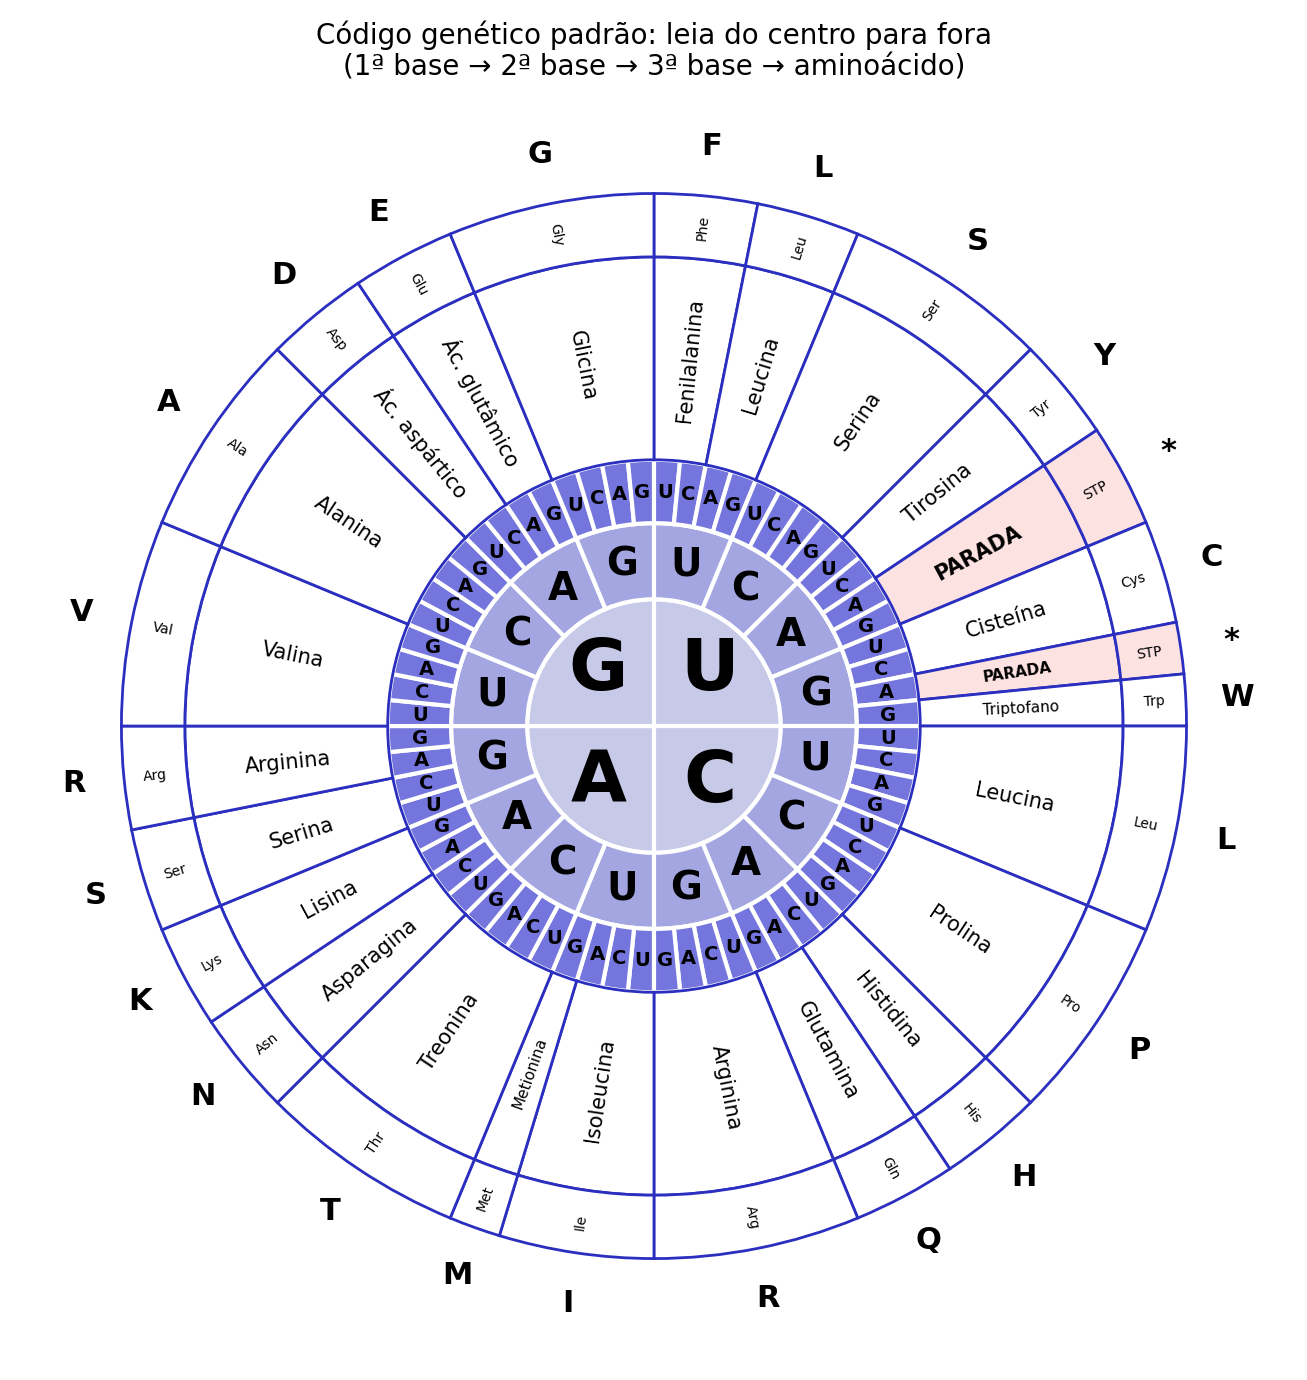

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "retina"
from matplotlib.patches import Wedge

# Código genético padrão (ordem U, C, A, G para cada posição do códon)
BASES = "UCAG"
AMINOACIDOS = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"

NOMES = {
    "F": ("Phe", "Fenilalanina"), "L": ("Leu", "Leucina"), "S": ("Ser", "Serina"),
    "Y": ("Tyr", "Tirosina"), "*": ("STP", "PARADA"), "C": ("Cys", "Cisteína"),
    "W": ("Trp", "Triptofano"), "P": ("Pro", "Prolina"), "H": ("His", "Histidina"),
    "Q": ("Gln", "Glutamina"), "R": ("Arg", "Arginina"), "I": ("Ile", "Isoleucina"),
    "M": ("Met", "Metionina"), "T": ("Thr", "Treonina"), "N": ("Asn", "Asparagina"),
    "K": ("Lys", "Lisina"), "V": ("Val", "Valina"), "A": ("Ala", "Alanina"),
    "D": ("Asp", "Ác. aspártico"), "E": ("Glu", "Ác. glutâmico"), "G": ("Gly", "Glicina"),
}

codons = [b1 + b2 + b3 for b1 in BASES for b2 in BASES for b3 in BASES]
codigo = dict(zip(codons, AMINOACIDOS))

# Raios dos anéis (de dentro para fora)
R_BASE1, R_BASE2, R_BASE3 = 1.0, 1.6, 2.1
R_NOME, R_ABREV, R_LETRA = 3.7, 4.2, 4.6

LARGURA = 360 / 64  # ângulo ocupado por cada códon


def angulos(inicio, n_codons):
    """Converte posição (em códons) em ângulos, girando no sentido horário a partir do topo."""
    theta2 = 90 - inicio * LARGURA
    theta1 = theta2 - n_codons * LARGURA
    return theta1, theta2


def texto_radial(eixo, angulo, raio, texto, **kwargs):
    """Escreve um texto alinhado ao raio, sempre legível (nunca de cabeça para baixo)."""
    x, y = raio * np.cos(np.radians(angulo)), raio * np.sin(np.radians(angulo))
    rotacao = angulo if np.cos(np.radians(angulo)) >= 0 else angulo + 180
    eixo.text(x, y, texto, rotation=rotacao, rotation_mode="anchor",
              ha="center", va="center", **kwargs)


def texto_reto(eixo, angulo, raio, texto, **kwargs):
    x, y = raio * np.cos(np.radians(angulo)), raio * np.sin(np.radians(angulo))
    eixo.text(x, y, texto, ha="center", va="center", **kwargs)


fig, eixo = plt.subplots(figsize=(7, 7))

# Anéis das três posições do códon
aneis = [(0, R_BASE1, 16, "#c7c9e8", 26), (R_BASE1, R_BASE2, 4, "#a3a6e0", 14),
         (R_BASE2, R_BASE3, 1, "#7476dd", 7)]

for r_int, r_ext, tamanho_bloco, cor, fonte in aneis:
    for i in range(0, 64, tamanho_bloco):
        t1, t2 = angulos(i, tamanho_bloco)
        eixo.add_patch(Wedge((0, 0), r_ext, t1, t2, width=r_ext - r_int,
                             facecolor=cor, edgecolor="white", linewidth=1.5))
        posicao = {16: 0, 4: 1, 1: 2}[tamanho_bloco]
        base = codons[i][posicao]
        raio_texto = (r_int + r_ext) / 2 if r_int > 0 else 0.62
        texto_reto(eixo, (t1 + t2) / 2, raio_texto, base, fontsize=fonte, fontweight="bold")

# Anéis dos aminoácidos: agrupa códons consecutivos que codificam o mesmo aminoácido
i = 0
while i < 64:
    letra = codigo[codons[i]]
    j = i
    while j < 64 and codigo[codons[j]] == letra:
        j += 1
    t1, t2 = angulos(i, j - i)
    meio = (t1 + t2) / 2
    abrev, nome = NOMES[letra]
    cor = "#fde2e2" if letra == "*" else "white"

    eixo.add_patch(Wedge((0, 0), R_NOME, t1, t2, width=R_NOME - R_BASE3,
                         facecolor=cor, edgecolor="#2b2fbf", linewidth=1))
    eixo.add_patch(Wedge((0, 0), R_ABREV, t1, t2, width=R_ABREV - R_NOME,
                         facecolor=cor, edgecolor="#2b2fbf", linewidth=1))

    tamanho = 7.5 if j - i > 1 else 5.5
    texto_radial(eixo, meio, (R_BASE3 + R_NOME) / 2, nome, fontsize=tamanho,
                 fontweight="bold" if letra == "*" else "normal")
    texto_radial(eixo, meio, (R_NOME + R_ABREV) / 2, abrev, fontsize=5)
    texto_reto(eixo, meio, R_LETRA, letra, fontsize=11, fontweight="bold")
    i = j

eixo.set_xlim(-5, 5)
eixo.set_ylim(-5, 5)
eixo.set_aspect("equal")
eixo.axis("off")
eixo.set_title("Código genético padrão: leia do centro para fora\n"
               "(1ª base → 2ª base → 3ª base → aminoácido)", fontsize=10)
plt.tight_layout()
plt.show()

**Figura 1.** Roda do código genético padrão, lida do centro para fora: o anel interno indica a primeira base do códon, o intermediário a segunda e o externo a terceira; os anéis seguintes mostram o aminoácido codificado (nome, abreviação de três letras e código de uma letra). Os códons de parada (UAA, UAG e UGA) estão destacados em vermelho. As bases estão representadas na forma de RNA (U, uracila, no lugar de T, timina), como nas colunas do conjunto de dados.

$ \ \ \ \ \ $ Se a escolha entre códons sinônimos fosse aleatória, todos seriam usados com frequências parecidas. Contudo esse cenário não é o que se observa, uma vez que cada organismo prefere alguns códons e evita outros, um fenômeno conhecido como viés de uso de códons - do inglês *codon usage bias (CUB)* - [[1]](#refs). Essa preferência, que funciona como um "código dentro do código", está ligada a diferentes fatores, como a tendência de cada genoma a acumular determinadas bases ao longo das mutações e a abundância dos RNAs transportadores (tRNAs) que leem cada códon, que afeta a velocidade e a precisão da tradução [[1, 2]](#refs). Por isso, embora não alterem a sequência de aminoácidos, trocas entre códons sinônimos podem influenciar a quantidade de proteína produzida e até a forma como ela se dobra.

$ \ \ \ \ \ $ Como essas preferências são moldadas pela história evolutiva de cada linhagem, organismos aparentados tendem a apresentar padrões de uso de códons semelhantes. Por esse motivo, o estudo do viés de uso de códons é usado para investigar relações evolutivas entre espécies, identificar genes transferidos entre organismos horizontalmente e compreender as pressões que atuam sobre os genomas, identificando as forças seletivas que impulsionam sua evolução [[1]](#refs).  

Tendo esses conceitos esclarecidos, é justamente essa relação entre uso de códons e história evolutiva que motiva a pergunta deste trabalho: se cada grupo de organismos possui uma espécie de assinatura própria de uso de códons, é possível identificar o grupo taxonômico de um organismo apenas a partir das frequências com que ele utiliza cada códon?

$ \ \ \ \ \ $ Para isso, serão induzidos diferentes modelos preditivos de aprendizado de máquina, isto é, funções com parâmetros que foram "aprendidos" por um algoritmo, que recebe dados de entrada (atributos) e usa esses dados para realizar uma previsão. Como o conjunto de dados possui um target conhecido - o grupo taxonômico do organismo - trata-se de um problema de aprendizado supervisionado. Além disso, como o target é uma categoria discreta, trata-se de um problema de classificação.

$ \ \ \ \ \ $ Dessa forma, será utilizado o conjunto de dados *Codon Usage*, disponível no UCI Machine Learning Repository [[3]](#refs). Ele reúne as frequências de uso de códons nas sequências codificantes de 13.028 organismos de diferentes grupos taxonômicos, compiladas a partir do banco de dados CUTG (*Codon Usage Tabulated from GenBank*) [[4]](#refs). O conjunto possui 69 colunas, descritas na Tabela 1.

**Tabela 1** - Descrição das colunas do conjunto de dados *Codon Usage* [[3]](#refs).

| Atributo | Nome | Descrição |
|---|---|---|
| 1 | `Kingdom` | Grupo taxonômico do organismo, representado por um código de 3 letras: `arc` (arqueias), `bct` (bactérias), `phg` (bacteriófagos), `plm` (plasmídeos), `pln` (plantas), `inv` (invertebrados), `vrt` (vertebrados), `mam` (mamíferos), `rod` (roedores), `pri` (primatas) e `vrl` (vírus). As categorias `arc` e `plm` não existem no CUTG original e foram curadas manualmente pelo autor do conjunto de dados. |
| 2 | `DNAtype` | Origem do DNA, representada por um número inteiro: 0 (genômico), 1 (mitocondrial), 2 (cloroplasto), 3 (cianela), 4 (plastídio), 5 (nucleomorfo), 6 (endossimbionte secundário), 7 (cromoplasto), 8 (leucoplasto), 9 (não disponível), 10 (proplastídio), 11 (apicoplasto) e 12 (cinetoplasto). |
| 3 | `SpeciesID` | Número inteiro que identifica a espécie dentro do arquivo de cada grupo taxonômico no banco CUTG. |
| 4 | `Ncodons` | Número total de códons contabilizados para o organismo. |
| 5 | `SpeciesName` | Nome da espécie (com as vírgulas do nome original substituídas por espaços). |
| 6 a 69 | `UUU`, `UUC`, `UUA`... | Frequência de uso de cada um dos 64 códons, isto é, o número de ocorrências do códon dividido por `Ncodons`, com 5 casas decimais. |

<a id="metodologia"></a>
## 2. Metodologia

$ \ \ \ \ \ $ Para responder à pergunta deste trabalho, foi seguido o fluxo usual de um projeto de aprendizado de máquina, com cuidado especial para evitar o vazamento de dados, isto é, para que nenhuma informação do conjunto de teste influencie a construção ou a escolha dos modelos. As etapas foram as seguintes:

1. **Preparação dos dados:** conversão das colunas de códons para valores numéricos, remoção de linhas mal formatadas e de organismos repetidos, seleção apenas das entradas de DNA genômico e reorganização das categorias do GenBank em seis grupos taxonômicos (arqueias, bactérias, vírus, plantas, invertebrados e vertebrados), que formam o *target*. Os atributos são as frequências dos 64 códons e o número total de códons (`Ncodons`), este último em escala logarítmica.
2. **Divisão em treino e teste:** separação estratificada em 80% para treino e 20% para teste, preservando a proporção de cada grupo. O conjunto de teste é guardado e usado uma única vez, no final.
3. **Análise exploratória:** estudo do conjunto de treino para entender a distribuição das classes, os padrões de uso de códons em cada grupo, a correlação entre os códons e a estrutura dos dados por meio da análise de componentes principais (PCA).
4. ***Baseline*:** indução de um modelo que sempre prevê a classe mais frequente, servindo como referência mínima de desempenho.
5. **Otimização de hiperparâmetros:** busca dos melhores hiperparâmetros de cada algoritmo com o `Optuna` [[5]](#refs), por validação cruzada no conjunto de treino.
6. **Comparação dos modelos:** comparação do melhor pipeline de cada algoritmo por validação cruzada e escolha do modelo com maior desempenho médio.
7. **Avaliação final:** medida do desempenho do modelo escolhido no conjunto de teste.
8. **Interpretação:** análise do desempenho em cada grupo taxonômico, identificação dos códons que mais influenciam as previsões e avaliação do modelo em gêneros que não estavam no treino, com discussão dos resultados à luz da Biologia.

$ \ \ \ \ \ $ Foram comparados cinco algoritmos de classificação, escolhidos por representarem estratégias diferentes de aprendizado: a **regressão logística**, um modelo linear; o ***k*-vizinhos mais próximos (*k*-NN)**, baseado nas distâncias entre os exemplos; a **árvore de decisão**, baseada em regras de divisão dos dados; e a **floresta aleatória** e o **HistGradientBoosting**, modelos de comitê que combinam várias árvores de decisão.

$ \ \ \ \ \ $ Cada algoritmo foi inserido em um **pipeline**, uma sequência de etapas formada por um normalizador, pela redução de dimensionalidade com PCA e pelo modelo. Como o normalizador e o PCA aprendem parâmetros a partir dos dados, o pipeline garante que eles sejam ajustados apenas com os dados de treino de cada etapa, o que impede que informações dos dados de validação ou de teste vazem para o modelo.

$ \ \ \ \ \ $ Os hiperparâmetros de cada pipeline, incluindo o tipo de normalizador e o número de componentes do PCA, foram otimizados com a biblioteca `Optuna` [[5]](#refs). Em vez de testar todas as combinações possíveis, o Optuna usa os resultados das tentativas anteriores para direcionar a busca para as regiões mais promissoras. Para cada algoritmo, foram testados 100 conjuntos de hiperparâmetros, cada um avaliado por validação cruzada estratificada com 5 folds no conjunto de treino: os dados de treino são divididos em 5 partes, e o modelo é treinado em 4 e avaliado na restante, repetindo o processo até que todas as partes tenham sido usadas na avaliação. A média dessas 5 avaliações é uma estimativa de desempenho mais confiável do que uma única divisão dos dados.

$ \ \ \ \ \ $ Como as classes são desbalanceadas, a métrica principal foi o **F1 macro**, que calcula o F1 de cada classe separadamente e faz a média simples entre elas, dando o mesmo peso a todas as classes. Assim, um modelo só obtém um bom resultado se identificar bem todos os grupos taxonômicos, e não apenas os mais frequentes. O pipeline com maior F1 macro médio na validação cruzada foi treinado com todo o conjunto de treino e avaliado uma única vez no conjunto de teste, onde também foram calculadas a acurácia e a matriz de confusão.

$ \ \ \ \ \ $ Por fim, o modelo escolhido foi interpretado de três formas: pela precisão, sensibilidade e F1 de cada grupo taxonômico; pela importância por permutação, que mede o quanto o desempenho cai quando os valores de cada atributo são embaralhados; e por uma divisão dos dados agrupada por gênero, em que nenhum gênero aparece ao mesmo tempo no treino e no teste, para verificar se o modelo consegue classificar organismos sem parentes próximos no treino.

$ \ \ \ \ \ $ Com relação à pontuação complementar, os tópicos abordados neste notebook são:

1. Comparou pelo menos 5 algoritmos/pipelines diferentes (sem contar o baseline): regressão logística, *k*-NN, árvore de decisão, floresta aleatória e HistGradientBoosting (seção [3.6](#opt));
2. Utilizou de forma correta validação cruzada para comparar diferentes algoritmos/pipelines (seção [3.7](#val));
3. Realizou redução de dimensionalidade nos dados, permitindo que o Optuna controlasse esse processo, isto é, otimizando o número de componentes do PCA como hiperparâmetro (seção [3.6](#opt));
4. Usou ferramenta de explicação de modelos (importância por permutação) para extrair informações sobre o modelo selecionado, com devida discussão sobre o resultado e sobre como a ferramenta de explicação funciona (seção [3.9.2](#interp));
5. Criou um nome, brasão e frase de efeito para representar sua casa perante o Rei Milu Iluminarius MLVI usando IA.

<a id="desenvolvimento"></a>
## 3. Desenvolvimento

<a id="pre"></a>
### 3.1 Preparação do Ambiente Inicial

$ \ \ \ \ \ $ Para o desenvolvimento deste trabalho, foram importadas diversas bibliotecas da linguagem Python (3.13.7) e definimos constantes, como a semente aleatória, que garantem a reprodutibilidade dos resultados, o número de folds da validação cruzada, a quantidade de conjuntos de hiperparâmetros a serem testados por algorimo, bem como a porcentagem dos dados reservados para o teste final.

$ \ \ \ \ \ $ Para a manipulação dos dados, utilizamos o `pandas`, que permite ler, organizar e limpar os dados em tabelas (`DataFrame`), e o `numpy`, responsável por operações matemáticas com vetores e matrizes. Os gráficos foram construídos com o `matplotlib` e o `seaborn`, sendo este último voltado para gráficos estatísticos, como boxplots e mapas de calor. A biblioteca `warnings` foi usada apenas para ocultar avisos que não afetam os resultados.

$ \ \ \ \ \ $ A otimização dos hiperparâmetros foi feita com o `optuna`, do qual importamos a função de criação dos estudos (`create_study`), o amostrador TPE (`TPESampler`) e os gráficos de acompanhamento da otimização (`vis`). A função `partial`, da biblioteca `functools`, foi utilizada para fixar os argumentos da função objetivo antes de passá-la ao Optuna.

$ \ \ \ \ \ $ As demais ferramentas vêm do `scikit-learn` [[6]](#refs). O módulo `model_selection` fornece a divisão em treino e teste (`train_test_split`), a formação dos *folds* estratificados (`StratifiedKFold`) e a validação cruzada (`cross_val_score`). Os módulos `pipeline` e `preprocessing` fornecem a construção dos *pipelines* (`make_pipeline`) e os três normalizadores utilizados (`StandardScaler`, `MinMaxScaler` e `MaxAbsScaler`), e o módulo `decomposition`, o PCA. Os modelos foram importados dos módulos `dummy` (baseline), `linear_model` (regressão logística), `neighbors` (k-NN), `tree` (árvore de decisão) e `ensemble` (floresta aleatória e HistGradientBoosting). Por fim, o módulo `metrics` fornece as métricas de desempenho (F1, acurácia e relatório de classificação) e a matriz de confusão, e o módulo `inspection`, a importância dos atributos por permutação, utilizada na interpretação do modelo escolhido.

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


import optuna
from functools import partial
from optuna import create_study
from optuna.samplers import TPESampler
import optuna.visualization.matplotlib as vis


import sklearn
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GroupShuffleSplit,
)

from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler
from sklearn.decomposition import PCA

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.inspection import permutation_importance


SEMENTE_ALEATORIA = 140          
TAMANHO_TESTE = 0.2    
NUM_TENTATIVAS = 100         
NUM_FOLDS = 5            
METRICA = "f1_macro"   

optuna.logging.set_verbosity(optuna.logging.WARNING)  # deixa a saída do Optuna mais limpa
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

$ \ \ \ \ \ $ Além das bibliotecas, definimos algumas constantes utilizadas ao longo de todo o notebook, de modo que, se for necessário alterar algum valor, basta modificá-lo em um único lugar. A `SEMENTE_ALEATORIA` fixa os sorteios realizados no trabalho, garantindo que os resultados sejam os mesmos a cada execução. As demais constantes correspondem a escolhas metodológicas, justificadas a seguir.

$ \ \ \ \ \ $ **Tamanho do conjunto de teste (`TAMANHO_TESTE = 0.2`).** Reservamos 20% dos organismos para o teste e 80% para o treino. Essa proporção busca um equilíbrio: o conjunto de treino precisa ser grande o suficiente para que os modelos aprendam os padrões de cada grupo, e o conjunto de teste precisa ser grande o suficiente para que a medida final de desempenho seja confiável. Com cerca de 9 mil organismos (após as etapas de limpezas), 20% correspondem a mais de 1.800 organismos no teste, incluindo cerca de 25 arqueias, o grupo menos numeroso. Um teste menor, de 10%, deixaria apenas cerca de 13 arqueias, tornando o desempenho nessa classe muito sensível a erros individuais; um teste maior reduziria os dados disponíveis para o treino sem ganho relevante na confiabilidade da avaliação.

$ \ \ \ \ \ $ **Número de tentativas (`NUM_TENTATIVAS = 100`).** Para cada algoritmo, o Optuna testa 100 conjuntos de hiperparâmetros, número mínimo exigido na proposta do trabalho. Como o Optuna concentra a busca nas regiões mais promissoras a partir das tentativas anteriores, esse número permite explorar bem o espaço de hiperparâmetros, o que pode ser verificado nos gráficos de histórico da otimização (seção [3.6](#opt)). Um número maior aumentaria bastante o custo computacional: com 5 algoritmos, 100 tentativas e 5 folds, a otimização já envolve o treino de 2.500 modelos.

$ \ \ \ \ \ $ **Número de *folds* (`NUM_FOLDS = 5`).** A escolha de 5 folds considera o tamanho do conjunto de dados e o desbalanceamento das classes. Como o conjunto de treino possui milhares de organismos, cada rodada da validação cruzada ainda treina os modelos com cerca de 80% desse conjunto, o que é suficiente. Um número maior de folds reduziria o tamanho de cada fold de validação: com 10 folds, por exemplo, o grupo das arqueias teria apenas cerca de 10 organismos em cada um, tornando o F1 dessa classe, e portanto o F1 macro, muito sensível a erros individuais. Além disso, o custo computacional da otimização dobraria.

$ \ \ \ \ \ $ **Métrica (`METRICA = "f1_macro"`).** Os modelos foram otimizados e comparados pelo F1 macro, que calcula o F1 de cada grupo taxonômico separadamente e faz a média simples entre eles. Como as classes são desbalanceadas, essa métrica dá o mesmo peso a todos os grupos, de modo que um modelo só obtém um bom resultado se identificar bem também os grupos menos numerosos. A acurácia, por outro lado, poderia ser alta mesmo para um modelo que acertasse apenas as classes mais frequentes. Ainda assim, a acurácia também é reportada na avaliação final, para comparação com o baseline e com outros trabalhos. A definição das duas métricas é apresentada na seção [3.5](#base).

<a id="carr"></a>
### 3.2 Carregamento, Limpeza e Escolha do Target 

#### 3.2.1 Convertendo o DataSet em um DataFrame

$ \ \ \ \ \ $ Inicialmente, para carregar os dados baixamos o DataSet "Codon Usage" disponibilizado no UCI Machine Learning Repository [[3]](#refs) e subimos o arquivo na mesma pasta deste Jupyter Notebook. Assim, foi possível converter um arquivo .csv em um dataframe - estrutura de dados tabulados - que pode ser manipulado utilizando a biblioteca `pandas`. O DataFrame em questão possui 13.028 exemplos (linhas) que são os organismos contemplados e 69 colunas, das quais retiraremos os atributos, também chamados de features, que utilizaremos. 

In [3]:
CAMINHO_DADOS = "codon_usage.csv"  

df = pd.read_csv(CAMINHO_DADOS, low_memory=False)
print(df.shape)
df.head()

(13028, 69)


,Kingdom,DNAtype,SpeciesID,Ncodons,SpeciesName,UUU,UUC,UUA,UUG,CUU,...,CGG,AGA,AGG,GAU,GAC,GAA,GAG,UAA,UAG,UGA
0,vrl,0,100217,1995,Epizootic haematopoietic necrosis virus,0.01654,0.01203,0.00050,0.00351,0.01203,...,0.00451,0.01303,0.03559,0.01003,0.04612,0.01203,0.04361,0.00251,0.00050,0.00000
1,vrl,0,100220,1474,Bohle iridovirus,0.02714,0.01357,0.00068,0.00678,0.00407,...,0.00136,0.01696,0.03596,0.01221,0.04545,0.01560,0.04410,0.00271,0.00068,0.00000
2,vrl,0,100755,4862,Sweet potato leaf curl virus,0.01974,0.0218,0.01357,0.01543,0.00782,...,0.00596,0.01974,0.02489,0.03126,0.02036,0.02242,0.02468,0.00391,0.00000,0.00144
3,vrl,0,100880,1915,Northern cereal mosaic virus,0.01775,0.02245,0.01619,0.00992,0.01567,...,0.00366,0.01410,0.01671,0.03760,0.01932,0.03029,0.03446,0.00261,0.00157,0.00000
4,vrl,0,100887,22831,Soil-borne cereal mosaic virus,0.02816,0.01371,0.00767,0.03679,0.01380,...,0.00604,0.01494,0.01734,0.04148,0.02483,0.03359,0.03679,0.00000,0.00044,0.00131


#### 3.2.2 Correção dos tipos das colunas dos códons 

$ \ \ \ \ \ $ Como os modelos de aprendizado de máquina só trabalham com dados numéricos, verificamos o tipo de dado das 64 colunas de frequência de códons, que estão a partir da sexta coluna do `DataFrame`. Das 64 colunas, 62 são do tipo `float64` (números decimais), como esperado para frequências. No entanto, 2 colunas foram lidas como `object` (texto), o que indica que algumas linhas contém valores não numéricos nessas colunas.

In [4]:
colunas_codons = df.columns[5:].tolist()
print("Número de colunas de códons:", len(colunas_codons))
print(df[colunas_codons].dtypes.value_counts())

Número de colunas de códons: 64
float64    62
object      2
Name: count, dtype: int64


$ \ \ \ \ \ $ Para corrigir esse problema, todas as colunas de códons foram convertidas para o tipo numérico com a função `pd.to_numeric`. O argumento `errors="coerce"` faz com que os valores que não podem ser convertidos em números sejam substituídos por `NaN` (valor ausente), em vez de interromper o código com um erro.

In [5]:
colunas_texto = df[colunas_codons].select_dtypes(include="object").columns.tolist()
print("Colunas lidas como texto:", colunas_texto)

df[colunas_codons] = df[colunas_codons].apply(pd.to_numeric, errors="coerce")

linhas_problema = df[df[colunas_codons].isna().any(axis=1)]
print("Linhas com valores não numéricos:", len(linhas_problema))
linhas_problema.iloc[:, :7]

Colunas lidas como texto: ['UUU', 'UUC']
Linhas com valores não numéricos: 2


,Kingdom,DNAtype,SpeciesID,Ncodons,SpeciesName,UUU,UUC
486,vrl,0,12440,1238,Non-A,NaN,0.04362
5063,bct,0,353569,1698,Salmonella enterica subsp. enterica serovar 4,NaN,NaN


$ \ \ \ \ \ $ As colunas lidas como texto foram [`UUU` e `UUC`]. Em seguida, identificamos as linhas que passaram a ter valores ausentes após a conversão. Foram encontradas 2 linhas com valores não numéricos, que correspondem a entradas mal formatadas no arquivo original. Como essas linhas representam uma parcela muito pequena do conjunto de dados e não é possível recuperar os valores corretos, elas foram removidas. Assim, após a remoção, o `DataFrame` passou a ter 13026 linhas.

In [6]:
df = df.dropna(subset=colunas_codons).reset_index(drop=True)
print(df.shape)

(13026, 69)


#### 3.2.3 Soma das frequências 

$ \ \ \ \ \ $ Como cada frequência corresponde à proporção de um códon em relação ao total de códons do organismo, a soma das 64 frequências de cada organismo deve ser igual a 1. Para verificar a integridade dos dados após a conversão para valores numéricos, calculamos essa soma para cada linha do DataFrame.

In [7]:
soma_frequencias = df[colunas_codons].sum(axis=1)
soma_frequencias.describe()

count    13026.000000
mean         0.999999
std          0.000031
min          0.999840
25%          0.999980
50%          1.000000
75%          1.000020
max          1.000170
dtype: float64

$ \ \ \ \ \ $ As somas variaram entre 0,99984 e 1,00017, com média praticamente igual a 1 e desvio padrão de 0,00003. As pequenas diferenças se devem ao arredondamento das frequências, registradas com 5 casas decimais: como cada valor pode ter um erro de até 0,000005, a soma das 64 frequências pode diferir de 1 em até 0,00032. Assim, os dados estão consistentes. Essa verificação também revela uma característica importante dos atributos, pois como as frequências sempre somam 1, qualquer uma delas pode ser obtida a partir das outras 63, ou seja, os atributos são redundantes entre si. Essa característica será retomada na etapa de pré-processamento, uma vez que como temos atributos redundantes, os dados são multicolinearmente perfeitos, justificando o uso de PCA posteriormente.

#### 3.2.4 Organismos com Poucos Códons

$ \ \ \ \ \ $ Quando o número total de códons (`Ncodons`) é pequeno, as estimativas de frequência ficam pouco confiáveis, pois muitos códons podem aparecer poucas vezes ou nenhuma apenas por acaso. Por isso, o autor do conjunto de dados descartou, previamente, os organismos com menos de 1000 códons. Para verificar se esse critério de fato condiz com os dados que temos, disponibilizados no UCI: o menor valor de `Ncodons` é 1000, e nenhum organismo possui um valor menor que esse. Assim, nenhum organismo precisou ser removido nesta etapa. Limites mais altos não foram adotados, pois eliminariam grande parte do conjunto de dados: com um limite de 3000 códons, por exemplo, seriam removidos 6.628 organismos, mais da metade do total.

In [8]:
for limite in [1000, 3000, 5000, 10000]:
    print(f"Ncodons < {limite}: {(df['Ncodons'] < limite).sum()} organismos")


MIN_CODONS = 1000
print()
print("Menor número de códons:", df["Ncodons"].min())
print(f"Organismos com menos de {MIN_CODONS} códons:", (df["Ncodons"] < MIN_CODONS).sum())

Ncodons < 1000: 0 organismos
Ncodons < 3000: 6628 organismos
Ncodons < 5000: 8479 organismos
Ncodons < 10000: 9957 organismos

Menor número de códons: 1000
Organismos com menos de 1000 códons: 0


#### 3.2.5 Espécies Duplicadas

$ \ \ \ \ \ $ Nesta etapa, verificamos se há organismos repetidos no conjunto de dados, já que exemplos duplicados podem cair tanto no treino quanto no teste e superestimar o desempenho dos modelos, o que constitui-se como um tipo de vazamento de dados.

In [9]:
print("SpeciesID repetidos:", df["SpeciesID"].duplicated().sum())
print("Linhas com frequências idênticas:", df.duplicated(subset=colunas_codons).sum())

SpeciesID repetidos: 660
Linhas com frequências idênticas: 40


$ \ \ \ \ \ $ Usando o método `duplicated()` foram encontradas 40 linhas com frequências de códons idênticas. Como essas linhas são cópias exatas umas das outras, elas foram removidas, restando 12.986 organismos.

$ \ \ \ \ \ $ Também foram encontrados 660 valores repetidos de `SpeciesID`, mas essas linhas não foram removidas, pois a mesma espécie pode ter mais de um tipo de DNA. Um mesmo organismo pode ter uma entrada para o genoma nuclear e outra para o genoma mitocondrial ou de cloroplasto. Esses genomas têm frequências de códons diferentes e, portanto, não são duplicatas. O `SpeciesID` não é único no conjunto de dados inteiro. Ele identifica a espécie apenas dentro do arquivo de cada reino no banco de dados CUTG. Assim, o mesmo número pode corresponder a espécies diferentes em reinos diferentes.

In [10]:
df = df.drop_duplicates(subset=colunas_codons).reset_index(drop=True)
print(df.shape)

(12986, 69)


$ \ \ \ \ \ $ O conjunto de dados contém entradas de diferentes tipos de DNA: além do DNA genômico (nuclear), há entradas de DNA de organelas, como mitocôndrias e cloroplastos, indicadas pela coluna `DNAtype`. Para entender como esses tipos de DNA se distribuem entre os grupos taxonômicos, construímos uma tabela de contingência com a função `pd.crosstab` do `pandas`. Essa função cruza duas colunas e conta quantas linhas existem para cada combinação de valores. Nesta tabela, cada linha corresponde a um grupo taxonômico (`Kingdom`), cada coluna a um tipo de DNA (`DNAtype`), e cada célula indica quantos organismos daquele grupo possuem aquele tipo de DNA.

$ \ \ \ \ \ $ Como já mencionado na Tabela 1 na [Introdução](#intro), os códigos de `DNAtype` correspondem a: 0 (genômico), 1 (mitocondrial), 2 (cloroplasto), 3 (cianela), 4 (plastídio), 5 (nucleomorfo), 6 (endossimbionte secundário), 7 (cromoplasto), 8 (leucoplasto), 9 (não disponível), 10 (proplastídio), 11 (apicoplasto) e 12 (cinetoplasto).

In [11]:
tabela_porcentagem = pd.crosstab(df["Kingdom"], df["DNAtype"], normalize="index") * 100
tabela_porcentagem.round(1)

DNAtype,0,1,2,3,4,5,6,7,9,11,12
Kingdom,,,,,,,,,,,
arc,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
bct,99.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
inv,68.6,30.5,0.1,0.0,0.2,0.1,0.0,0.0,0.0,0.1,0.4
mam,17.8,82.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
phg,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
plm,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
pln,60.7,6.1,31.9,0.1,1.1,0.0,0.0,0.0,0.1,0.0,0.0
pri,46.1,53.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
rod,27.4,72.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


$ \ \ \ \ \ $ A tabela mostra uma forte relação entre o tipo de DNA e o grupo taxonômico. Arqueias, bacteriófagos, plasmídeos e vírus possuem apenas entradas de DNA genômico (`DNAtype` igual a 0), e as bactérias possuem apenas duas entradas de outros tipos entre 2.908. Isso é esperado, pois esses organismos não possuem organelas como mitocôndrias e cloroplastos.

$ \ \ \ \ \ $ Entre os vertebrados, a situação é oposta, pois as entradas de DNA mitocondrial (`DNAtype` igual a 1) são a maioria em todos os grupos, correspondendo a cerca de 82% das entradas de mamíferos, aproximadamente 78% dos demais vertebrados, cerca de 73% dos roedores e 54% dos primatas. Nas plantas, o DNA genômico corresponde a cerca de 61% das entradas, seguido pelo DNA de cloroplasto, com aproximadamente 32%, e pelo DNA mitocondrial, com cerca de 6%. As plantas são praticamente o único grupo do Dataset com DNA de cloroplasto. Nos invertebrados, cerca de 31% das entradas são de DNA mitocondrial, e menos de 1% correspondem a organelas raras, como apicoplasto e cinetoplasto, encontradas em protistas parasitas. Os demais tipos de DNA possuem pouquíssimas entradas, e os tipos 8 (leucoplasto) e 10 (proplastídio) não aparecem no conjunto de dados.

$ \ \ \ \ \ $ Essa relação poderia comprometer o trabalho, pois se as entradas de organelas fossem mantidas, os modelos poderiam aprender atalhos como "DNA de cloroplasto indica planta" ou "DNA mitocondrial indica vertebrado", em vez de aprender o padrão de uso de códons de cada grupo que queremos observar. Além disso, as mitocôndrias utilizam variações do código genético padrão, de modo que seu uso de códons difere bastante do DNA nuclear do mesmo organismo. Por esses motivos, foram mantidas apenas as entradas de DNA genômico. Com isso, a coluna `DNAtype` passa a ter o mesmo valor em todas as linhas e deixa de ser utilizada como atributo.

In [12]:
df = df[df["DNAtype"] == 0].reset_index(drop=True)
print(df.shape)

(9240, 69)


$ \ \ \ \ \ $ Por fim, uma última limpeza no DataSet diz respeito às espécies repetidas. Na etapa de remoção de duplicatas, foram eliminadas apenas as linhas com frequências de códons exatamente iguais. No entanto, organismos muito semelhantes, como diferentes cepas de uma mesma bactéria, podem ter frequências ligeiramente diferentes e, por isso, não ser detectados como duplicatas. Se esses organismos ficassem divididos entre os conjuntos de treino e de teste, o modelo teria acesso, durante o treino, a exemplos quase idênticos aos do teste, o que superestimaria seu desempenho - tipo de vazamento de dado apresentado no Notebook Jupyter do Prof. Dr. Daniel Roberto Cassar "Vazamento de Dados" [[7]](#refs).  Como o `SpeciesID` não identifica as espécies de forma única no conjunto de dados, essa verificação foi feita pelo nome da espécie (`SpeciesName`), agora que restaram apenas as entradas de DNA genômico.

In [13]:
print("Nomes de espécie repetidos:", df["SpeciesName"].duplicated().sum())
df[df["SpeciesName"].duplicated(keep=False)].sort_values("SpeciesName").iloc[:, :6]

Nomes de espécie repetidos: 12


,Kingdom,DNAtype,SpeciesID,Ncodons,SpeciesName,UUU
2368,vrl,0,437060,1105,Ageratum yellow vein Hualian virus-[Taiwan,0.01538
2369,vrl,0,437061,1106,Ageratum yellow vein Hualian virus-[Taiwan,0.01447
2370,vrl,0,437062,1106,Ageratum yellow vein Hualian virus-[Taiwan,0.01447
2019,vrl,0,369954,1158,Cotton leaf curl Rajasthan virus - [India,0.01813
2020,vrl,0,369955,1140,Cotton leaf curl Rajasthan virus - [India,0.01754
2021,vrl,0,369956,1138,Cotton leaf curl Rajasthan virus - [India,0.01582
5155,bct,0,373045,1222,Escherichia coli O111,0.05155
3874,bct,0,168927,2086,Escherichia coli O111,0.01007
5283,bct,0,397453,1417,Escherichia coli O111,0.00988
5233,bct,0,386585,1639585,Escherichia coli O157,0.02215


In [14]:
df = df.drop_duplicates(subset="SpeciesName", keep="first").reset_index(drop=True)
print(df.shape)

(9228, 69)


$ \ \ \ \ \ $ Após essa seleção, restaram 9.228 organismos. 

#### 3.2.6 Definição do Target

$ \ \ \ \ \ $ Com todas as etapas de limpeza realizadas, garantindo a qualidade dos dados e evitando o vazamento de dados por exemplos repetidos, podemos definir o Target, isto é, o resultado que um modelo supervisionado retorna de acordo com os atributos fornecidos.  Neste trabalho, o target é o grupo taxonômico do organismo, informado na coluna `Kingdom`. 

In [15]:
df["Kingdom"].value_counts()

Kingdom
bct    2901
vrl    2813
pln    1522
inv     922
vrt     464
phg     218
arc     126
mam     102
pri      83
rod      59
plm      18
Name: count, dtype: int64

$ \ \ \ \ \ $  Apesar do nome, a coluna `Kingdom` não corresponde aos reinos da classificação biológica formal: ela reproduz as divisões do banco de dados CUTG, que seguem a organização do GenBank. Por isso, algumas categorias não são reinos (como vírus e bacteriófagos) e outras estão contidas umas nas outras: roedores e primatas são mamíferos, e todos são vertebrados, ou seja, deveriam ficar na categoria `vrt` que reúne os demais vertebrados. Além disso, após a limpeza, algumas dessas categorias ficaram com poucos exemplos, como os roedores (59 organismos) e os primatas (83 organismos), o que tornaria a avaliação dos modelos pouco confiável para essas classes.

$ \ \ \ \ \ $ Por esses motivos, as categorias foram reorganizadas em seis grupos taxonômicos: arqueias, bactérias, vírus (incluindo os bacteriófagos, que são vírus que infectam bactérias), plantas, invertebrados e vertebrados (reunindo mamíferos, roedores, primatas e os demais vertebrados). Optamos por excluir os plasmídeos, pois não são organismos, mas moléculas de DNA presentes no interior de bactérias, além de possuírem apenas 18 exemplos. Para facilitar a leitura dos resultados, os códigos de três letras foram substituídos pelos nomes dos grupos em português, armazenados na coluna `Grupo`, que, como já mencionado, será utilizada como target.

In [16]:
NOMES_GRUPOS = {
    "arc": "Arqueias",
    "bct": "Bactérias",
    "phg": "Vírus",         
    "vrl": "Vírus",
    "pln": "Plantas",
    "inv": "Invertebrados",
    "vrt": "Vertebrados",
    "mam": "Vertebrados",
    "rod": "Vertebrados",
    "pri": "Vertebrados",
}

logica = df["Kingdom"] != "plm"
df = df.loc[logica].reset_index(drop=True)

df["Grupo"] = df["Kingdom"].map(NOMES_GRUPOS)

df["Grupo"].value_counts()

Grupo
Vírus            3031
Bactérias        2901
Plantas          1522
Invertebrados     922
Vertebrados       708
Arqueias          126
Name: count, dtype: int64

$ \ \ \ \ \ $ A fim de demonstrar o quão desbalanceados os dados estão, o que influencia modelos como o Baseline, que prevê como resultado a categoria mais frequente, foi plotado um gráfico que apresenta a Distribuição dos organismos entre os grupos taxonômicos já citados.

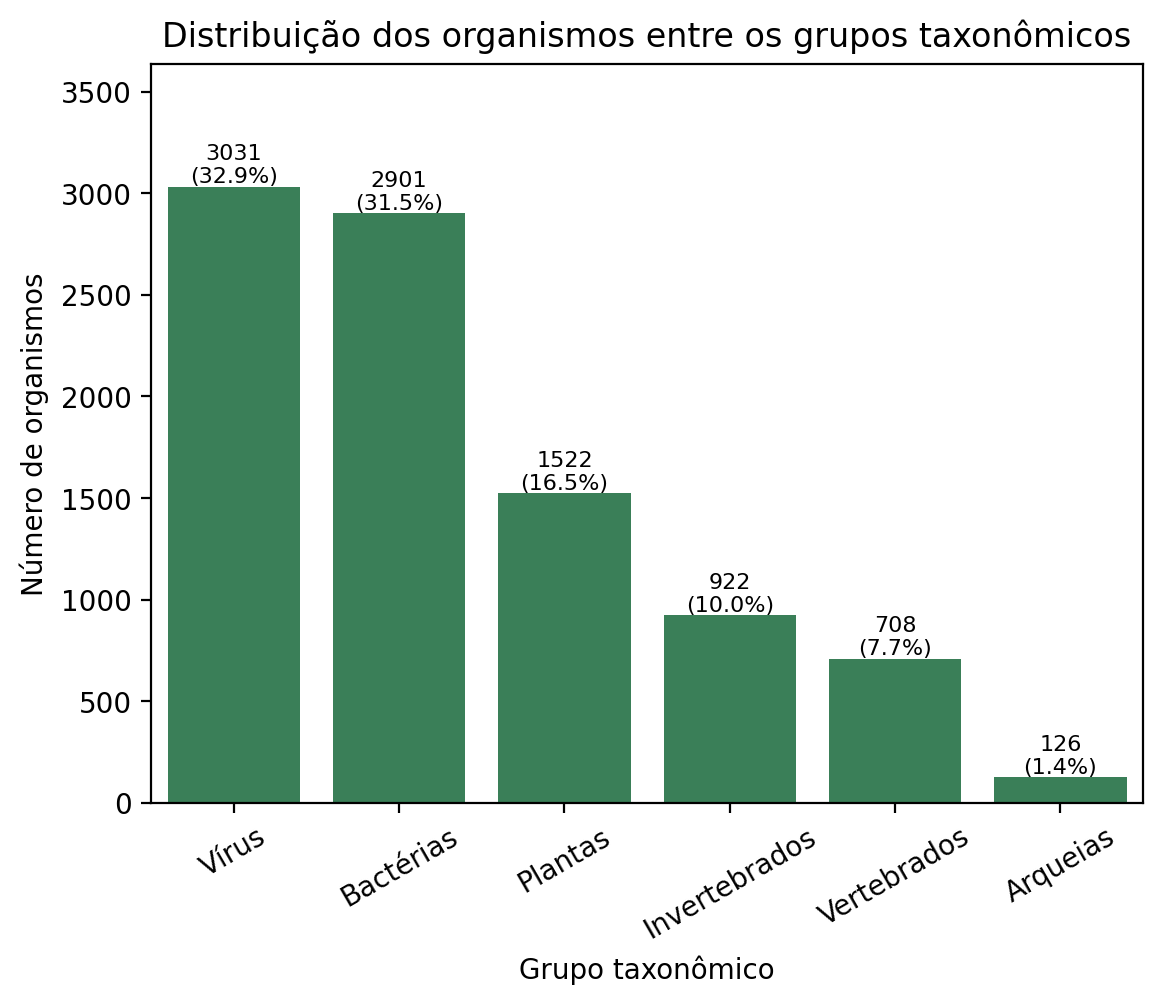

In [17]:
contagem = df["Grupo"].value_counts()
porcentagem = contagem / contagem.sum() * 100

eixo = sns.barplot(x=contagem.index, y=contagem.values, color = "seagreen")
eixo.bar_label(
    eixo.containers[0],
    labels=[f"{n}\n({p:.1f}%)" for n, p in zip(contagem.values, porcentagem.values)],
    fontsize=8,
)
eixo.set(
    xlabel="Grupo taxonômico",
    ylabel="Número de organismos",
    title="Distribuição dos organismos entre os grupos taxonômicos",
)
eixo.set_ylim(0, contagem.max() * 1.2)
plt.xticks(rotation=30);

$ \ \ \ \ \ $ O gráfico mostra que as classes são bastante desbalanceadas. Vírus (3.031 organismos, 32,9%) e bactérias (2.901, 31,5%) concentram juntos cerca de 64% dos dados, enquanto plantas (16,5%), invertebrados (10,0%) e vertebrados (7,7%) aparecem em menor quantidade. As arqueias formam o menor grupo, com apenas 126 organismos (1,4%), cerca de 24 vezes menos que os vírus.

$ \ \ \ \ \ $ Esse desbalanceamento reflete, em parte, o esforço de sequenciamento dos diferentes grupos: vírus e bactérias possuem genomas pequenos e foram amplamente sequenciados, enquanto as arqueias são um grupo menos estudado. Ele também traz consequências para a modelagem. Um modelo que previsse sempre a classe mais frequente acertaria cerca de 33% dos organismos sem ter aprendido nada, o que torna a acurácia uma métrica enganosa neste caso. Além disso, os modelos tendem a priorizar as classes mais numerosas, podendo ter dificuldade em identificar as arqueias.

$ \ \ \ \ \ $ Para lidar com esse problema, três estratégias foram adotadas ao longo do trabalho: a divisão em treino e teste foi feita de forma estratificada, preservando a proporção de cada grupo nos dois conjuntos; a métrica principal escolhida foi o F1 macro, que dá o mesmo peso a todas as classes; e o peso das classes foi incluído como hiperparâmetro dos modelos, permitindo que os erros nas classes menos numerosas tenham maior importância durante o treino.

$ \ \ \ \ \ $ Definimos, por fim, quais colunas serão utilizadas como atributos. Os atributos são as frequências dos 64 códons e o número total de códons (`Ncodons`), totalizando 65 atributos. As colunas `SpeciesID` e `SpeciesName` não foram utilizadas, por serem apenas identificadores dos organismos, assim como a coluna `DNAtype`, que passou a ter o mesmo valor em todas as linhas após a seleção do DNA genômico.

In [18]:
ATRIBUTOS = colunas_codons + ["Ncodons"]
TARGET = ["Grupo"]

print("Número de organismos (linhas):", len(df))
print("Número de atributos:", len(ATRIBUTOS))
print("Atributos:", ATRIBUTOS)
print()
print("Target:", TARGET[0])
print("Classes do target:", df["Grupo"].unique().tolist())

Número de organismos (linhas): 9210
Número de atributos: 65
Atributos: ['UUU', 'UUC', 'UUA', 'UUG', 'CUU', 'CUC', 'CUA', 'CUG', 'AUU', 'AUC', 'AUA', 'AUG', 'GUU', 'GUC', 'GUA', 'GUG', 'GCU', 'GCC', 'GCA', 'GCG', 'CCU', 'CCC', 'CCA', 'CCG', 'UGG', 'GGU', 'GGC', 'GGA', 'GGG', 'UCU', 'UCC', 'UCA', 'UCG', 'AGU', 'AGC', 'ACU', 'ACC', 'ACA', 'ACG', 'UAU', 'UAC', 'CAA', 'CAG', 'AAU', 'AAC', 'UGU', 'UGC', 'CAU', 'CAC', 'AAA', 'AAG', 'CGU', 'CGC', 'CGA', 'CGG', 'AGA', 'AGG', 'GAU', 'GAC', 'GAA', 'GAG', 'UAA', 'UAG', 'UGA', 'Ncodons']

Target: Grupo
Classes do target: ['Vírus', 'Arqueias', 'Bactérias', 'Plantas', 'Invertebrados', 'Vertebrados']


$ \ \ \ \ \ $ Por fim, os rótulos do target `Grupo` foram armazenados, na variável `ordem_labels`, utilizada posteriormente para garantir que a ordem das classes nas matrizes de confusão fosse sempre consistente ao longo do trabalho, por meio do método `.unique()`.

In [19]:
ordem_labels = sorted(df["Grupo"].unique())
print("Ordem dos grupos:", ordem_labels)

Ordem dos grupos: ['Arqueias', 'Bactérias', 'Invertebrados', 'Plantas', 'Vertebrados', 'Vírus']


<a id="sep"></a>
### 3.3 Separação dos Dados de Treino e Teste

$ \ \ \ \ \ $ Para avaliar o desempenho de um modelo de forma honesta, sem sobreajustá-lo, é necessário medi-lo em dados que não foram utilizados durante o seu treino. Caso contrário, o modelo poderia simplesmente ter memorizado os exemplos e aparentar um desempenho melhor do que o real. Por isso, seguindo a estratégia apresentada no Material Não Publicado do Prof. Dr. Daniel Roberto Cassar [[8]](#refs), os dados foram divididos em um conjunto de treino, utilizado para treinar e escolher os modelos, e um conjunto de teste, reservado para medir o desempenho do modelo escolhido uma única vez, ao final do trabalho.

$ \ \ \ \ \ $ Separamos 80% dos organismos ao conjunto de treino e 20% ao conjunto de teste. Como as classes são desbalanceadas, a divisão foi feita de forma estratificada, através do `stratify=df["Grupo"]`, isto é, preservando a proporção de cada grupo taxonômico nos dois conjuntos. Sem a estratificação, um grupo pouco numeroso, como o das arqueias, poderia ficar concentrado em apenas um dos conjuntos por acaso. Além disso, a semente aleatória, atribuída na [Preparação do Ambiente Inicial](#pre) foi fixada para que a divisão seja sempre a mesma a cada execução do notebook.

In [20]:
indices = df.index
indices_treino, indices_teste = train_test_split(
    indices,
    test_size=TAMANHO_TESTE,
    random_state=SEMENTE_ALEATORIA,
    stratify=df["Grupo"],
)

df_treino = df.loc[indices_treino]
df_teste = df.loc[indices_teste]

print("Treino:", df_treino.shape)
print("Teste:", df_teste.shape)

Treino: (7368, 70)
Teste: (1842, 70)


$ \ \ \ \ \ $ Dos 9.210 organismos, 7.368 foram destinados ao conjunto de treino e 1.842 ao conjunto de teste. Em seguida, separamos em cada conjunto os atributos (`X`) e o target (`y`), utilizando as listas `ATRIBUTOS` e `TARGET` definidas anteriormente.

In [21]:
X_treino = df_treino.reindex(ATRIBUTOS, axis=1)
y_treino = df_treino.reindex(TARGET, axis=1).values.ravel()

X_teste = df_teste.reindex(ATRIBUTOS, axis=1)
y_teste = df_teste.reindex(TARGET, axis=1).values.ravel()

print("X_treino:", X_treino.shape, "| y_treino:", y_treino.shape)
print("X_teste:", X_teste.shape, "| y_teste:", y_teste.shape)

X_treino: (7368, 65) | y_treino: (7368,)
X_teste: (1842, 65) | y_teste: (1842,)


In [22]:
proporcoes = pd.DataFrame({
    "Treino (%)": df_treino["Grupo"].value_counts(normalize=True) * 100,
    "Teste (%)": df_teste["Grupo"].value_counts(normalize=True) * 100,
})
proporcoes.round(1)

,Treino (%),Teste (%)
Grupo,,
Vírus,32.9,32.9
Bactérias,31.5,31.5
Plantas,16.5,16.5
Invertebrados,10.0,10.0
Vertebrados,7.7,7.7
Arqueias,1.4,1.4


$ \ \ \ \ \ $ A tabela confirma que a estratificação preservou a proporção de cada grupo taxonômico nos conjuntos de treino e de teste. A partir deste ponto, todas as análises e decisões de modelagem são realizadas apenas com o conjunto de treino. Vale destacar que a divisão foi feita por organismo, de modo que espécies aparentadas, como as de um mesmo gênero, podem estar presentes tanto no conjunto de treino quanto no de teste. As implicações dessa escolha para a interpretação do desempenho dos modelos serão discutidas na seção [3.9](#interp).

$ \ \ \ \ \ $ Além disso, dentro do conjunto de treino, a escolha dos hiperparâmetros e a comparação entre os modelos serão feitas por validação cruzada [[9]](#refs).

<a id="exp"></a>
### 3.4 Análise Exploratória

#### 3.4.1 Número de Códons por Grupo Taxonômico

$ \ \ \ \ \ $ Objetivando compreender melhor o conjunto de dados que trabalharemos, vamos utilizar algumas estratégias de análise exploratória, como uma visualização gráfica através de boxplots, possível graças à biblioteca `seaborn`. Esse gráfico mostra como o número total de códons (Ncodons) varia dentro de cada grupo taxonômico. Cada caixa corresponde a um grupo, e o eixo vertical mostra quantos códons foram contabilizados para cada organismo.

$ \ \ \ \ \ $ O Ncodons, biologicamente, indica nos fornece duas informações. Além de estar relacionada ao tamanho do genoma, por exemplo vírus tem genomas pequenos, com poucos genes, então tendem a ter poucos códons, o número de códons está relacionado com o quanto aquela espécie foi estudada. Um organismo modelo como é o caso da E. coli ou o ser humano que é extremamente pesquisado têm consideravelmente mais genes sequenciados do que uma espécie pouco conhecida. 

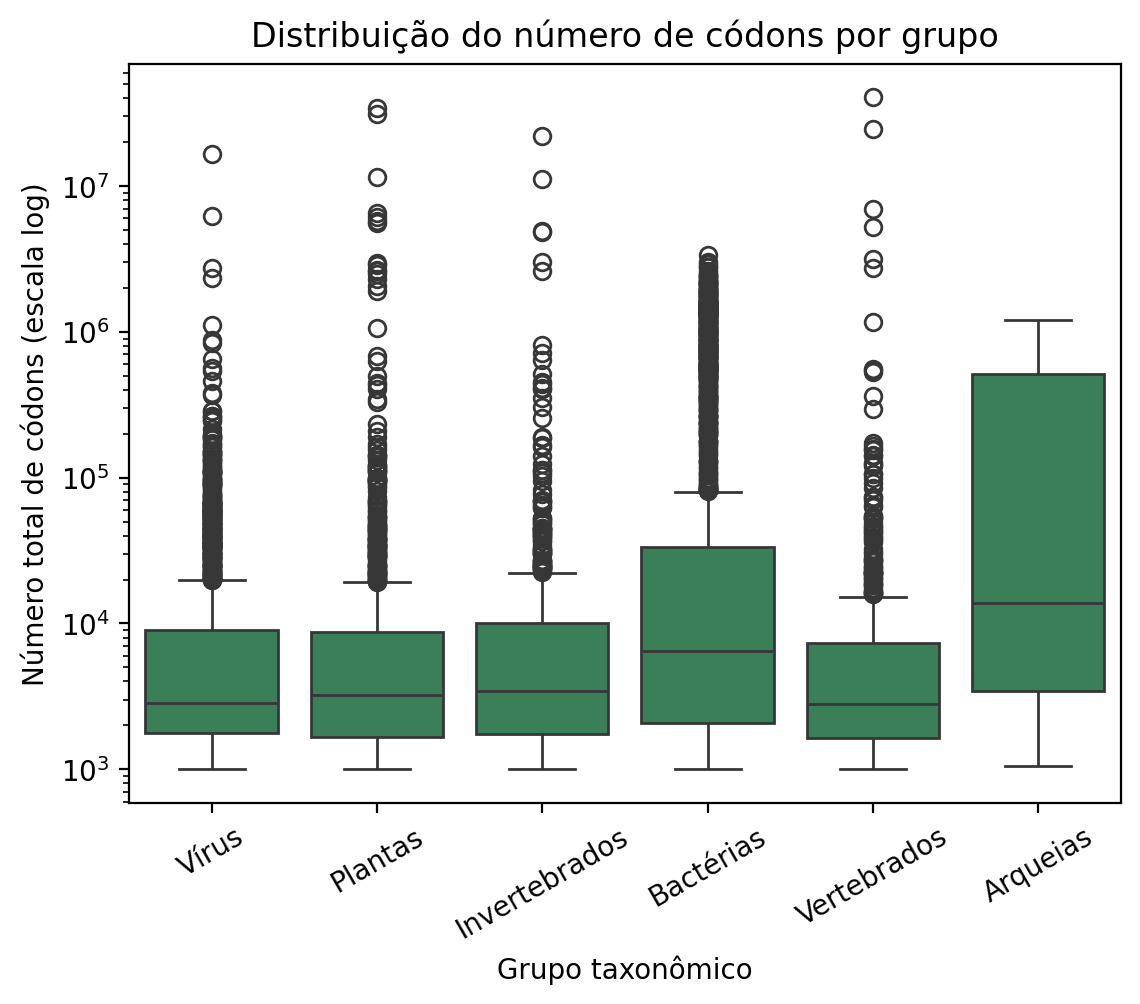

In [23]:
eixo = sns.boxplot(data=df_treino, x="Grupo", y="Ncodons", color="seagreen")
eixo.set_yscale("log")
eixo.set(
    xlabel="Grupo taxonômico",
    ylabel="Número total de códons (escala log)",
    title="Distribuição do número de códons por grupo",
)
plt.xticks(rotation=30);

$ \ \ \ \ \ $ Analisando os boxplots, é perceptível que todos têm como valor mínimo 1000 códons como já comprovado na seção de [Carregamento, Limpeza e Escolha do Target](#carr) Além disso, é evidente como quatro grupos taxonômicos têm distribuições muito parecidas. Vírus, plantas, invertebrados e vertebrados têm medianas próximas de 3.000 códons. Isso, embora possa parecer surpreendente, uma vez que os genomas de plantas e vertebrados são muito maiores que os de vírus, está relacionado com fato, já mencionado, de o Ncodons não medir o tamanho do genoma em si, mas quantas sequências codificantes da espécie estavam no GenBank. Dessa forma, para a maioria das plantas e dos animais, só alguns genes tinham sido sequenciados, e por isso eles têm tão poucos códons quanto um vírus.

$ \ \ \ \ \ $ Bactérias e arqueias apresentam valores mais altos, com medianas de cerca de 6.500 e 14.000 códons, respectivamente, e uma grande quantidade de organismos com centenas de milhares a milhões de códons. Isso é coerente com o fato de que muitos procariontes tiveram seus genomas completamente sequenciados, por serem pequenos e mais fáceis de sequenciar. Já os valores extremos observados entre os eucariontes, de dezenas de milhões de códons, provavelmente correspondem a organismos modelo, amplamente estudados.

$ \ \ \ \ \ $ Como as distribuições dos grupos se sobrepõem bastante, o `Ncodons` sozinho não é suficiente para distinguir os grupos taxonômicos, o que reforça a importância das frequências de códons para a classificação, e permite a análise objetivada pelo trabalho. 

$ \ \ \ \ \ $ Como optamos por utilizar a escala logarítmica no gráfico, pois Ncodons vai de 1.000 a dezenas de milhões, e, portanto, em uma escala comum, os grupos com poucos códons ficariam espremidos no fundo do gráfico e seria impossível compará-los, também iremos realizar essa transformação nos dados, tanto de treino quanto de teste.

In [24]:
X_treino = X_treino.assign(Ncodons=np.log10(X_treino["Ncodons"]))
X_teste = X_teste.assign(Ncodons=np.log10(X_teste["Ncodons"]))

X_treino["Ncodons"].describe()

count    7368.000000
mean        3.809441
std         0.781163
min         3.000000
25%         3.253822
50%         3.549064
75%         4.115527
max         7.609195
Name: Ncodons, dtype: float64

#### 3.4.2 Perfil do Uso de Códons por Grupo Taxonômico

$ \ \ \ \ \ $ Para comparar os padrões de uso de códons entre os grupos taxonômicos, calculamos a frequência média de cada códon dentro de cada grupo, utilizando apenas o conjunto de treino. O mapa de cores apresenta essas médias: cada linha corresponde a um grupo, cada coluna a um códon, e as cores variam do roxo (frequências baixas) ao amarelo (frequências altas).

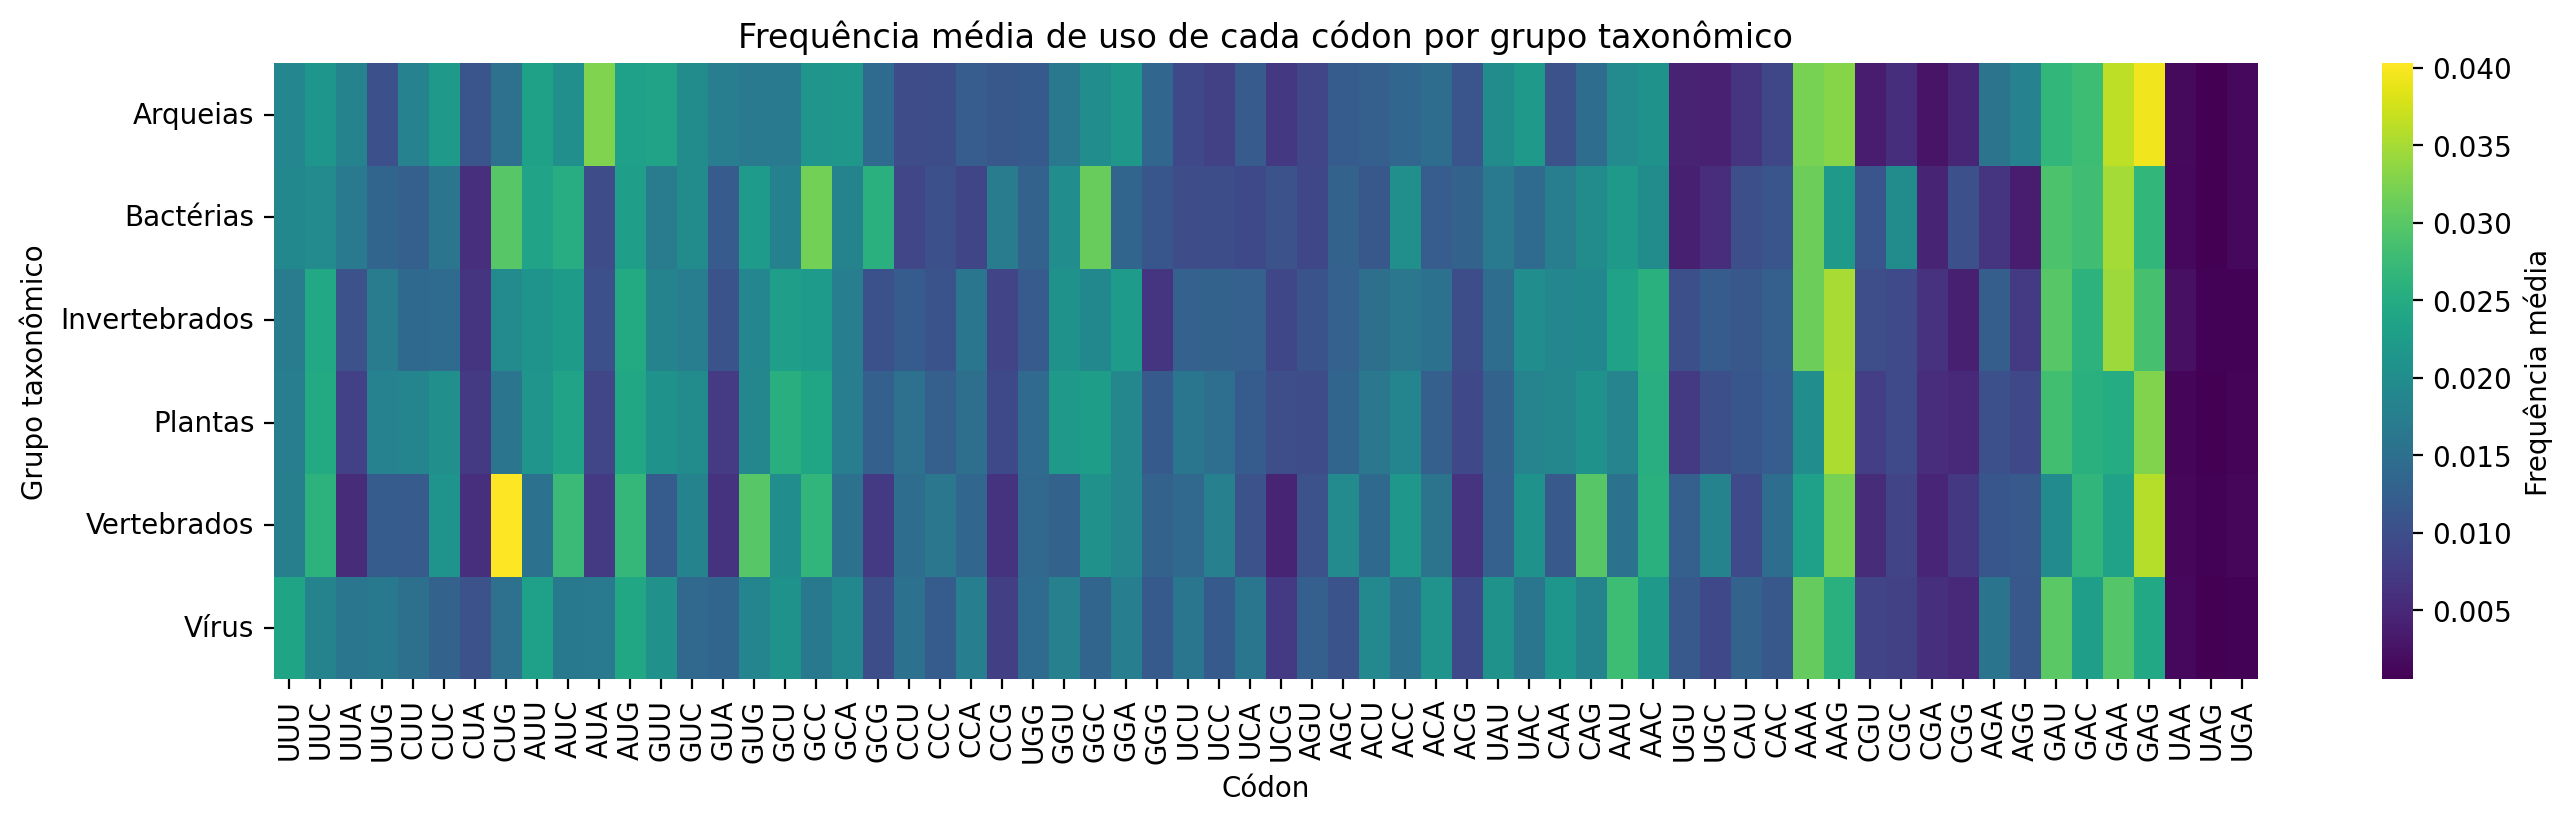

In [25]:
media_por_grupo = df_treino.groupby("Grupo")[colunas_codons].mean()

figura, eixo = plt.subplots(figsize=(16, 4))
sns.heatmap(
    media_por_grupo,
    cmap="viridis",
    ax=eixo,
    cbar_kws={"label": "Frequência média"},
)
eixo.set(
    xlabel="Códon",
    ylabel="Grupo taxonômico",
    title="Frequência média de uso de cada códon por grupo taxonômico",
);

$ \ \ \ \ \ $ Em todos os grupos, os códons de parada (UAA, UAG e UGA) são os menos frequentes. Isso já era esperado, já que cada gene possui apenas um códon de parada. Alguns códons, como AAA e AAG (lisina), GAA e GAG (ácido glutâmico) e GAU (ácido aspártico), são frequentes em quase todos os grupos, refletindo a abundância desses aminoácidos nas proteínas. Assim, o mapa reflete tanto a composição de aminoácidos das proteínas quanto a preferência por determinados códons sinônimos.

$ \ \ \ \ \ $ Apesar dessas semelhanças, cada grupo apresenta um perfil característico. Os vertebrados se destacam pelo uso muito elevado do códon CUG (leucina) e pela baixa frequência de códons que contêm a sequência CG, como UCG, CCG, ACG e CGA, padrão conhecido como depleção de CpG em genomas de vertebrados [[10]](#refs). As bactérias também utilizam bastante o CUG, além de GCC e GGC, enquanto raramente utilizam AGA e AGG para codificar a arginina. As arqueias apresentam uso elevado do códon AUA (isoleucina), pouco frequente nos demais grupos. Plantas e invertebrados possuem perfis semelhantes entre si, e os vírus apresentam o perfil mais homogêneo, possivelmente porque o grupo reúne vírus de hospedeiros muito diferentes, cujos padrões de uso de códons tendem a se misturar na média. Essas diferenças indicam que as frequências de códons carregam informações capazes de distinguir os grupos taxonômicos, o que motiva o uso desses atributos nos modelos de classificação.

#### 3.4.3 Uso de Códons Sinônimos: o exemplo da leucina

$ \ \ \ \ \ $ Para observar diretamente o viés de uso de códons, analisamos os seis códons sinônimos do aminoácido ramificado leucina (UUA, UUG, CUU, CUC, CUA e CUG). Para cada organismo, a frequência de cada um desses códons foi dividida pela soma das frequências dos seis, obtendo-se a proporção de uso de cada códon entre os códons da leucina. Dessa forma, o gráfico, feito com a biblioteca `Seaborn` mostra apenas a preferência por determinados códons sinônimos, independentemente da quantidade de leucina presente nas proteínas do organismo. Caso não houvesse nenhuma preferência, cada códon seria utilizado em aproximadamente 1/6 dos casos (linha tracejada).

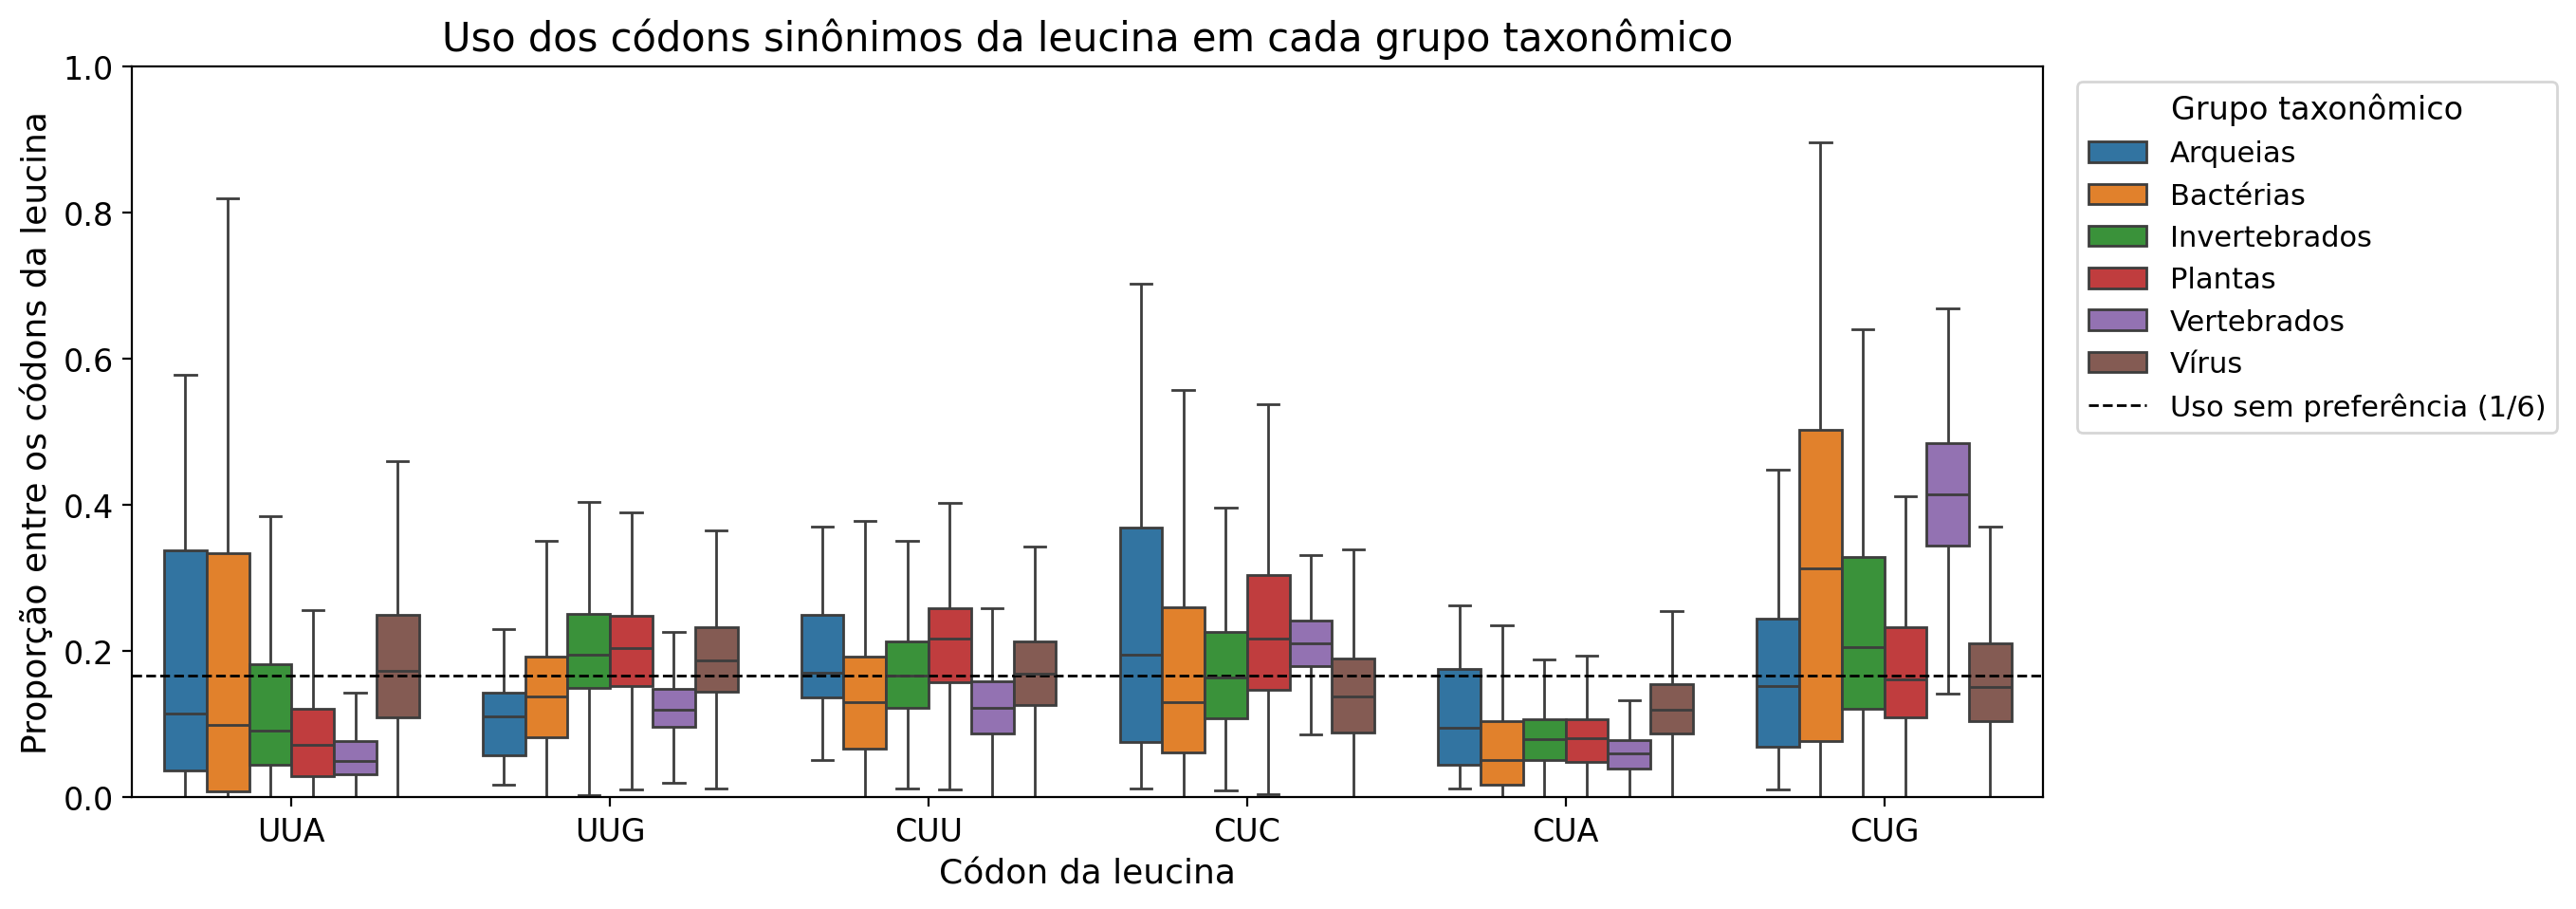

In [26]:
CODONS_LEUCINA = ["UUA", "UUG", "CUU", "CUC", "CUA", "CUG"]

uso_leucina = df_treino[CODONS_LEUCINA].div(df_treino[CODONS_LEUCINA].sum(axis=1), axis=0)
uso_leucina["Grupo"] = df_treino["Grupo"]

dados_longos = uso_leucina.melt(id_vars="Grupo", var_name="Códon", value_name="Proporção")

figura, eixo = plt.subplots(figsize=(13, 5))
sns.boxplot(
    data=dados_longos,
    x="Códon",
    y="Proporção",
    hue="Grupo",
    hue_order=sorted(dados_longos["Grupo"].unique()),
    showfliers=False,
    ax=eixo,
)
eixo.axhline(1 / 6, linestyle="--", color="black", linewidth=1, label="Uso sem preferência (1/6)")

eixo.set_title("Uso dos códons sinônimos da leucina em cada grupo taxonômico", fontsize=15)
eixo.set_xlabel("Códon da leucina", fontsize=13)
eixo.set_ylabel("Proporção entre os códons da leucina", fontsize=13)
eixo.tick_params(labelsize=12)
eixo.set_ylim(0, 1)

eixo.legend(
    title="Grupo taxonômico",
    fontsize=11,
    title_fontsize=12,
    bbox_to_anchor=(1.01, 1),
    loc="upper left",
);

$ \ \ \ \ \ $ Para ter os valores exatos das medianas, podemos utilizar o método `unstack` que transforma o resultado em uma tabela com os grupos nas linhas e os códons nas colunas. 

In [27]:
dados_longos.groupby(["Grupo", "Códon"])["Proporção"].median().unstack().round(2)

Códon,CUA,CUC,CUG,CUU,UUA,UUG
Grupo,,,,,,
Arqueias,0.10,0.20,0.15,0.17,0.12,0.11
Bactérias,0.05,0.13,0.31,0.13,0.10,0.14
Invertebrados,0.08,0.16,0.21,0.17,0.09,0.20
Plantas,0.08,0.22,0.16,0.22,0.07,0.20
Vertebrados,0.06,0.21,0.42,0.12,0.05,0.12
Vírus,0.12,0.14,0.15,0.17,0.17,0.19


$ \ \ \ \ \ $ Analisando tanto o gráfico quanto a tabela, é perceptível como os vertebrados apresentam o viés mais forte e mais consistente entre os organismos. O códon CUG corresponde a cerca de 40% dos códons de leucina, mais que o dobro do esperado sem preferência, enquanto UUA e CUA são raramente utilizados. Bactérias e arqueias apresentam grande variação dentro do próprio grupo, com organismos que preferem o códon UUA e outros que preferem o CUG, o que é coerente com a influência do conteúdo de GC do genoma observada na análise de correlação acima. Os vírus apresentam proporções mais próximas do uso uniforme, possivelmente por reunirem vírus de hospedeiros muito diferentes, de modo que as preferências se misturam entre os grupos. Já as plantas e os invertebrados apresentam perfis intermediários e semelhantes entre si. Em todos os grupos, o códon CUA é pouco utilizado. Ambos usam mais UUG, CUU e CUC e pouco UUA e CUA. Os invertebrados também usam bastante o CUG.

$ \ \ \ \ \ $ Esses resultados mostram que o viés de uso de códons varia entre os grupos taxonômicos, o que, mais uma vez, justifica o uso desses atributos para a classificação. Por outro lado, a grande variação dentro de alguns grupos, especialmente bactérias e arqueias, sugere que esses grupos podem ser mais difíceis de distinguir, o que verificaremos na avaliação dos modelos.

#### 3.4.4 Correlação entre os Códons 

$ \ \ \ \ \ $ Para verificar se os atributos carregam informações independentes ou redundantes, calculamos o coeficiente de correlação de Pearson entre as frequências de cada par de códons, utilizando apenas o conjunto de treino. O coeficiente de Pearson varia de -1 a 1. Valores próximos de 1 (em vermelho) indicam que dois códons tendem a ser mais frequentes nos mesmos organismos, valores próximos de -1 (em azul) indicam que, quando um códon é mais frequente, o outro tende a ser menos (correlação negativa), e valores próximos de 0 indicam ausência de relação linear.

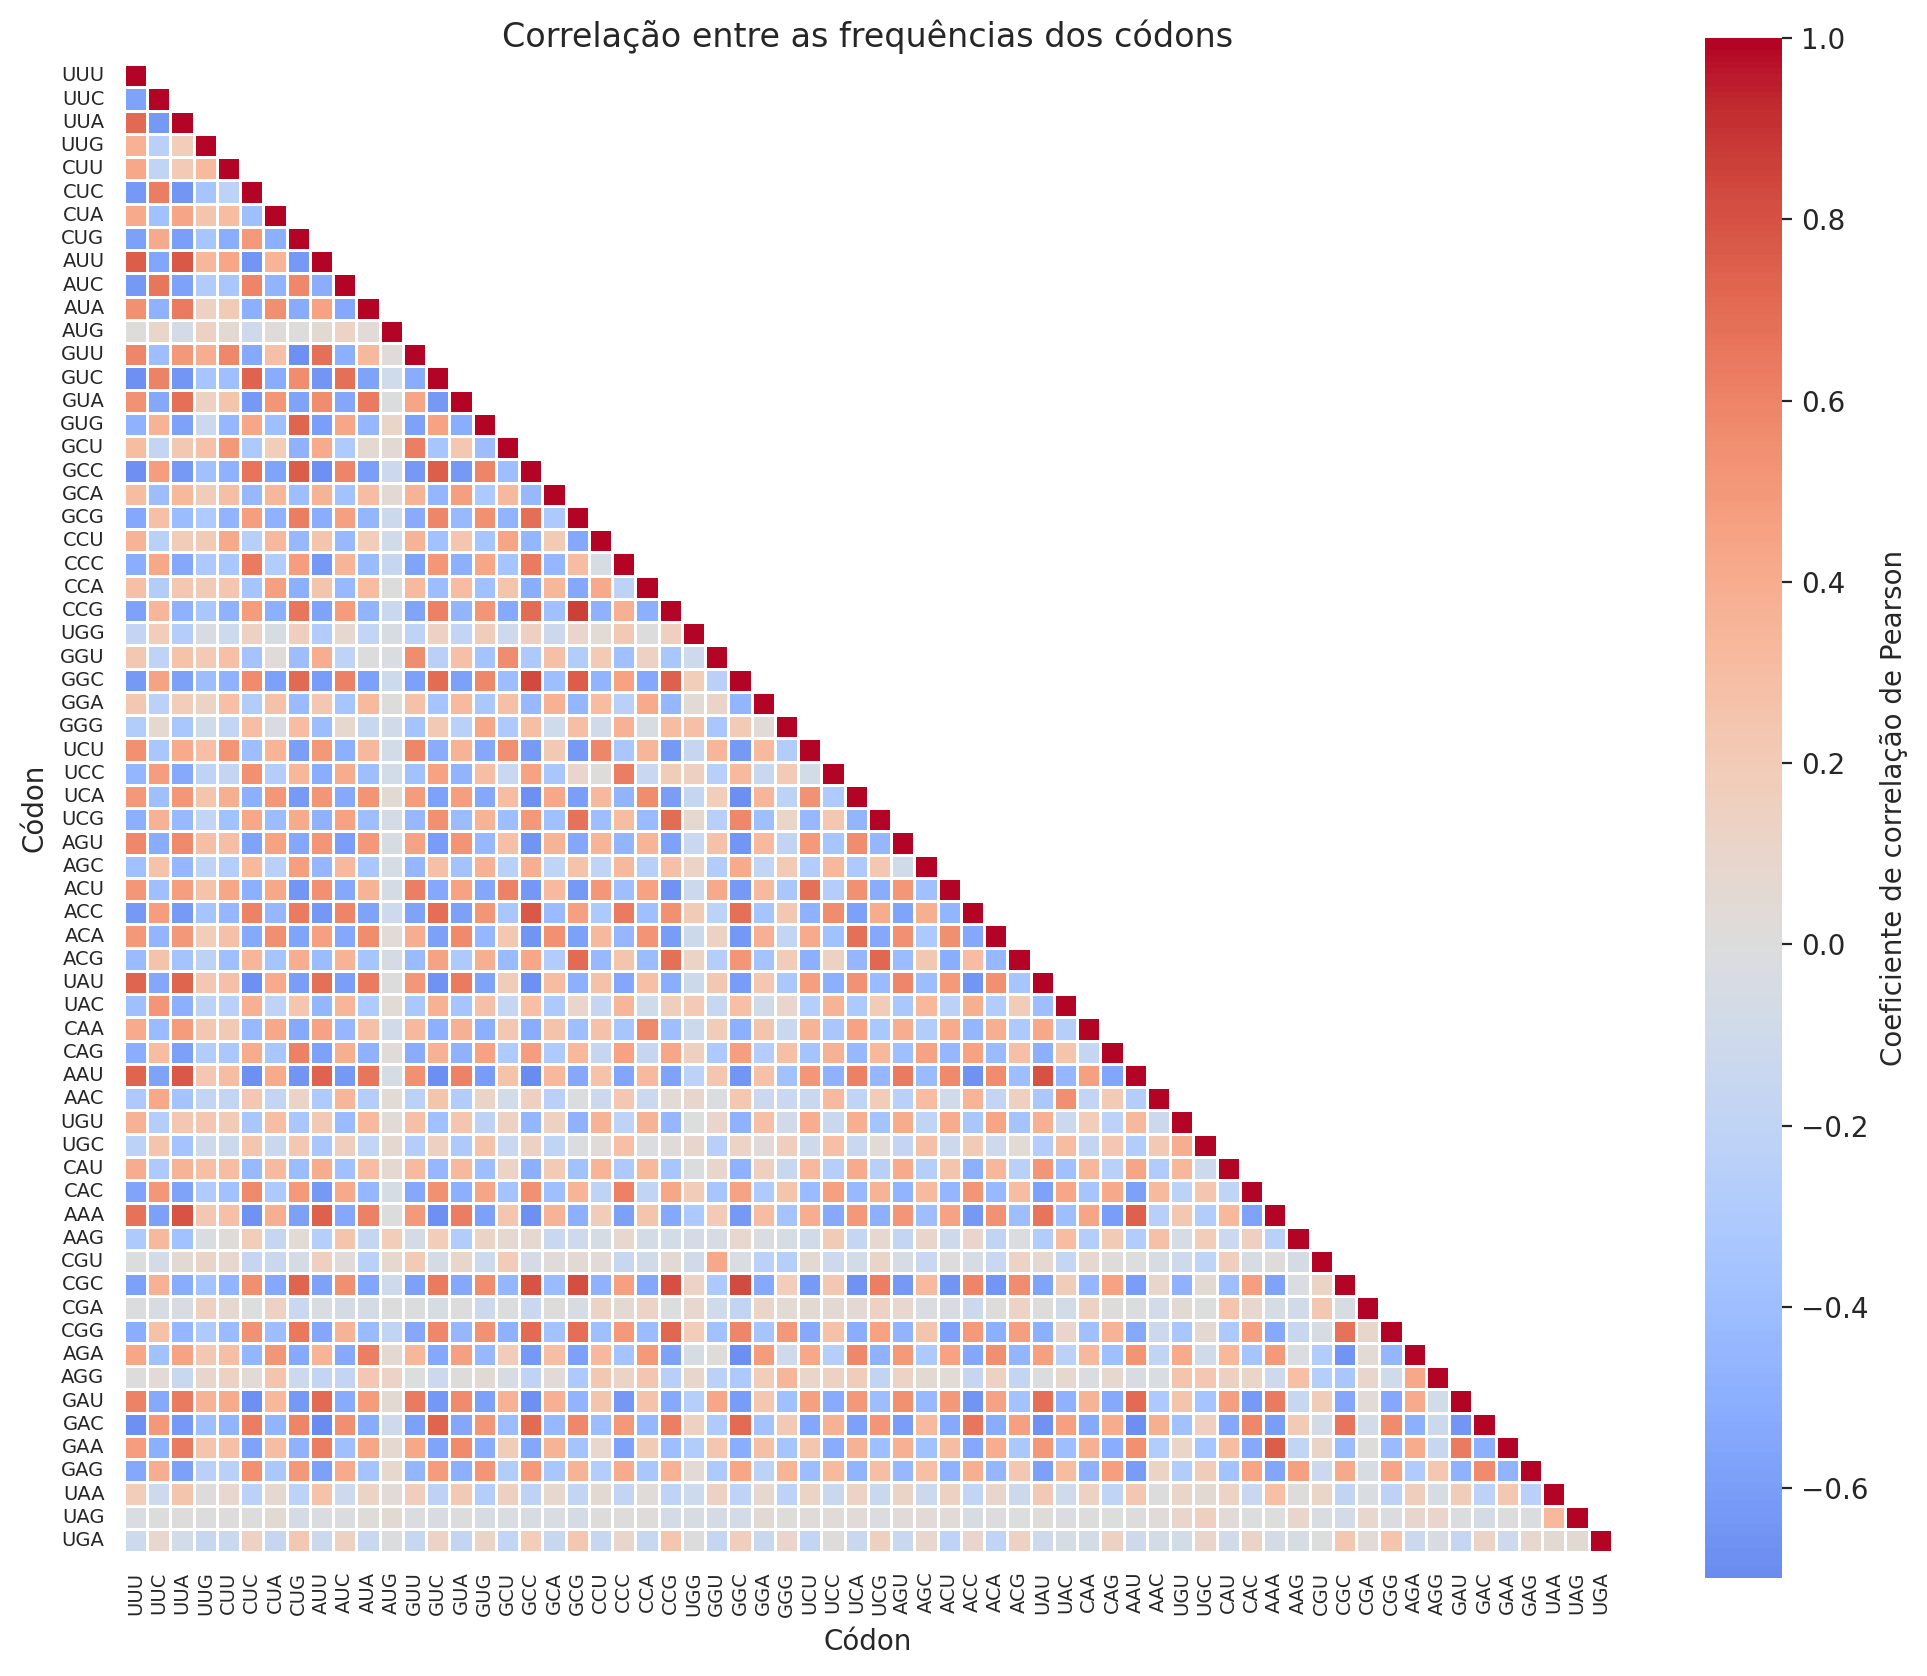

In [28]:
m_corr = X_treino[colunas_codons].corr()
mascara = np.triu(np.ones_like(m_corr, dtype=bool), k=1)
mapa_de_cor = "coolwarm"

with sns.axes_style("white"):
    figura, eixo = plt.subplots(figsize=(12, 10))
    sns.heatmap(
        m_corr,
        mask=mascara,
        cmap=mapa_de_cor,
        center=0,
        square=True,
        linewidths=0.5,
        ax=eixo,
        xticklabels=True,
        yticklabels=True,
        cbar_kws={"label": "Coeficiente de correlação de Pearson"},
    )
    eixo.tick_params(labelsize=7)
    eixo.set(
        xlabel="Códon",
        ylabel="Códon",
        title="Correlação entre as frequências dos códons",
    );

$ \ \ \ \ \ $ O gráfico mostra que muitos pares de códons apresentam correlações fortes, positivas ou negativas, o que indica que os atributos são redundantes entre si. Além disso, observa-se um padrão regular, semelhante a um tabuleiro de xadrez. Como os códons estão ordenados de modo que a terceira base alterna entre U, C, A e G, esse padrão indica que códons terminados em A ou U tendem a ser frequentes nos mesmos organismos, assim como os terminados em G ou C, enquanto os dois tipos apresentam correlação negativa entre si. Esse comportamento é coerente com a influência do conteúdo de GC do genoma sobre o uso de códons: organismos com genomas ricos em G e C tendem a preferir códons terminados nessas bases [[2]](#refs). Já os códons de parada apresentam correlações próximas de zero com os demais, pois aparecem apenas uma vez em cada gene.

$ \ \ \ \ \ $ A forte correlação entre os atributos, somada ao fato de que as frequências sempre somam 1, reforça que a informação contida nos 64 códons pode ser representada por um número menor de variáveis, o que motiva o uso da análise de componentes principais (PCA), que iremos introduzir. 

#### 3.4.5 Análise de Componentes Principais (PCA)

$ \ \ \ \ \ $ A análise de componentes principais (PCA) é uma técnica de redução de dimensionalidade que cria novas variáveis, chamadas componentes principais, a partir de combinações lineares dos atributos originais [[11, 12]](#refs). Essas componentes são obtidas a partir dos autovetores da matriz de covariância dos dados e são ordenadas de acordo com a variância que explicam: a primeira componente corresponde à direção em que os organismos mais diferem entre si, a segunda captura a maior parte da variância restante, e assim por diante. Além disso, as componentes não são correlacionadas entre si. Quando todas as componentes são mantidas, nenhuma informação é perdida. A redução de dimensionalidade ocorre quando apenas as primeiras componentes são utilizadas.

$ \ \ \ \ \ $ Neste trabalho, o PCA é utilizado em dois momentos. Nesta seção, ele é aplicado de forma exploratória, para avaliar o quanto os atributos são redundantes e como os grupos taxonômicos se distribuem no espaço das componentes principais. Na etapa de modelagem, o PCA é incluído no pipeline de cada modelo, com o número de componentes tratado como um hiperparâmetro otimizado pelo `Optuna`. Como o PCA busca as direções de maior variância, ele é sensível à escala dos atributos, por isso, os dados de treino foram normalizados - com o Normalizador Padrão que faz com que a média dos valores seja nula e o desvio padrão igual a 1 - antes da análise.

Componentes necessárias para explicar 90% da variância: 33


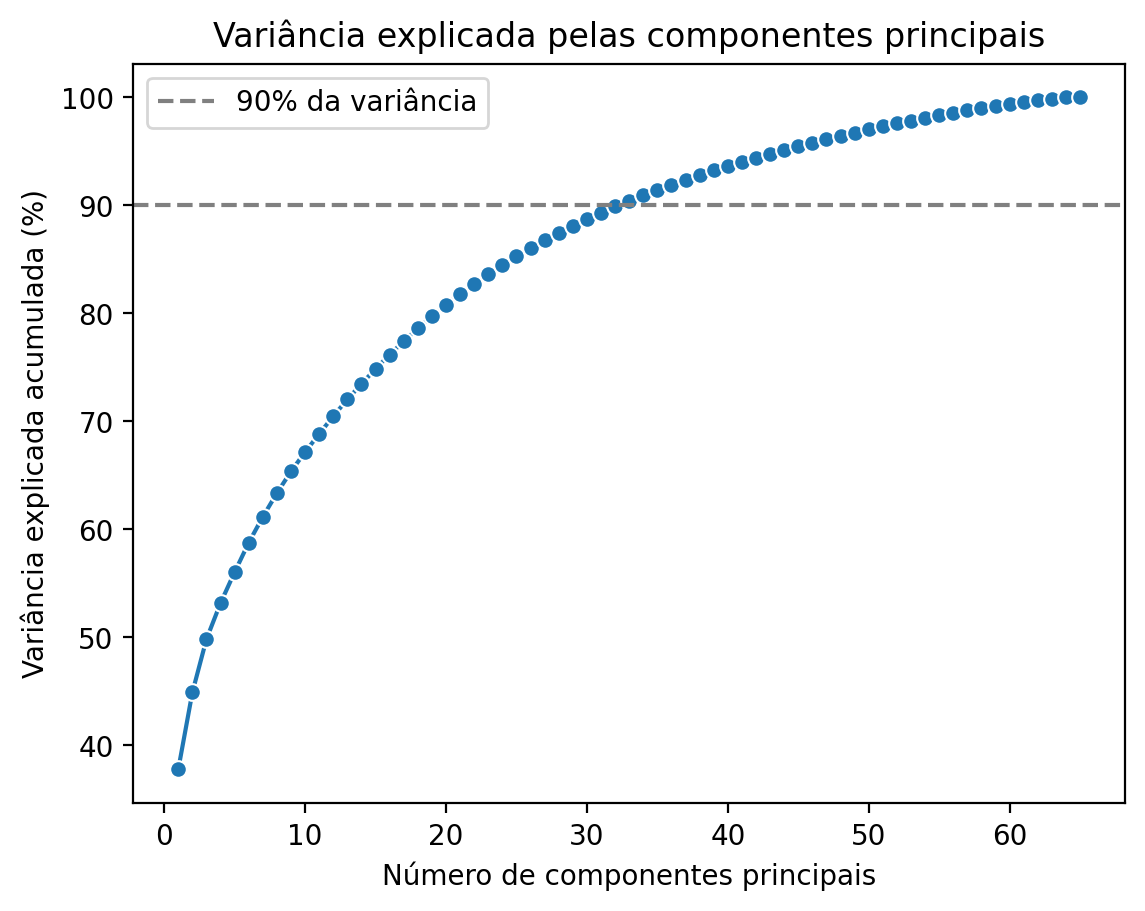

In [29]:
normalizador = StandardScaler()
normalizador.fit(X_treino)
X_treino_normalizado = normalizador.transform(X_treino)

pca = PCA()
pca.fit(X_treino_normalizado)

variancia_acumulada = np.cumsum(pca.explained_variance_ratio_) * 100
num_componentes_90 = np.argmax(variancia_acumulada >= 90) + 1
print(f"Componentes necessárias para explicar 90% da variância: {num_componentes_90}")

eixo = sns.lineplot(x=range(1, len(variancia_acumulada) + 1), y=variancia_acumulada, marker="o")
eixo.axhline(90, linestyle="--", color="gray", label="90% da variância")
eixo.set(
    xlabel="Número de componentes principais",
    ylabel="Variância explicada acumulada (%)",
    title="Variância explicada pelas componentes principais"
)
eixo.legend();

$ \ \ \ \ \ $ O gráfico mostra a variância explicada acumulada em função do número de componentes principais. A primeira componente explica sozinha um pouco menos de 40% da variância dos dados, e as duas primeiras juntas, cerca de 45%. A partir daí, cada nova componente acrescenta cada vez menos informação, e são necessárias 33 componentes para explicar 90% da variância, o que é aproximadamente metade dos 65 atributos originais. Isso confirma a redundância entre os atributos observada na análise de correlação, mas também indica que a informação não está concentrada em poucas componentes. Por esse motivo, em vez de fixar o número de componentes, essa escolha será deixada para o Optuna, no intervalo de 2 a 65 componentes.

$ \ \ \ \ \ $ Para facilitar a visualização e o entendimento do PCA, vamos projetar os organismos contemplados nas duas primeiras componentes principais:

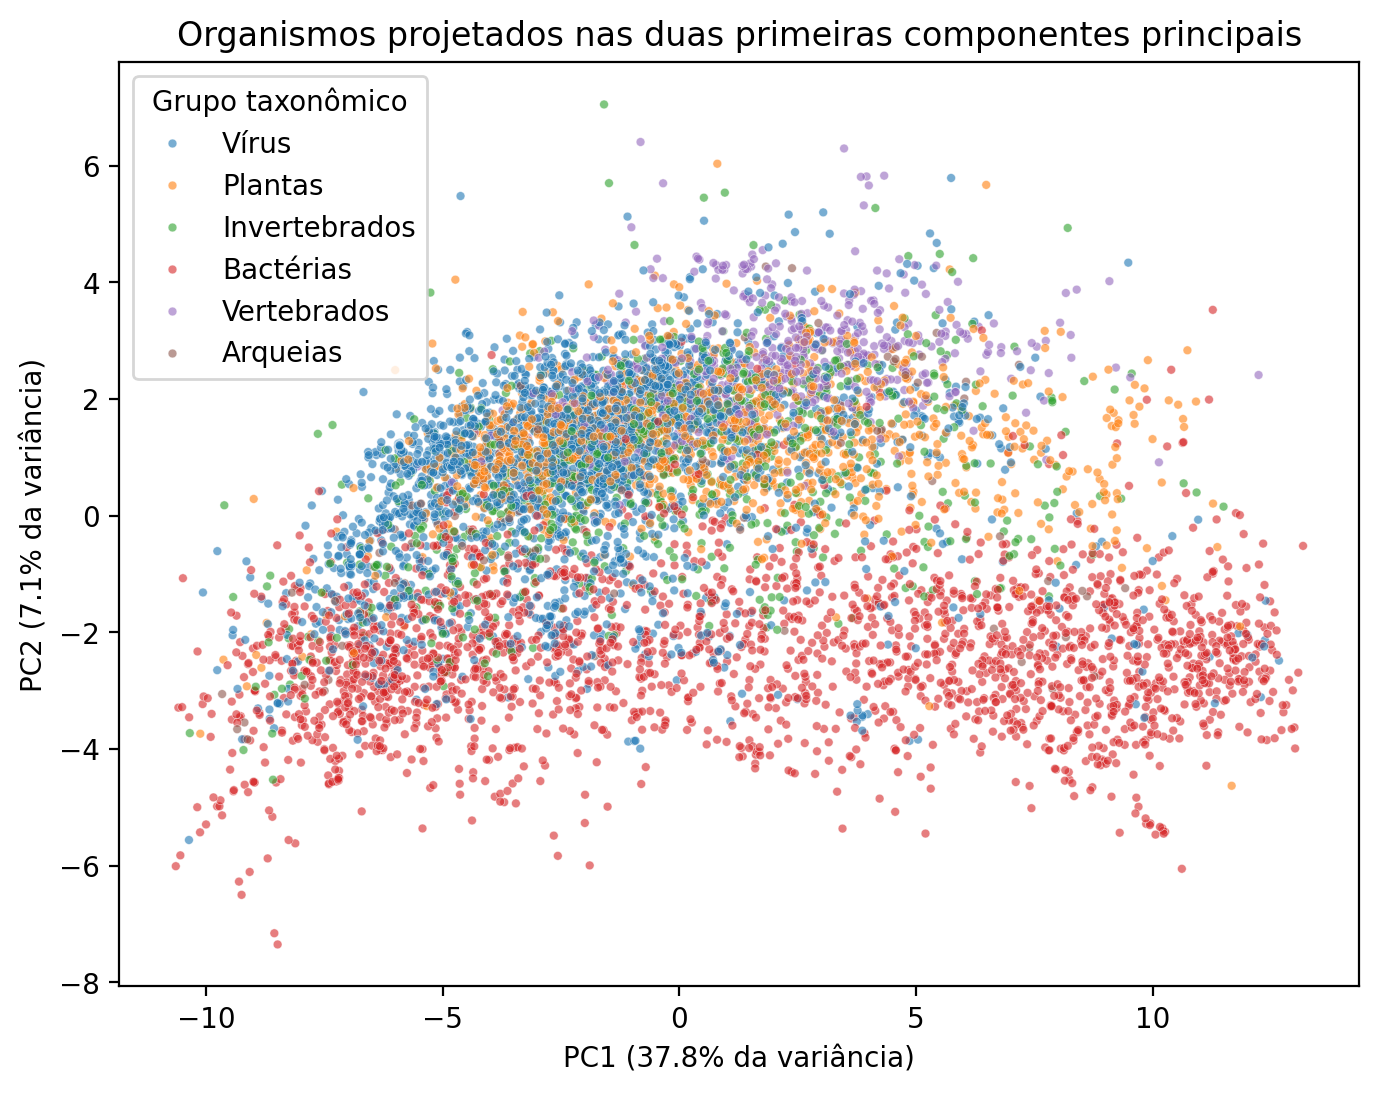

In [30]:
componentes = pca.transform(X_treino_normalizado)
variancia = pca.explained_variance_ratio_ * 100

figura, eixo = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=componentes[:, 0], y=componentes[:, 1], hue=y_treino, s=10, alpha=0.6, ax=eixo)
eixo.set(
    xlabel=f"PC1 ({variancia[0]:.1f}% da variância)",
    ylabel=f"PC2 ({variancia[1]:.1f}% da variância)",
    title="Organismos projetados nas duas primeiras componentes principais",
)
eixo.legend(title="Grupo taxonômico");

$ \ \ \ \ \ $ Observa-se que as bactérias se concentram principalmente na região de valores negativos da segunda componente, separando-se parcialmente dos demais grupos. Ao mesmo tempo, as bactérias se distribuem ao longo de toda a primeira componente, o que é coerente com a grande variação no uso de códons observada dentro desse grupo e sugere que a primeira componente esteja relacionada ao conteúdo de GC do genoma. Os vertebrados ocupam uma região própria, na parte superior do gráfico, enquanto vírus, plantas e invertebrados se sobrepõem bastante. As arqueias, por serem pouco numerosas, ficam praticamente encobertas pelos demais grupos e dispersas pelo gráfico.

$ \ \ \ \ \ $ Como as duas primeiras componentes explicam apenas cerca de 45% da variância, é esperado que vários grupos se sobreponham nessa projeção. Os modelos de classificação, por sua vez, utilizam um número maior de componentes e podem identificar fronteiras de decisão mais complexas. Ainda assim, o gráfico sugere que a distinção entre vírus, plantas e invertebrados pode ser mais difícil, o que será verificado na avaliação dos modelos.

<a id="base"></a>
### 3.5 Modelo Baseline

$ \ \ \ \ \ $ Com toda a parte preparatória tendo sido feita, os dados terem sido separados em treino e teste corretamente evidando vazamento de dados, e a análise exploratória concluída, permitindo um conhecimento mais aprofundado sobre o DataSet, podemos começar a induzir os modelos através de algoritmos conhecidos de Aprendizado de Máquina

$ \ \ \ \ \ $ Antes de induzir qualquer modelo mais complexo, podemos induzir o Modelo Baseline, também chamado de dummy, linha de base ou modelo fictício [[13]](#refs). O Baseline é um modelo mais simples que é utilizado para comparar o desempenho de modelos mais complexos. Empregando a estratégia da classe majoritária, o classificador realiza suas previsões atribuindo sempre a categoria mais frequente observada no conjunto de treinamento, ou seja, a moda do target, que nesse caso é o grupo dos vírus.  Seguindo a mesma estratégia que será utilizada para os demais modelos, seu desempenho foi estimado por validação cruzada estratificada com 5 folds no conjunto de treino.

In [31]:
modelo_baseline = DummyClassifier(strategy="most_frequent")

f1_baseline = cross_val_score(
    modelo_baseline, X_treino, y_treino, scoring="f1_macro", cv=NUM_FOLDS
)
acuracia_baseline = cross_val_score(
    modelo_baseline, X_treino, y_treino, scoring="accuracy", cv=NUM_FOLDS
)

print(f"F1 macro do baseline: {f1_baseline.mean() * 100:.1f}% ± {f1_baseline.std() * 100:.1f}%")
print(f"Acurácia do baseline: {acuracia_baseline.mean() * 100:.1f}% ± {acuracia_baseline.std() * 100:.1f}%")

F1 macro do baseline: 8.3% ± 0.0%
Acurácia do baseline: 32.9% ± 0.0%


$ \ \ \ \ \ $ Para avaliar todos os modelos a seguir, inclusive o baseline, foram utilizadas duas métricas: a acurácia e o F1 macro. Ambas são calculadas a partir da comparação entre as classes previstas pelo modelo e as classes verdadeiras, organizada na matriz de confusão. Para uma classe considerada "positiva", essa comparação gera quatro situações:

| | Previsto: positivo | Previsto: negativo |
|---|---|---|
| **Real: positivo** | VP | FN |
| **Real: negativo** | FP | VN |

$ \ \ \ \ \ $ Os verdadeiros positivos (VP) e os verdadeiros negativos (VN) são acertos; os falsos positivos (FP) são organismos de outras classes atribuídos à classe positiva, e os falsos negativos (FN) são organismos da classe positiva que o modelo não identificou. Como este trabalho possui seis classes, cada uma delas é considerada, por vez, a classe positiva, e as demais, negativas. Para as arqueias, por exemplo, os FN são as arqueias classificadas em outros grupos, e os FP são os organismos de outros grupos classificados como arqueias.

$ \ \ \ \ \ $ A **acurácia** é a proporção de organismos classificados corretamente [[14]](#refs):

$$
\text{Acurácia} = \frac{\text{número de previsões corretas}}{\text{número total de previsões}}
$$

$ \ \ \ \ \ $ Apesar de ser simples e intuitiva, a acurácia pode ser enganosa quando as classes são desbalanceadas, pois um modelo que acerte apenas as classes mais frequentes pode obter um valor alto mesmo sem identificar as classes menos numerosas.

$ \ \ \ \ \ $ O **F1 macro** contorna esse problema. Para cada classe, calculam-se duas medidas: a **precisão**, que indica, entre os organismos que o modelo atribuiu a determinado grupo, a proporção que realmente pertence a ele; e a **sensibilidade** (*recall*), que indica, entre os organismos que pertencem a determinado grupo, a proporção que o modelo identificou corretamente:

$$
\text{Precisão} = \frac{VP}{VP + FP} \qquad \qquad \text{Sensibilidade} = \frac{VP}{VP + FN}
$$

$ \ \ \ \ \ $ O **F1** de cada classe combina essas duas medidas por meio de sua média harmônica:

$$
F_1 = 2 \cdot \frac{\text{precisão} \cdot \text{sensibilidade}}{\text{precisão} + \text{sensibilidade}}
$$

$ \ \ \ \ \ $ A média harmônica só é alta quando a precisão e a sensibilidade são altas ao mesmo tempo: um modelo que atribui muitos organismos a um grupo pode encontrar todos os seus membros (sensibilidade alta), mas errará muito ao fazê-lo (precisão baixa), o que reduz o F1. Por fim, o **F1 macro** é a média simples do F1 das seis classes [[15]](#refs), de modo que todos os grupos taxonômicos têm o mesmo peso no resultado, independentemente do número de organismos. Assim, um modelo só obtém um F1 macro alto se classificar bem todos os grupos, inclusive os menos numerosos, como as arqueias. Ambas as métricas variam de 0 a 1 (ou de 0% a 100%), e valores maiores indicam melhor desempenho.

$ \ \ \ \ \ $ Com essas definições, agora podemos interpretar os resultados do baseline, que obteve acurácia de 32,9% e F1 macro de 8,3%. A acurácia corresponde exatamente à proporção de vírus no conjunto de treino: como o modelo prevê sempre a classe majoritária, ele acerta todos os vírus e erra todos os demais organismos. Para os vírus, a sensibilidade é de 100%, mas a precisão é de apenas 32,9%, o que resulta em um F1 de cerca de 49%, para as outras cinco classes, nenhum organismo é previsto, e o F1 é zero. A média dos seis valores resulta no F1 macro de 8,3%, que revela que o modelo não é capaz de identificar nenhum dos outros grupos. Essa diferença entre as duas métricas ilustra por que a acurácia não é adequada para dados desbalanceados e justifica a escolha do F1 macro como métrica principal.

$ \ \ \ \ \ $ O desvio padrão nulo entre os folds também é esperado: como a validação cruzada é estratificada, cada fold possui a mesma proporção de vírus, e o baseline obtém exatamente o mesmo resultado em todos eles. Esses valores servem como referência mínima para os modelos induzidos a seguir.

<a id="opt"></a>
### 3.6 Algoritmos, Pipeline e Otimização de Hiperparâmetros

$ \ \ \ \ \ $ Nesta seção, são induzidos e otimizados os modelos de classificação comparados neste trabalho. Foram escolhidos cinco algoritmos que representam estratégias diferentes de aprendizado: a regressão logística, um modelo linear; o k-vizinhos mais próximos (k-NN), baseado nas distâncias entre os organismos; a árvore de decisão, baseada em regras de divisão dos dados; e dois modelos de comitê formados por várias árvores, a floresta aleatória, em que as árvores são independentes e votam, e o HistGradientBoosting, em que as árvores são treinadas em sequência, cada uma corrigindo os erros das anteriores. Comparar estratégias diferentes permite avaliar qual tipo de modelo melhor captura os padrões de uso de códons.

$ \ \ \ \ \ $ A seção está organizada da seguinte forma. Primeiro, apresentamos o conceito de hiperparâmetro e a biblioteca `Optuna`, utilizada para otimizá-los (seção 3.6.1). Em seguida, descrevemos os elementos comuns a todos os algoritmos: o pipeline, que reúne a normalização, a redução de dimensionalidade com PCA e o modelo (seção 3.6.2), e a função objetivo, que avalia cada conjunto de hiperparâmetros por validação cruzada (seção 3.6.3). Depois, cada algoritmo é apresentado em uma subseção própria, contendo o seu funcionamento, os hiperparâmetros otimizados e a justificativa dos intervalos escolhidos, a execução da otimização e a discussão dos resultados (seções 3.6.4 a 3.6.8). Por fim, a seção 3.6.9 resume a otimização dos cinco algoritmos.

#### 3.6.0 Hiperparâmetros e o Optuna

$ \ \ \ \ \ $ Para otimizar os hiperparâmetros utilizando `Optuna`, utilizaremos como base o Material Didático não publicado do Prof. Dr. Daniel Roberto Cassar "Otimização de hiperparâmetros com optuna" [[16]](#refs). O optuna é uma biblioteca de otimização de hiperparâmetros que aceita tanto parâmetros numéricos (como o número de vizinhos do k-NN) quanto categóricos (tipo de normalizador, por exemplo). Diferentemente da busca em grade, que testa todas as combinações possíveis através de um produto cartesiano dos hiperparâmetros, e da busca aleatória, que sorteia combinações sem critério, o optuna usa os resultados das tentativas anteriores para escolher as próximas, concentrando a busca nas regiões mais promissoras, o que consiste no amostrador TPE (Tree-structured Parzen Estimator).

$ \ \ \ \ \ $ No Optuna, cada conjunto de hiperparâmetros testado é chamado de tentativa (trial), e o conjunto de todas as tentativas de um algoritmo forma um estudo (study). Ao final de cada estudo, são apresentados dois gráficos: o histórico da otimização, em que cada ponto corresponde a uma tentativa e a linha indica o melhor F1 macro encontrado até aquele momento, permitindo verificar se a busca se estabilizou, bem como a importância dos hiperparâmetros, que indica quais deles mais influenciaram o desempenho do modelo.

#### 3.6.1 Pré-Processamento no Pipeline

$ \ \ \ \ \ $ Antes de otimizar os hiperparâmetros, definimos as etapas de pré-processamento que farão parte do pipeline de cada modelo: a normalização dos dados e a redução de dimensionalidade com PCA [[17]](#refs). 

$ \ \ \ \ \ $ Essas etapas aprendem parâmetros a partir dos dados (como a média e o desvio padrão de cada atributo, no caso da normalização padrão, e as direções das componentes, no caso do PCA) e, por isso, foram incluídas no pipeline, que garante que sejam ajustadas apenas com os dados de treino de cada etapa da validação cruzada, evitando o vazamento de dados.

$ \ \ \ \ \ $ A função `cria_etapas_preprocessamento` deixa o optuna escolher o tipo de normalizador (padrão, mínimo e máximo ou máximo absoluto) e o número de componentes principais mantidas, de 2 a 65. Com 65 componentes, o PCA não reduz a dimensionalidade, apenas rotaciona os eixos, assim, o optuna também pode concluir que a redução não é vantajosa para determinado modelo. Essa função está sendo definida aqui, pois é utilizada por todos os cinco algoritmos, evitando a repetição do código.

In [32]:
NORMALIZADORES = {
    "padrao": StandardScaler,
    "min_max": MinMaxScaler,
    "max_abs": MaxAbsScaler,
}

def cria_etapas_preprocessamento(trial):
    """Cria as etapas de pré-processamento escolhidas pelo Optuna."""

    nome_normalizador = trial.suggest_categorical("normalizador", list(NORMALIZADORES))
    normalizador = NORMALIZADORES[nome_normalizador]()

    num_componentes = trial.suggest_int("num_componentes_pca", 2, len(ATRIBUTOS))
    pca = PCA(n_components=num_componentes)

    return [normalizador, pca]

#### 3.6.3 Função objetivo

$ \ \ \ \ \ $ A função objetivo é a função que o optuna busca otimizar. A cada tentativa, ela cria um modelo com os hiperparâmetros sugeridos, avalia seu desempenho por validação cruzada no conjunto de treino e retorna a média do F1 macro (métrica escolhida) entre os folds. A função foi adaptada do material disponibilizado em aula sobre o `optuna` [[16]](#refs) em dois pontos: como otimizaremos cinco algoritmos, ela recebe como argumento a função que cria cada modelo (`cria_instancia_modelo`), e, como o objetivo é maximizar o F1 macro, os estudos foram criados com `direction="maximize"`.

In [33]:
def funcao_objetivo(trial, X, y, num_folds, cria_instancia_modelo):
    """Função objetivo do optuna.

    Args:
      trial: objeto tipo Trial do optuna.
      X: atributos do conjunto de treino.
      y: target do conjunto de treino.
      num_folds: número de folds da validação cruzada.
      cria_instancia_modelo: função que cria o modelo a partir do trial.

    Returns:
      Média do F1 macro na validação cruzada.
    """

    modelo = cria_instancia_modelo(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring=METRICA,
        cv=num_folds,
    )

    return metricas.mean()

#### 3.6.4 Regressão Logística

$ \ \ \ \ \ $ Apesar do nome, a regressão logística é um algoritmo de classificação, que calcula uma combinação linear dos atributos para cada classe e transforma esses valores em probabilidades, atribuindo cada organismo à classe de maior probabilidade [[14]](#refs). Por ser um modelo linear, ela só consegue separar as classes por meio de fronteiras de decisão lineares (planos, no espaço dos atributos).

In [34]:
def cria_instancia_reglog(trial):
    """Cria uma instância do modelo de regressão logística.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "C": trial.suggest_float("C", 1e-3, 1e3, log=True),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        # argumentos fixos
        "max_iter": 2000,
    }

    modelo = make_pipeline(
        *cria_etapas_preprocessamento(trial),
        LogisticRegression(**parametros),
    )

    return modelo

$ \ \ \ \ \ $ Foram otimizados dois hiperparâmetros, além do normalizador e do número de componentes do PCA. O `C` controla a regularização, isto é, a penalização de coeficientes muito grandes: valores pequenos de `C` impõem uma regularização forte, que simplifica o modelo e reduz o risco de sobreajuste, enquanto valores grandes permitem que o modelo se ajuste mais aos dados. Como esse hiperparâmetro varia em várias ordens de grandeza, ele foi amostrado em escala logarítmica, entre 0,001 e 1000. O peso das classes (`class_weight`) pode ser nenhum ou balanceado. Nesse último caso, os erros nas classes menos numerosas, como as arqueias, recebem um peso maior durante o treino, o que pode ajudar a lidar com o desbalanceamento. O número máximo de iterações foi fixado em 2000 para garantir a convergência do algoritmo.

$ \ \ \ \ \ $ O primeiro passo é criar o estudo, isto é, o objeto que guarda todas as tentativas de um algoritmo. A função `create_study` recebe a direção da otimização (`direction="maximize"`, pois queremos o maior F1 macro possível), o nome do estudo e o local onde ele será salvo (`storage`). O estudo é salvo em um arquivo `.db`, um pequeno banco de dados, e o argumento `load_if_exists=True` faz com que, ao executar o notebook novamente, o estudo salvo seja carregado em vez de criado do zero. Assim, a otimização não precisa ser refeita a cada execução. Por fim, o amostrador `TPESampler` define como o Optuna escolhe as próximas tentativas: `multivariate=True` faz com que ele considere a dependência entre os hiperparâmetros (por exemplo, entre o normalizador e o número de componentes do PCA), e `seed` fixa a semente, tornando a busca reprodutível. O `print` mostra quantas tentativas já estavam salvas.

In [35]:
NOME_DO_ESTUDO = "reglog_codon_usage"

objeto_de_estudo_reglog = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True, seed=SEMENTE_ALEATORIA),
)

print("Tentativas já salvas:", len(objeto_de_estudo_reglog.trials))

Tentativas já salvas: 100


$ \ \ \ \ \ $ Antes de iniciar a busca, colocamos na fila do estudo uma tentativa com os valores padrão do `scikit-learn` (`C = 1` e sem peso nas classes), com o normalizador padrão e as 65 componentes do PCA, ou seja, sem redução de dimensionalidade. Isso é feito com o método `enqueue_trial` e garante que a primeira tentativa corresponda ao modelo sem otimização, o que permite medir quanto a otimização melhorou o desempenho. O `if` faz com que essa tentativa só seja adicionada quando o estudo ainda está vazio, evitando que ela entre na fila de novo a cada execução.

In [36]:
if len(objeto_de_estudo_reglog.trials) == 0:
    objeto_de_estudo_reglog.enqueue_trial(
        {
            "normalizador": "padrao",
            "num_componentes_pca": len(ATRIBUTOS),
            "C": 1.0,
            "peso_classes": None,
        }
    )

$ \ \ \ \ \ $ Em seguida, executamos a otimização com o método `optimize`. Esse método exige uma função objetivo que receba apenas a tentativa (`trial`), mas a nossa `funcao_objetivo` também precisa dos dados de treino, do número de folds e da função que cria o modelo. Por isso, usamos a função `partial`, do módulo `functools`, que cria uma nova função com esses argumentos já fixados.

$ \ \ \ \ \ $ Antes de otimizar, contamos quantas tentativas do estudo já foram concluídas (estado `COMPLETE`) e executamos apenas as que faltam para chegar a 100. Contamos só as concluídas porque tentativas que falharam ou que ainda estão na fila não têm um resultado válido. Assim, na primeira execução são feitas as 100 tentativas, e nas execuções seguintes nenhuma tentativa nova é feita.

In [37]:
funcao_objetivo_parcial = partial(
    funcao_objetivo,
    X=X_treino,
    y=y_treino,
    num_folds=NUM_FOLDS,
    cria_instancia_modelo=cria_instancia_reglog,
)

tentativas_concluidas = len(
    objeto_de_estudo_reglog.get_trials(states=[optuna.trial.TrialState.COMPLETE])
)
if tentativas_concluidas < NUM_TENTATIVAS:
    objeto_de_estudo_reglog.optimize(
        funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS - tentativas_concluidas
    )

$ \ \ \ \ \ $ O atributo `best_trial` retorna a tentativa com o maior F1 macro médio na validação cruzada. Mostramos o seu número, o valor da métrica e os hiperparâmetros escolhidos (`params`), que serão usados para recriar o melhor modelo na seção [3.7](#val).

In [38]:
melhor_trial_reglog = objeto_de_estudo_reglog.best_trial

print(f"Número do melhor trial: {melhor_trial_reglog.number}")
print(f"F1 macro do melhor trial: {melhor_trial_reglog.value * 100:.1f}%")
print(f"Parâmetros do melhor trial: {melhor_trial_reglog.params}")

Número do melhor trial: 85
F1 macro do melhor trial: 85.5%
Parâmetros do melhor trial: {'C': 0.36748970024234184, 'peso_classes': None, 'normalizador': 'padrao', 'num_componentes_pca': 65}


$ \ \ \ \ \ $ Para confirmar que o estudo contém as 100 tentativas planejadas, todas concluídas, convertemos o estudo em uma tabela com o `trials_dataframe` e contamos as tentativas em cada estado.

In [39]:
print("Total de tentativas:", len(objeto_de_estudo_reglog.trials))

df_tentativas = objeto_de_estudo_reglog.trials_dataframe()
df_tentativas["state"].value_counts()

Total de tentativas: 100


state
COMPLETE    100
Name: count, dtype: int64

$ \ \ \ \ \ $ O gráfico de histórico da otimização mostra o F1 macro de cada tentativa (pontos) e o melhor valor encontrado até aquele momento (linha). Ele permite verificar se a busca se estabilizou: se a linha para de subir bem antes da última tentativa, há um indício de que 100 tentativas foram suficientes.

<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

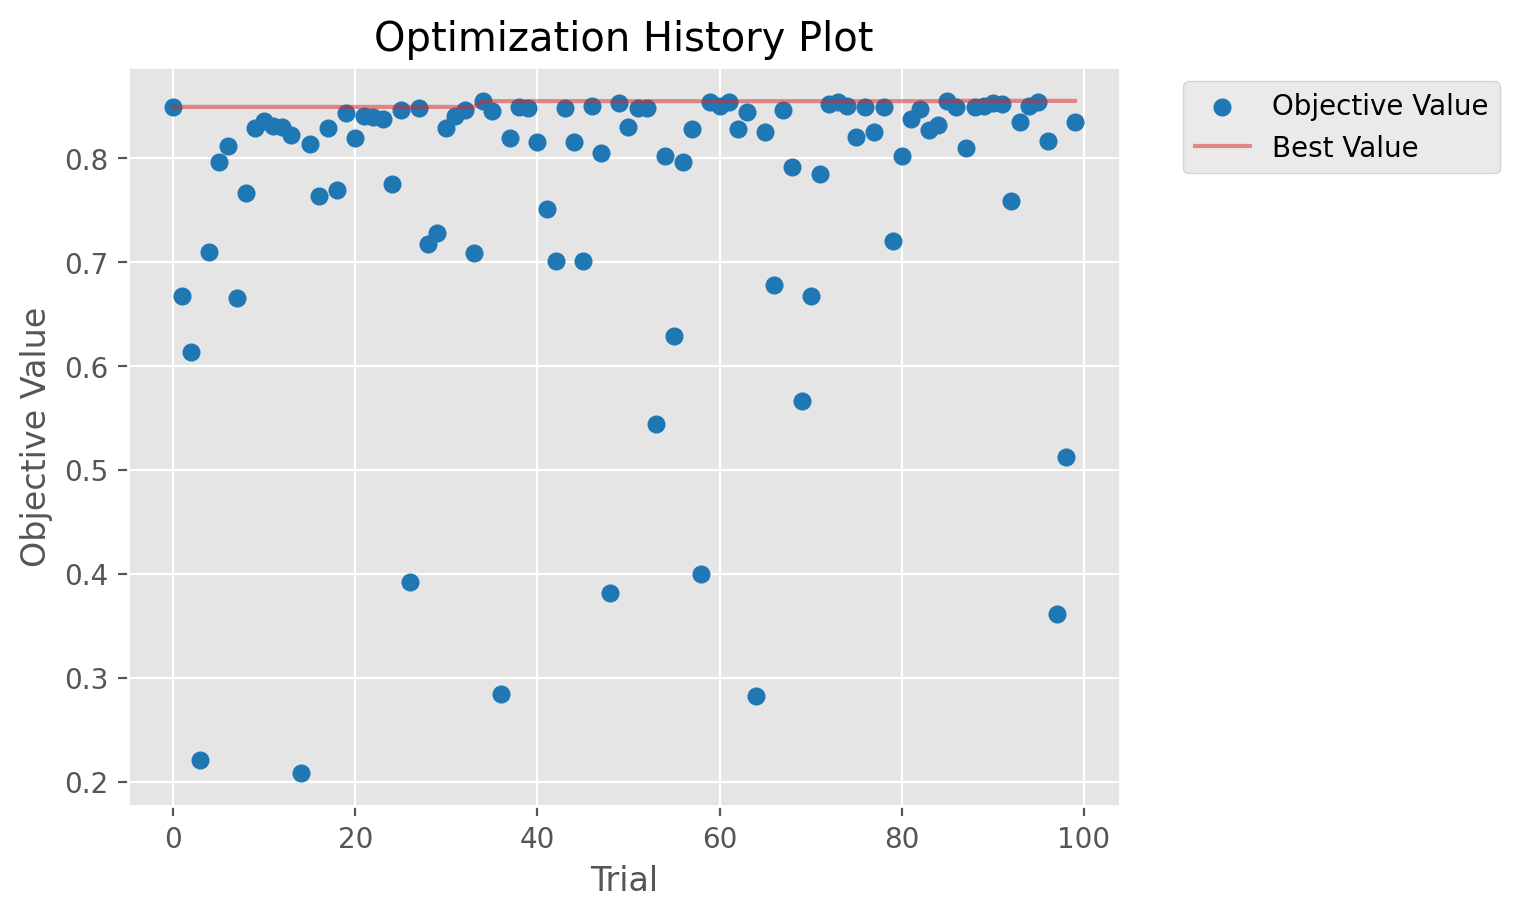

In [40]:
vis.plot_optimization_history(objeto_de_estudo_reglog)

$ \ \ \ \ \ $ O gráfico de importância dos hiperparâmetros indica quais deles mais influenciaram o F1 macro ao longo das tentativas. Um hiperparâmetro com importância alta é aquele cuja escolha mais muda o desempenho; os de importância baixa pouco afetam o resultado dentro do intervalo testado.

<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

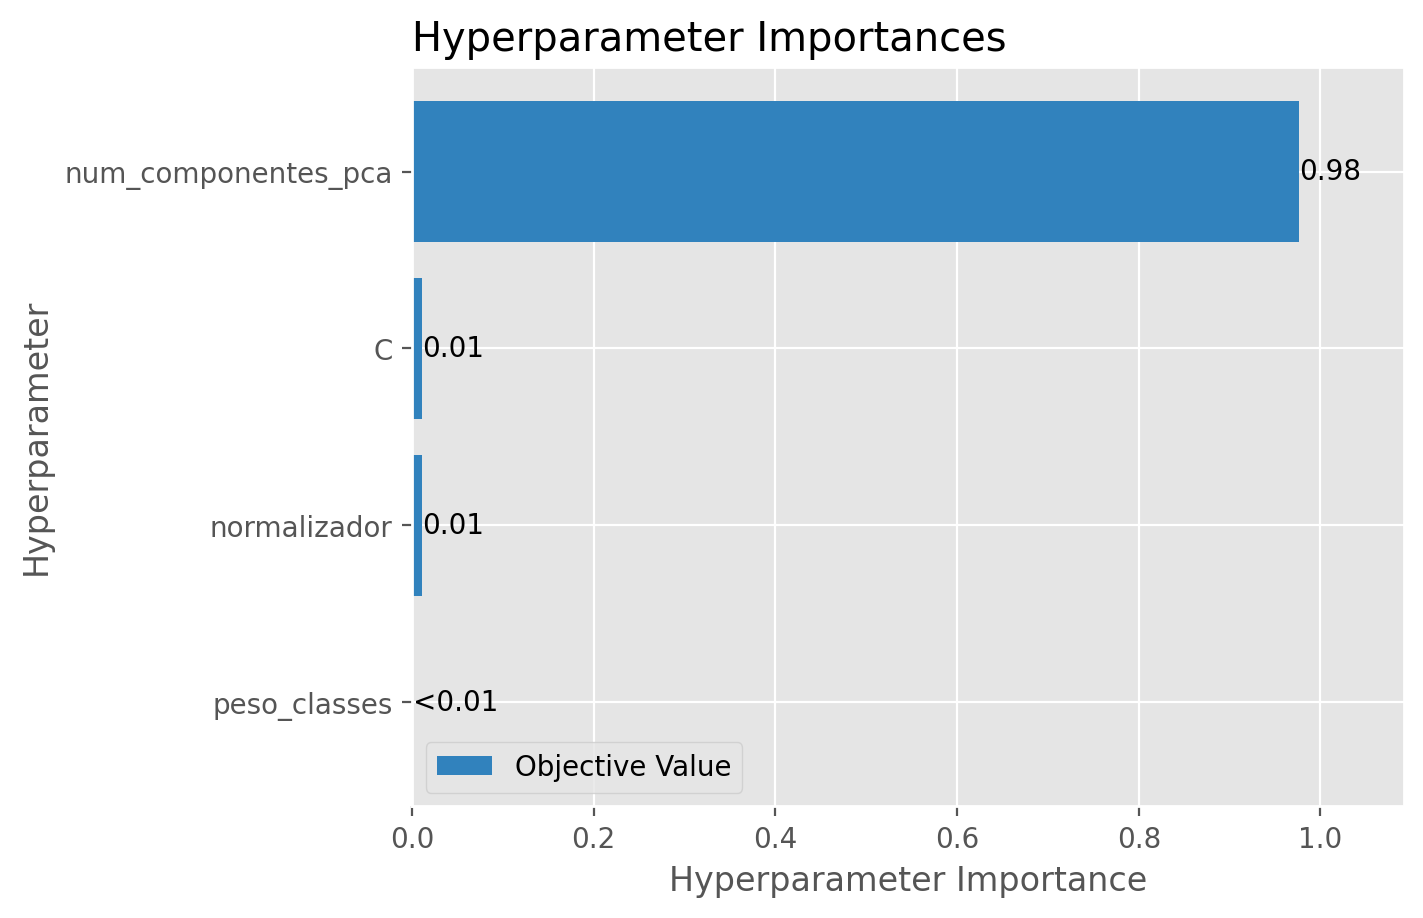

In [41]:
vis.plot_param_importances(objeto_de_estudo_reglog)

$ \ \ \ \ \ $ A melhor tentativa (número 85) obteve F1 macro médio de 85,5%, apenas 0,5 ponto percentual acima da tentativa com os valores padrão (85,0%). Os hiperparâmetros escolhidos foram `C` ≈ 0,37, sem peso nas classes, normalizador padrão e 65 componentes, ou seja, uma regularização um pouco mais forte que a padrão e nenhuma redução de dimensionalidade: com todas as componentes, o PCA apenas gira os eixos, sem descartar informação. O histórico mostra que a primeira tentativa já estava praticamente no melhor valor. O gráfico de importância indica que o número de componentes do PCA foi responsável por quase toda a variação do F1 macro (0,98), o que sugere que as tentativas com desempenho muito baixo, visíveis como pontos isolados no histórico, usaram poucas componentes. Já o `C`, o normalizador e o peso das classes pouco influenciaram o resultado. Assim, para a regressão logística, o fator decisivo foi manter informação suficiente, e os valores padrão do `scikit-learn` já eram adequados.

#### 3.6.5 k-vizinhos mais próximos (k-NN)

$ \ \ \ \ \ $ O k-vizinhos mais próximos (k-NN) classifica um organismo a partir dos organismos mais parecidos com ele no conjunto de treino [[18]](#refs). Para isso, calcula a distância entre o organismo e todos os organismos de treino, seleciona os k mais próximos e atribui a classe mais frequente entre eles. Diferentemente dos demais algoritmos, o k-NN não aprende parâmetros durante o treino, apenas armazena os dados (por isso é chamado de algoritmo preguiçoso), e todo o cálculo é feito no momento da previsão. Como depende de distâncias, ele é sensível à escala dos atributos, o que torna a normalização especialmente importante.

In [42]:
def cria_instancia_knn(trial):
    """Cria uma instância do modelo k-NN.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "n_neighbors": trial.suggest_int("num_vizinhos", 1, 50),
        "weights": trial.suggest_categorical("pesos", ["uniform", "distance"]),
        "p": trial.suggest_float("potencia_minkowski", 1, 2),
        # argumentos fixos
        "algorithm": "ball_tree",
        "n_jobs": -1,
    }

    modelo = make_pipeline(
        *cria_etapas_preprocessamento(trial),
        KNeighborsClassifier(**parametros),
    )

    return modelo

$ \ \ \ \ \ $ O número de vizinhos foi otimizado entre 1 e 50. O limite inferior corresponde ao modelo mais flexível, que classifica cada organismo pelo seu vizinho mais próximo, e o superior, a um modelo bem mais suave, que considera uma vizinhança ampla. Valores muito maiores que 50 prejudicariam os grupos pequenos: em cada fold de treino há apenas cerca de 80 arqueias, de modo que, com muitos vizinhos, elas tenderiam a ser superadas na votação pelas classes mais numerosas. O peso dos vizinhos pode ser uniforme, em que todos os vizinhos têm o mesmo voto, ou proporcional ao inverso da distância (`distance`), em que os vizinhos mais próximos pesam mais. Por fim, a potência da distância de Minkowski (`p`) variou continuamente entre 1, a distância de Manhattan, e 2, a distância euclidiana, permitindo que o Optuna escolha também uma distância intermediária. O argumento `algorithm="ball_tree"` foi fixado por um motivo técnico, descrito na seção de uso de IA, e altera apenas a forma de encontrar os vizinhos, não o resultado.

$ \ \ \ \ \ $ O estudo do *k*-NN foi criado da mesma forma que o da regressão logística, e é salvo no arquivo `knn_codon_usage.db`.

In [43]:
NOME_DO_ESTUDO = "knn_codon_usage"

objeto_de_estudo_knn = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True, seed=SEMENTE_ALEATORIA),
)

print("Tentativas já salvas:", len(objeto_de_estudo_knn.trials))

Tentativas já salvas: 64


$ \ \ \ \ \ $ A tentativa colocada na fila usa os valores padrão do `scikit-learn`: 5 vizinhos, pesos uniformes e distância euclidiana (p = 2), com o normalizador padrão e sem redução de dimensionalidade.

In [44]:
if len(objeto_de_estudo_knn.trials) == 0:
    objeto_de_estudo_knn.enqueue_trial(
        {
            "normalizador": "padrao",
            "num_componentes_pca": len(ATRIBUTOS),
            "num_vizinhos": 5,
            "pesos": "uniform",
            "potencia_minkowski": 2,
        }
    )

$ \ \ \ \ \ $ A otimização segue o mesmo procedimento descrito para a regressão logística, agora com a função `cria_instancia_[knn]`, e são executadas apenas as tentativas que faltam para completar 100.

In [71]:
funcao_objetivo_parcial = partial(
    funcao_objetivo,
    X=X_treino,
    y=y_treino,
    num_folds=NUM_FOLDS,
    cria_instancia_modelo=cria_instancia_knn,
)

tentativas_concluidas = len(
    objeto_de_estudo_knn.get_trials(states=[optuna.trial.TrialState.COMPLETE])
)
if tentativas_concluidas < NUM_TENTATIVAS:
    objeto_de_estudo_knn.optimize(
        funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS - tentativas_concluidas
    )

In [66]:
melhor_trial_knn = objeto_de_estudo_knn.best_trial

print(f"Número do melhor trial: {melhor_trial_knn.number}")
print(f"F1 macro do melhor trial: {melhor_trial_knn.value * 100:.1f}%")
print(f"Parâmetros do melhor trial: {melhor_trial_knn.params}")

Número do melhor trial: 81
F1 macro do melhor trial: 90.7%
Parâmetros do melhor trial: {'num_vizinhos': 1, 'pesos': 'distance', 'potencia_minkowski': 1.6371457693839484, 'normalizador': 'padrao', 'num_componentes_pca': 65}


$ \ \ \ \ \ $ Os gráficos de histórico e de importância dos hiperparâmetros são interpretados da mesma forma descrita para a regressão logística.

<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

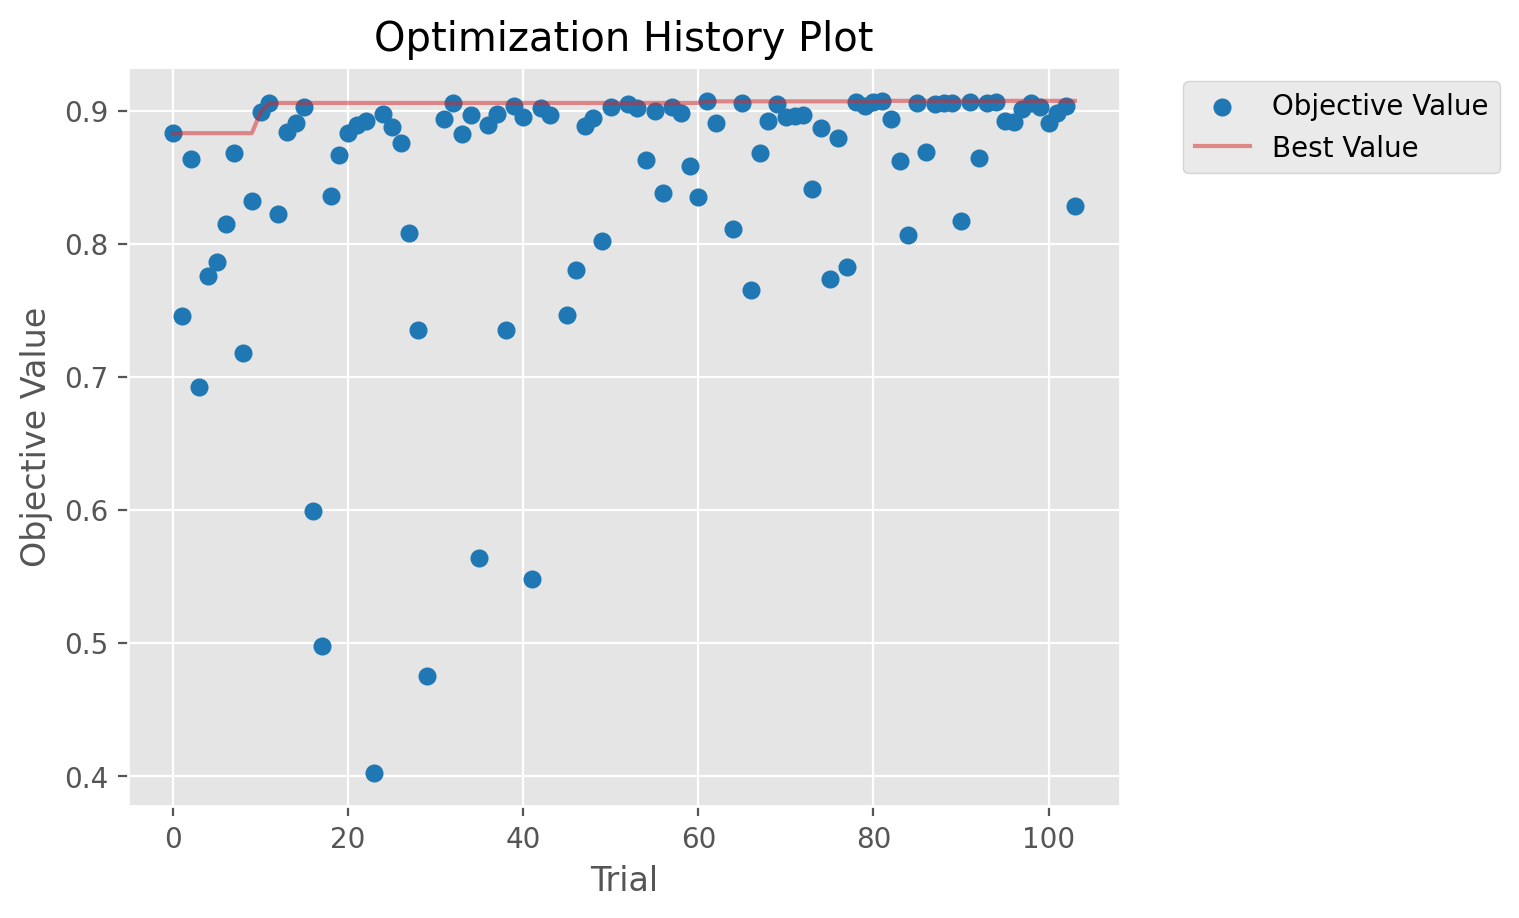

In [67]:
vis.plot_optimization_history(objeto_de_estudo_knn)

<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

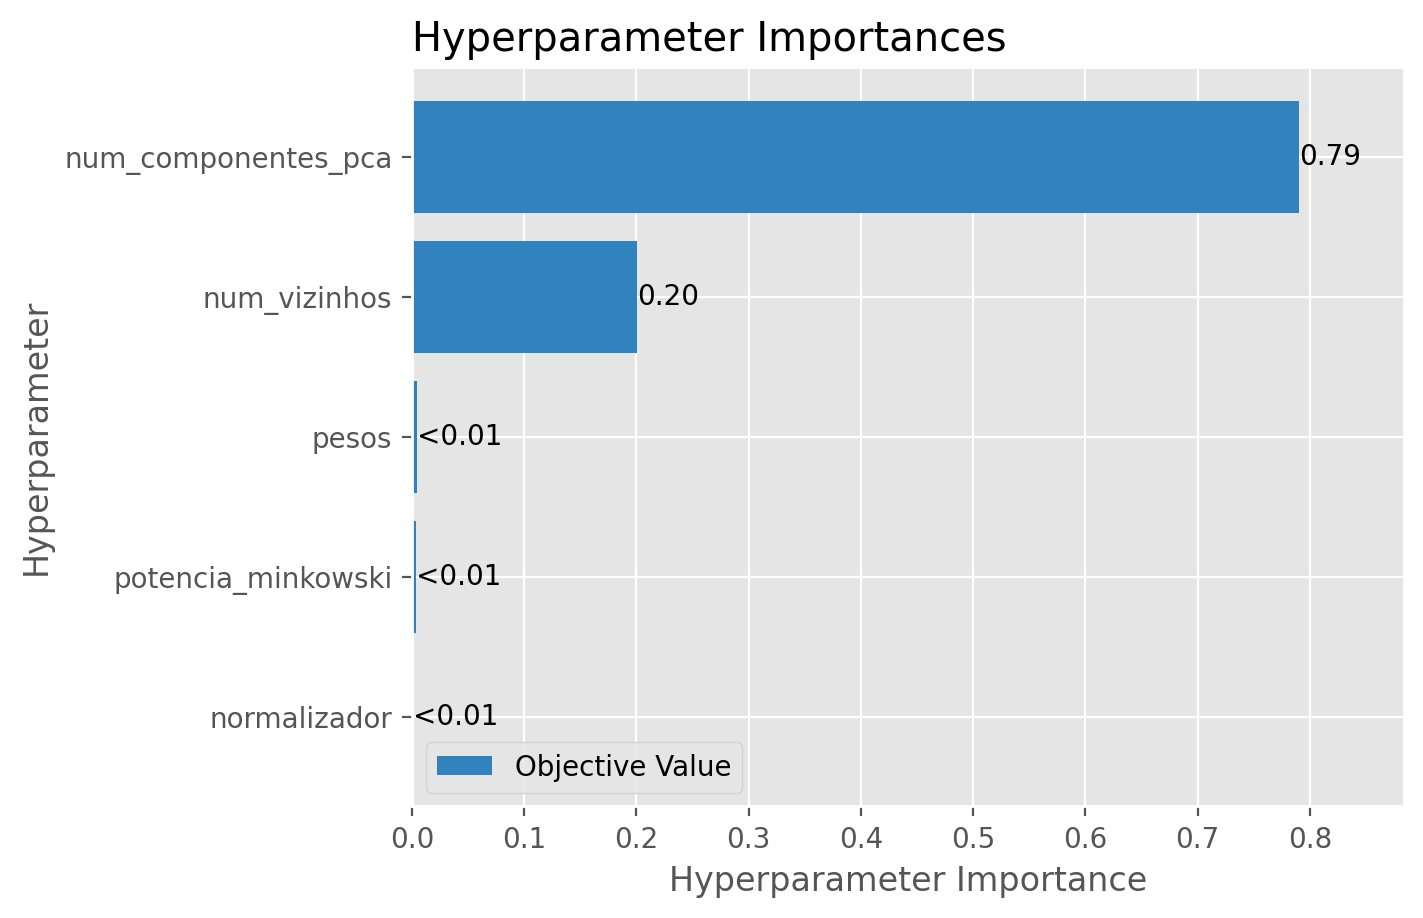

In [68]:
vis.plot_param_importances(objeto_de_estudo_knn)

$ \ \ \ \ \ $ A melhor tentativa (número 81) obteve F1 macro médio de 90,7%, 2,4 pontos percentuais acima da tentativa com os valores padrão (88,3%). O Optuna escolheu apenas 1 vizinho, o normalizador padrão, as 65 componentes e p ≈ 1,64, uma distância intermediária entre a de Manhattan (p = 1) e a euclidiana (p = 2). Com um único vizinho, o tipo de peso não faz diferença, pois não há outros vizinhos para ponderar. O gráfico de importância mostra que o número de componentes (0,79) e o número de vizinhos (0,20) foram os hiperparâmetros mais relevantes, enquanto o peso, a distância e o normalizador praticamente não influenciaram o resultado. Pelo histórico, um valor próximo do melhor já havia sido encontrado nas 10 primeiras tentativas, e as demais trouxeram apenas ganhos pequenos. O bom desempenho com um único vizinho indica que, para a maioria dos organismos, o organismo mais parecido no treino pertence ao mesmo grupo taxonômico.

#### 3.6.6 Árvore de Decisão

$ \ \ \ \ \ $ A árvore de decisão divide sucessivamente os dados por meio de perguntas sobre os atributos (por exemplo, "o valor desta componente é maior que 0,5?"), escolhendo a cada divisão a pergunta que torna os grupos resultantes mais homogêneos em relação à classe [[19]](#refs). A homogeneidade pode ser medida pelo índice de Gini ou pela entropia de Shannon [[14]](#refs). Ao final, cada folha da árvore corresponde a uma classe prevista.

In [49]:
def cria_instancia_arvore(trial):
    """Cria uma instância do modelo de árvore de decisão.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "criterion": trial.suggest_categorical("criterio", ["gini", "entropy"]),
        "max_depth": trial.suggest_int("profundidade_maxima", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 50, log=True),
        "max_features": trial.suggest_float("fracao_atributos", 0.1, 1),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        # argumentos fixos
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        *cria_etapas_preprocessamento(trial),
        DecisionTreeClassifier(**parametros),
    )

    return modelo

$ \ \ \ \ \ $ O critério de divisão pode ser o índice de Gini ou a entropia, as duas medidas de impureza disponíveis. A profundidade máxima variou de 2, uma árvore muito simples e propensa ao subajuste, até 30, um limite que na prática equivale a uma árvore sem restrição de profundidade, já que com cerca de 5.900 organismos em cada fold de treino uma árvore equilibrada de profundidade 13 já teria uma folha por organismo. O número mínimo de exemplos por folha variou de 1 a 50, em escala logarítmica, pois o efeito desse hiperparâmetro é maior nos valores pequenos (passar de 1 para 2 muda mais a árvore do que passar de 40 para 41); o limite de 50 permite folhas grandes sem impedir que as arqueias formem folhas próprias. A fração de atributos considerada em cada divisão variou de 10% a 100%, e o peso das classes seguiu a mesma lógica da regressão logística. A semente aleatória foi fixada para garantir a reprodutibilidade.

$ \ \ \ \ \ $ O estudo da árvore de decisão foi criado da mesma forma que o da regressão logística, e é salvo no arquivo `arvore_codon_usage.db`.

In [50]:
NOME_DO_ESTUDO = "arvore_codon_usage"

objeto_de_estudo_arvore = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True, seed=SEMENTE_ALEATORIA),
)

print("Tentativas já salvas:", len(objeto_de_estudo_arvore.trials))

Tentativas já salvas: 0


$ \ \ \ \ \ $ A tentativa colocada na fila usa os valores padrão do `scikit-learn`: critério de Gini, todos os atributos disponíveis em cada divisão, folhas com no mínimo 1 exemplo e sem peso nas classes. Como, por padrão, a profundidade da árvore não tem limite, usamos o maior valor do intervalo (30).

In [52]:
if len(objeto_de_estudo_arvore.trials) == 0:
    objeto_de_estudo_arvore.enqueue_trial(
        {
            "normalizador": "padrao",
            "num_componentes_pca": len(ATRIBUTOS),
            "criterio": "gini",
            "min_exemplos_folha": 1,
            "fracao_atributos": 1,
            "peso_classes": None,
            "profundidade_maxima": 30,
        }
    )

$ \ \ \ \ \ $ A otimização segue o mesmo procedimento descrito para a regressão logística, agora com a função `cria_instancia_arvore`, e são executadas apenas as tentativas que faltam para completar 100.

In [72]:
funcao_objetivo_parcial = partial(
    funcao_objetivo,
    X=X_treino,
    y=y_treino,
    num_folds=NUM_FOLDS,
    cria_instancia_modelo=cria_instancia_arvore,
)

tentativas_concluidas = len(
    objeto_de_estudo_arvore.get_trials(states=[optuna.trial.TrialState.COMPLETE])
)
if tentativas_concluidas < NUM_TENTATIVAS:
    objeto_de_estudo_arvore.optimize(
        funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS - tentativas_concluidas
    )

In [73]:
melhor_trial_arvore = objeto_de_estudo_arvore.best_trial

print(f"Número do melhor trial: {melhor_trial_arvore.number}")
print(f"F1 macro do melhor trial: {melhor_trial_arvore.value * 100:.1f}%")
print(f"Parâmetros do melhor trial: {melhor_trial_arvore.params}")

Número do melhor trial: 84
F1 macro do melhor trial: 73.1%
Parâmetros do melhor trial: {'criterio': 'entropy', 'profundidade_maxima': 20, 'min_exemplos_folha': 1, 'fracao_atributos': 0.9853866367731686, 'peso_classes': 'balanced', 'normalizador': 'max_abs', 'num_componentes_pca': 22}


$ \ \ \ \ \ $ A seguir, são apresentados o melhor resultado do estudo e os gráficos de histórico e de importância dos hiperparâmetros, interpretados da mesma forma descrita para a regressão logística.

<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

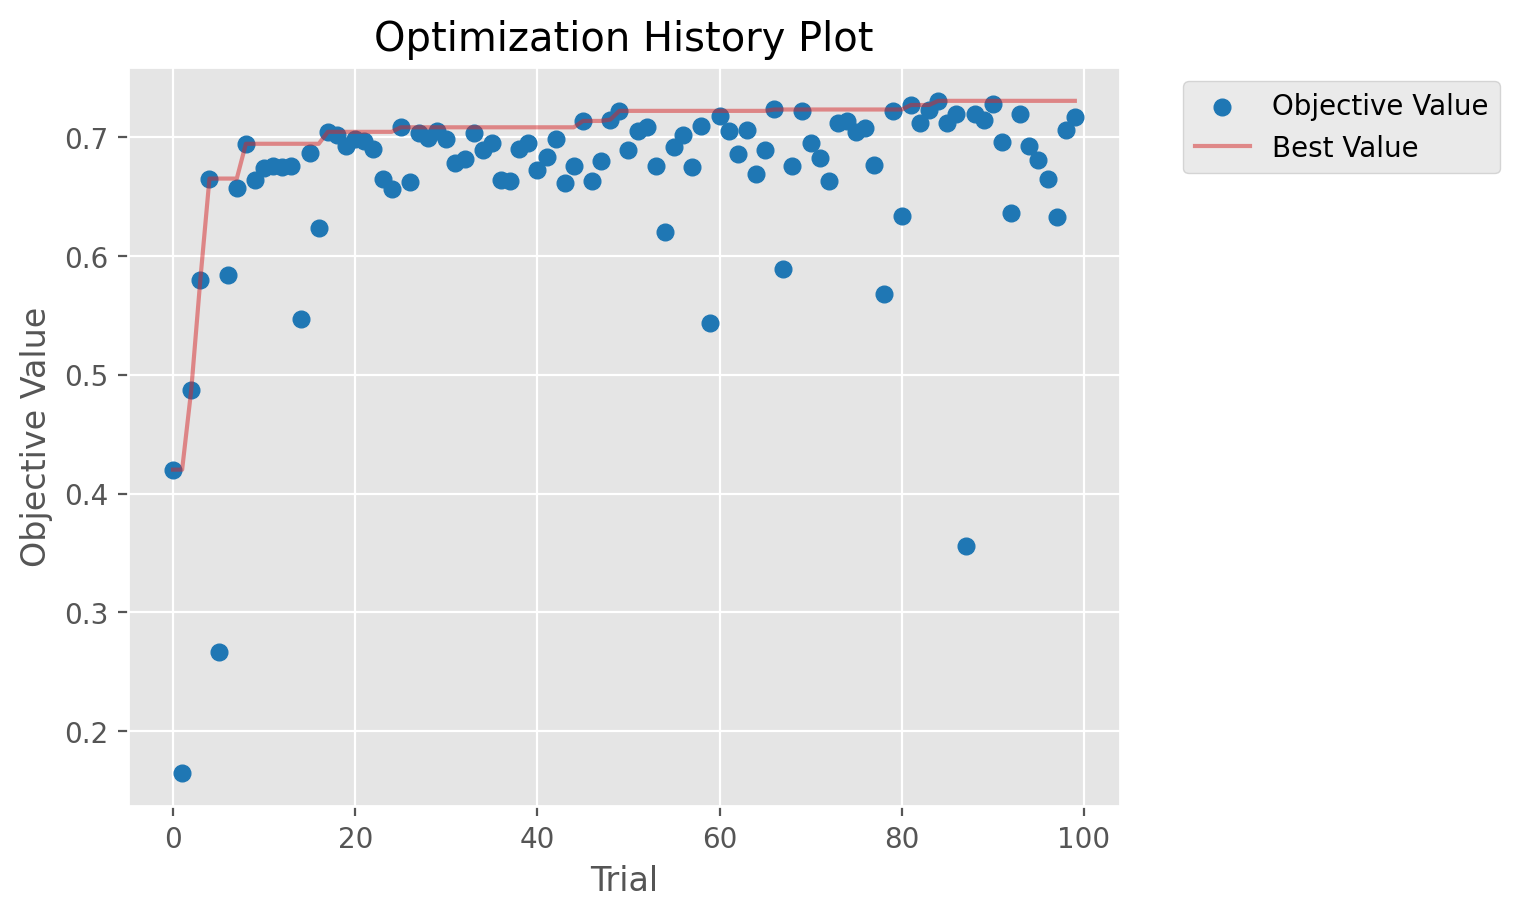

In [74]:
vis.plot_optimization_history(objeto_de_estudo_arvore)

<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

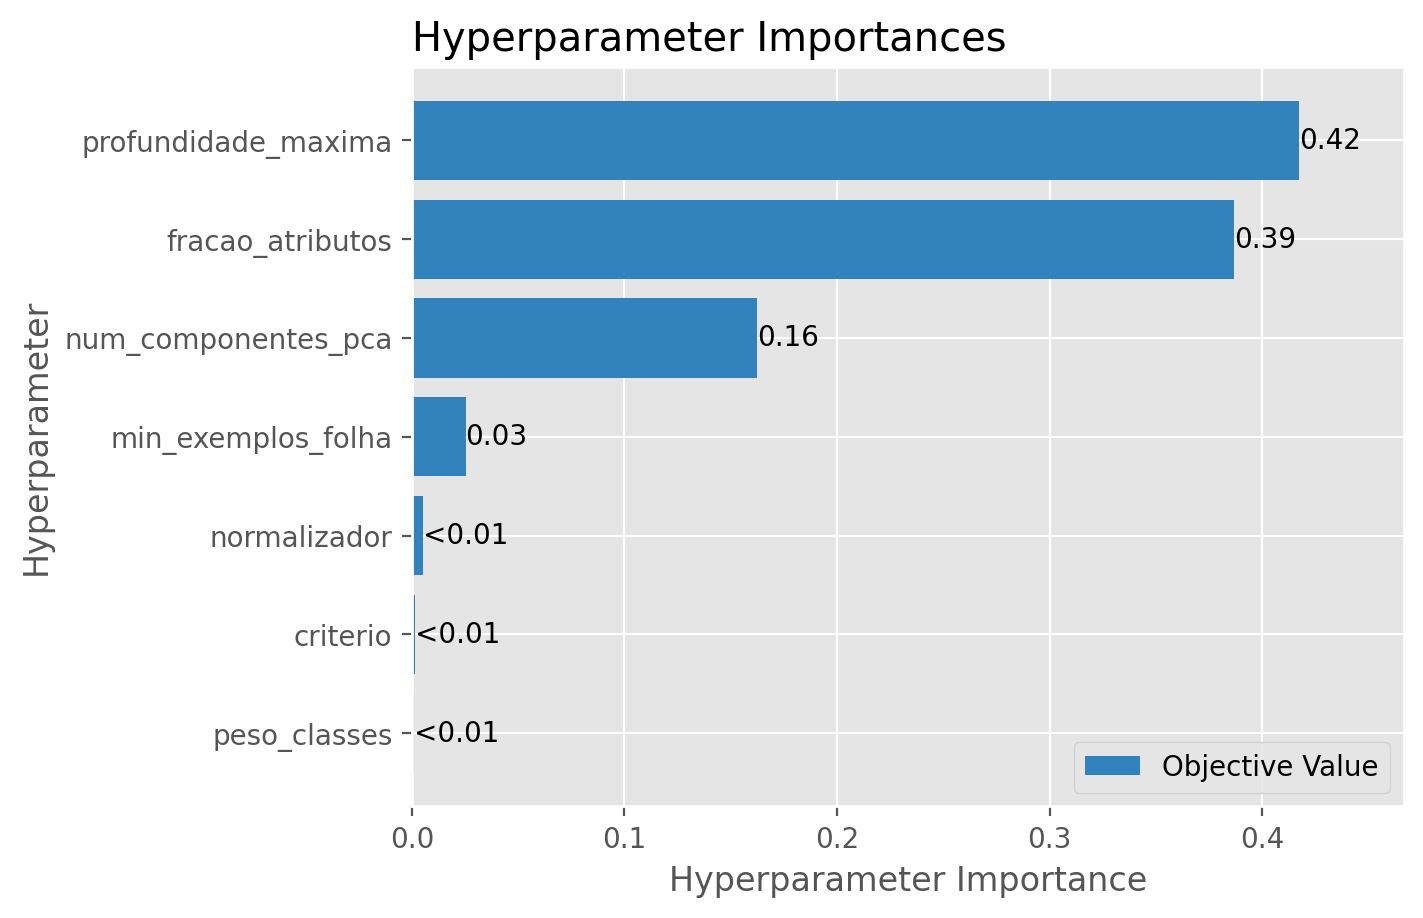

In [75]:
vis.plot_param_importances(objeto_de_estudo_arvore)

$ \ \ \ \ \ $ A melhor tentativa (número 84) obteve F1 macro médio de 73,1%, o menor entre os cinco algoritmos. Ela usou a entropia como critério, profundidade máxima de 20, folhas com no mínimo 1 exemplo, praticamente todos os atributos em cada divisão (fração ≈ 0,99) e peso balanceado nas classes, com o normalizador pelo máximo absoluto e 22 componentes. Embora a árvore em si não dependa da escala dos atributos, o normalizador importa porque o PCA, aplicado antes dela, depende. O gráfico de importância mostra que a profundidade máxima (0,42) e a fração de atributos (0,39) foram os hiperparâmetros mais influentes, seguidos pelo número de componentes (0,16). Pelo histórico, o desempenho subiu rapidamente nas 10 primeiras tentativas, de cerca de 42% para quase 70%, e depois cresceu lentamente até a tentativa 84.

$ \ \ \ \ \ $ Vale destacar que a primeira tentativa (42,0%) não corresponde ao modelo padrão: a fração de atributos foi informada como o número inteiro `1`, que o `scikit-learn` interpreta como um único atributo por divisão, e não como 100% dos atributos (o que exigiria o valor `1.0`). Por isso, a diferença entre essa tentativa e a melhor não representa o ganho da otimização em relação aos valores padrão.

#### 3.6.7 Floresta Aleatória

$ \ \ \ \ \ $ A floresta aleatória é um modelo de comitê formado por várias árvores de decisão [[19, 20]](#refs). Cada árvore é treinada com uma amostra diferente dos organismos, sorteada com reposição (bootstrap), e, em cada divisão, considera apenas uma fração sorteada dos atributos. Essas duas fontes de aleatoriedade tornam as árvores diferentes entre si, e a classe final é definida pela votação entre elas. Como os erros de árvores diferentes tendem a se compensar, a floresta costuma ser mais estável e precisa do que uma única árvore.

In [78]:
def cria_instancia_floresta(trial):
    """Cria uma instância do modelo de floresta aleatória.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "n_estimators": trial.suggest_int("num_arvores", 50, 300, log=True),
        "criterion": trial.suggest_categorical("criterio", ["gini", "entropy"]),
        "max_depth": trial.suggest_int("profundidade_maxima", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 20),
        "max_features": trial.suggest_float("fracao_atributos", 0.1, 1),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        # argumentos fixos
        "n_jobs": -1,
        "bootstrap": True,
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        *cria_etapas_preprocessamento(trial),
        RandomForestClassifier(**parametros),
    )

    return modelo

$ \ \ \ \ \ $ O número de árvores variou de 50 a 300, em escala logarítmica, com o valor padrão (100) dentro do intervalo. Mais árvores tornam a votação mais estável, mas o ganho diminui à medida que o número cresce, enquanto o custo computacional aumenta proporcionalmente; por isso, o limite superior foi mantido em 300. O critério, a profundidade máxima e o peso das classes seguiram os mesmos intervalos da árvore de decisão. Já o número mínimo de exemplos por folha teve um limite menor (1 a 20), pois na floresta o sobreajuste de cada árvore é compensado pela votação, e árvores mais profundas e diferentes entre si costumam funcionar melhor. A fração de atributos por divisão variou de 10% a 100%, o que inclui o valor de cerca de 33% sugerido na literatura e o padrão do `scikit-learn` (a raiz quadrada do número de atributos, cerca de 12%). A amostragem bootstrap foi mantida, e a semente foi fixada.

$ \ \ \ \ \ $ O estudo da floresta aleatória foi criado da mesma forma que o da regressão logística, e é salvo no arquivo `floresta_codon_usage.db`.

In [79]:
NOME_DO_ESTUDO = "floresta_codon_usage"

objeto_de_estudo_floresta = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True, seed=SEMENTE_ALEATORIA),
)

print("Tentativas já salvas:", len(objeto_de_estudo_floresta.trials))

Tentativas já salvas: 1


$ \ \ \ \ \ $ A tentativa colocada na fila usa os valores padrão do `scikit-learn` para o número de árvores (100), o critério (Gini), o mínimo de exemplos por folha (1) e o peso das classes (nenhum). A profundidade máxima e a fração de atributos não foram fixadas e, por isso, foram sorteadas pelo Optuna nessa tentativa, de modo que ela não corresponde exatamente ao modelo padrão.

In [80]:
if len(objeto_de_estudo_floresta.trials) == 0:
    objeto_de_estudo_floresta.enqueue_trial(
        {
            "normalizador": "padrao",
            "num_componentes_pca": len(ATRIBUTOS),
            "num_arvores": 100,
            "criterio": "gini",
            "min_exemplos_folha": 1,
            "peso_classes": None,
        }
    )

$ \ \ \ \ \ $ A otimização segue o mesmo procedimento descrito para a regressão logística, agora com a função `cria_instancia_floresta`, e são executadas apenas as tentativas que faltam para completar 100.

In [81]:
funcao_objetivo_parcial = partial(
    funcao_objetivo,
    X=X_treino,
    y=y_treino,
    num_folds=NUM_FOLDS,
    cria_instancia_modelo=cria_instancia_floresta,
)

tentativas_concluidas = len(
    objeto_de_estudo_floresta.get_trials(states=[optuna.trial.TrialState.COMPLETE])
)
if tentativas_concluidas < NUM_TENTATIVAS:
    objeto_de_estudo_floresta.optimize(
        funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS - tentativas_concluidas
    )

In [82]:
melhor_trial_floresta = objeto_de_estudo_floresta.best_trial

print(f"Número do melhor trial: {melhor_trial_floresta.number}")
print(f"F1 macro do melhor trial: {melhor_trial_floresta.value * 100:.1f}%")
print(f"Parâmetros do melhor trial: {melhor_trial_floresta.params}")

Número do melhor trial: 26
F1 macro do melhor trial: 85.5%
Parâmetros do melhor trial: {'num_arvores': 102, 'criterio': 'gini', 'profundidade_maxima': 28, 'min_exemplos_folha': 3, 'fracao_atributos': 0.10993886946743374, 'peso_classes': 'balanced', 'normalizador': 'max_abs', 'num_componentes_pca': 37}


$ \ \ \ \ \ $ A seguir, são apresentados o melhor resultado do estudo e os gráficos de histórico e de importância dos hiperparâmetros, interpretados da mesma forma descrita para a regressão logística.

<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

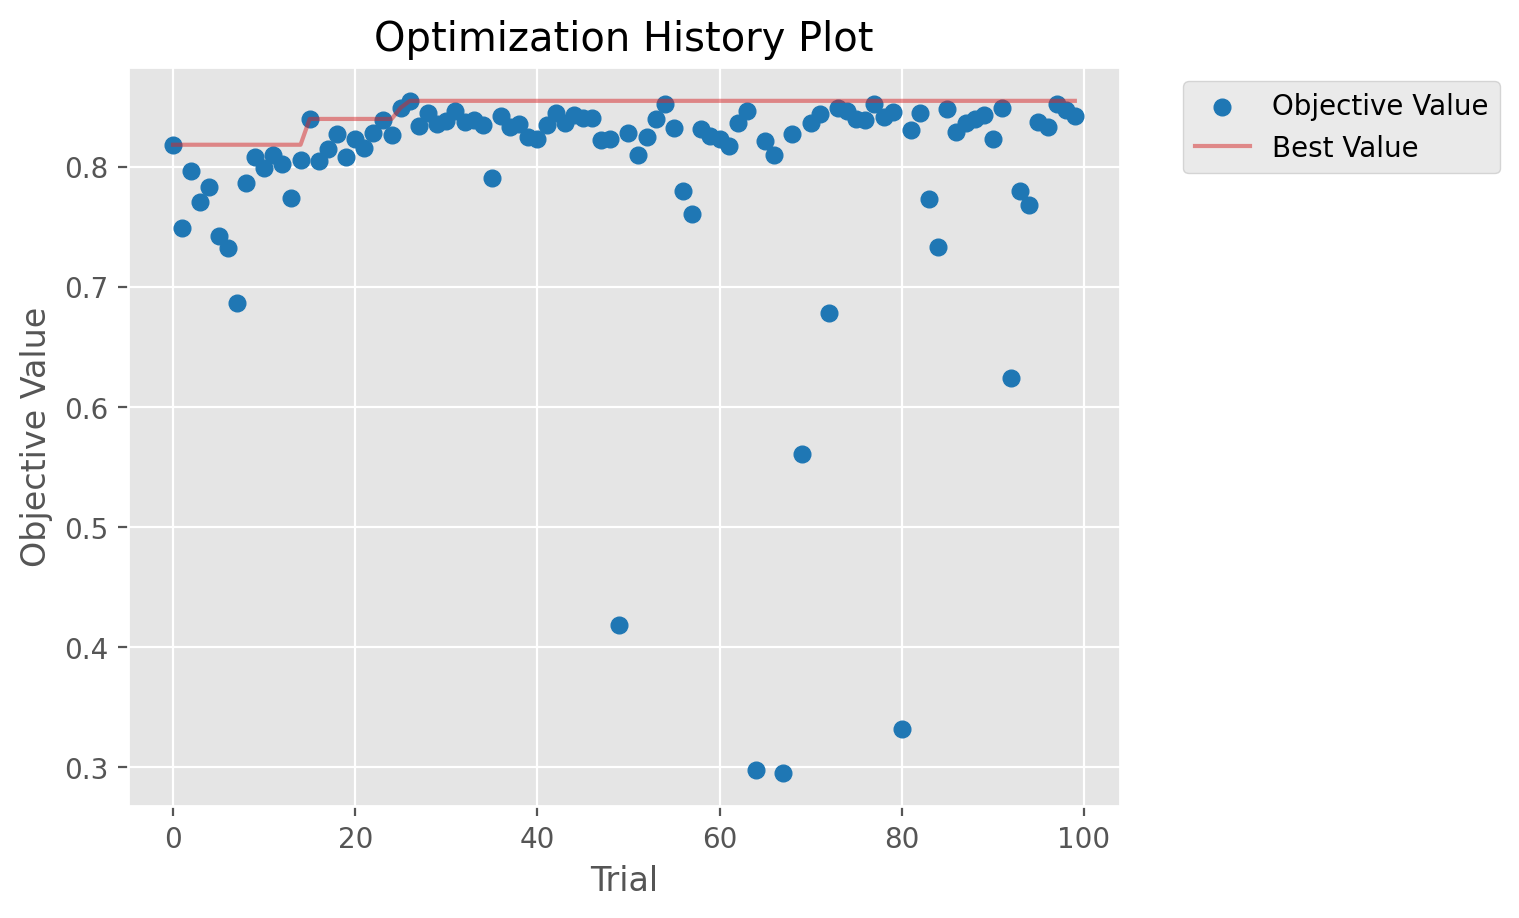

In [83]:
vis.plot_optimization_history(objeto_de_estudo_floresta)

<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

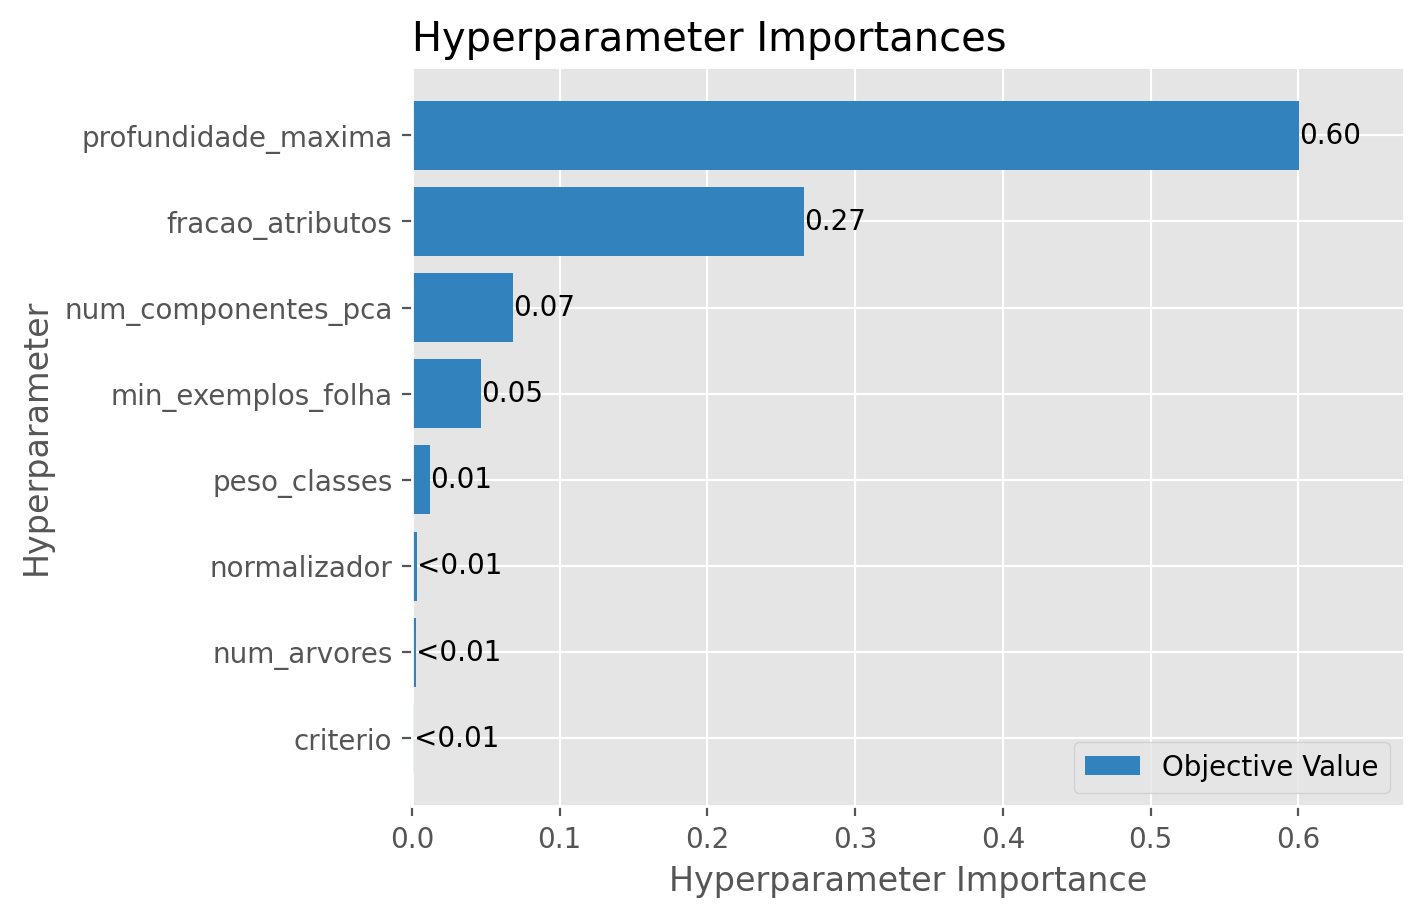

In [84]:
vis.plot_param_importances(objeto_de_estudo_floresta)

$ \ \ \ \ \ $ A melhor tentativa (número 26) obteve F1 macro médio de 85,5%, 12,4 pontos percentuais acima da árvore de decisão isolada, o que mostra o efeito da votação entre árvores na redução da variância. Ela usou 102 árvores, critério de Gini, profundidade máxima de 28, no mínimo 3 exemplos por folha e peso balanceado nas classes, com o normalizador pelo máximo absoluto e 37 componentes. A fração de atributos escolhida foi baixa (≈ 0,11, cerca de 4 das 37 componentes em cada divisão), o que deixa as árvores mais diferentes entre si e torna a votação mais eficaz. Assim como na árvore isolada, a profundidade máxima (0,60) e a fração de atributos (0,27) foram os hiperparâmetros mais importantes, enquanto o número de árvores praticamente não influenciou o resultado dentro do intervalo testado. O histórico mostra que o melhor valor foi encontrado na tentativa 26 e não foi superado nas tentativas seguintes.

#### 3.6.8 Gradient Boosting (HistGradientBoosting)

$ \ \ \ \ \ $ O Gradient Boosting também é um modelo de comitê baseado em árvores de decisão, mas, diferentemente da floresta aleatória, em que as árvores são treinadas de forma independente, aqui elas são treinadas em sequência [[21]](#refs). Cada nova árvore é treinada para corrigir os erros cometidos pelas anteriores, e a previsão final é a soma das contribuições de todas as árvores. O termo "gradiente" vem do fato de que essa correção é feita na direção que mais reduz a função de custo do modelo. A taxa de aprendizado controla o tamanho da contribuição de cada nova árvore. A implementação utilizada, `HistGradientBoostingClassifier`, agrupa os valores de cada atributo em faixas, como em um histograma, o que torna o treino muito mais rápido [[6]](#refs).

In [85]:
def cria_instancia_hgb(trial):
    """Cria uma instância do modelo HistGradientBoosting.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """

    parametros = {
        # espaço de busca
        "learning_rate": trial.suggest_float("taxa_aprendizado", 0.01, 0.3, log=True),
        "max_iter": trial.suggest_int("num_iteracoes", 50, 500, log=True),
        "max_leaf_nodes": trial.suggest_int("max_folhas", 8, 128, log=True),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 5, 100, log=True),
        "l2_regularization": trial.suggest_float("regularizacao_l2", 1e-6, 10, log=True),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        # argumentos fixos
        "early_stopping": False,
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        *cria_etapas_preprocessamento(trial),
        HistGradientBoostingClassifier(**parametros),
    )

    return modelo

$ \ \ \ \ \ $ Todos os hiperparâmetros numéricos foram sorteados em escala logarítmica, pois seus intervalos abrangem pelo menos uma ordem de grandeza, e todos incluem os valores padrão do `scikit-learn`. A taxa de aprendizado variou de 0,01 a 0,3 (padrão 0,1): taxas pequenas fazem cada árvore contribuir pouco, o que tende a generalizar melhor, mas exige mais iterações. Por isso, o número de iterações também foi otimizado, entre 50 e 500 (padrão 100). O número máximo de folhas de cada árvore, que controla a sua complexidade, variou de 8 a 128 (padrão 31), e o número mínimo de exemplos por folha, de 5 a 100 (padrão 20). A regularização L2, que penaliza contribuições muito grandes de cada folha, variou de 10⁻⁶, um valor que equivale na prática a nenhuma regularização (o padrão é zero, que não pode ser usado em escala logarítmica), até 10. O peso das classes seguiu a mesma lógica dos demais modelos. A parada antecipada (`early_stopping`) foi desativada para que o número de iterações seja sempre o escolhido pelo Optuna, sem que parte do conjunto de treino seja separada para validação interna.

$ \ \ \ \ \ $ O estudo do HistGradientBoosting foi criado da mesma forma que o da regressão logística, e é salvo no arquivo `hgb_codon_usage.db`.

In [86]:
NOME_DO_ESTUDO = "hgb_codon_usage"

objeto_de_estudo_hgb = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True, seed=SEMENTE_ALEATORIA),
)

print("Tentativas já salvas:", len(objeto_de_estudo_hgb.trials))

Tentativas já salvas: 1


$ \ \ \ \ \ $ A tentativa colocada na fila usa os valores padrão do `scikit-learn`: taxa de aprendizado de 0,1, 100 iterações, 31 folhas, no mínimo 20 exemplos por folha e sem peso nas classes. A regularização L2, cujo padrão é zero, não pôde ser fixada, pois a escala logarítmica não aceita o zero (o intervalo começa em 10⁻⁶), e foi sorteada pelo Optuna.

In [87]:
if len(objeto_de_estudo_hgb.trials) == 0:
    objeto_de_estudo_hgb.enqueue_trial(
        {
            "normalizador": "padrao",
            "num_componentes_pca": len(ATRIBUTOS),
            "taxa_aprendizado": 0.1,
            "num_iteracoes": 100,
            "max_folhas": 31,
            "min_exemplos_folha": 20,
            "peso_classes": None,
        }
    )

$ \ \ \ \ \ $ A otimização segue o mesmo procedimento descrito para a regressão logística, agora com a função `cria_instancia_hgb`, e são executa\das apenas as tentativas que faltam para completar 100.

In [88]:
funcao_objetivo_parcial = partial(
    funcao_objetivo,
    X=X_treino,
    y=y_treino,
    num_folds=NUM_FOLDS,
    cria_instancia_modelo=cria_instancia_hgb,
)

tentativas_concluidas = len(
    objeto_de_estudo_hgb.get_trials(states=[optuna.trial.TrialState.COMPLETE])
)
if tentativas_concluidas < NUM_TENTATIVAS:
    objeto_de_estudo_hgb.optimize(
        funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS - tentativas_concluidas
    )

$ \ \ \ \ \ $ A seguir, são apresentados o melhor resultado do estudo e os gráficos de histórico e de importância dos hiperparâmetros, interpretados da mesma forma descrita para a regressão logística.

In [89]:
melhor_trial_hgb = objeto_de_estudo_hgb.best_trial

print(f"Número do melhor trial: {melhor_trial_hgb.number}")
print(f"F1 macro do melhor trial: {melhor_trial_hgb.value * 100:.1f}%")
print(f"Parâmetros do melhor trial: {melhor_trial_hgb.params}")

Número do melhor trial: 55
F1 macro do melhor trial: 90.6%
Parâmetros do melhor trial: {'taxa_aprendizado': 0.1389732238905521, 'num_iteracoes': 443, 'max_folhas': 12, 'min_exemplos_folha': 39, 'regularizacao_l2': 1.6763500703528116e-06, 'peso_classes': 'balanced', 'normalizador': 'max_abs', 'num_componentes_pca': 60}


<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

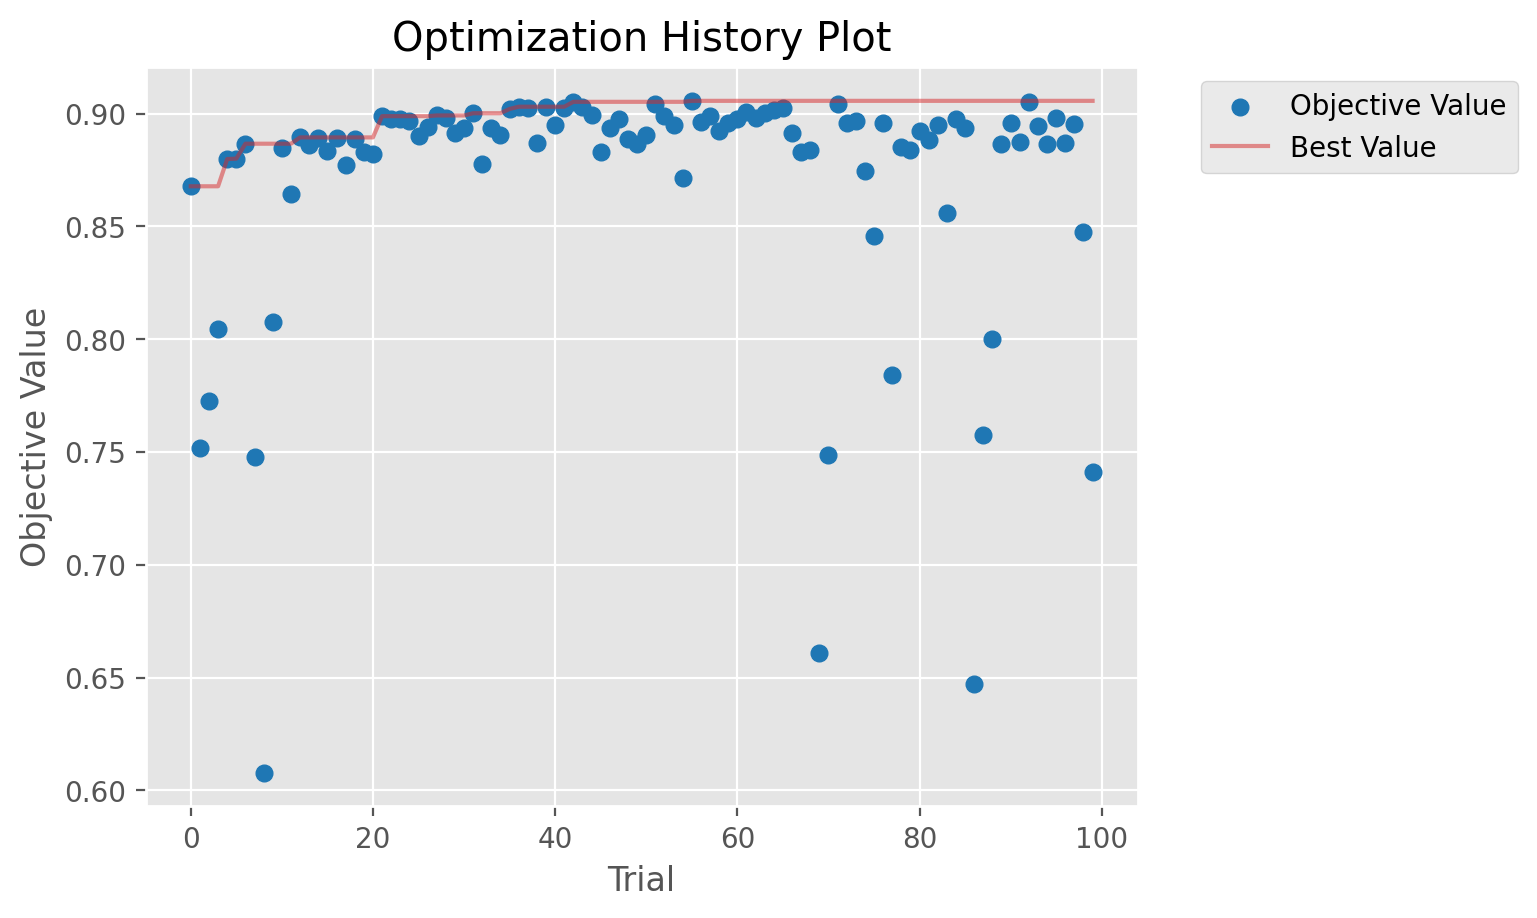

In [90]:
vis.plot_optimization_history(objeto_de_estudo_hgb)

<Axes: title={'left': 'Hyperparameter Importances'}, xlabel='Hyperparameter Importance', ylabel='Hyperparameter'>

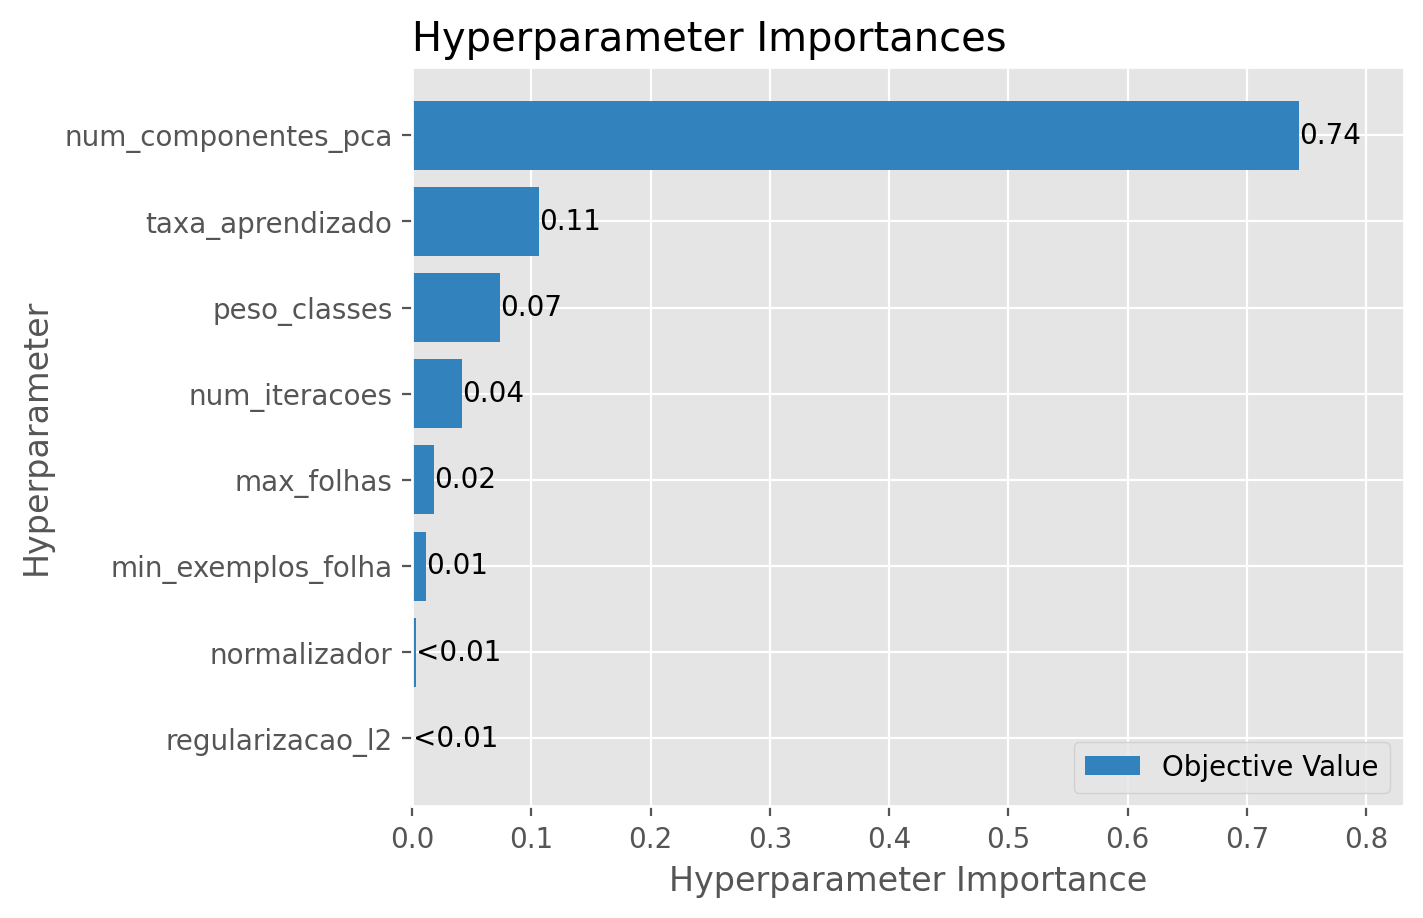

In [91]:
vis.plot_param_importances(objeto_de_estudo_hgb)

$ \ \ \ \ \ $ A melhor tentativa (número 55) obteve F1 macro médio de 90,6%, 3,8 pontos percentuais acima da primeira tentativa (86,8%), praticamente empatando com o k-NN. Ela usou taxa de aprendizado ≈ 0,14, 443 iterações, árvores pequenas (no máximo 12 folhas, com no mínimo 39 exemplos cada), regularização L2 desprezível e peso balanceado nas classes, com o normalizador pelo máximo absoluto e 60 componentes. Ou seja, o modelo combinou muitas árvores simples, o que é típico do gradient boosting, em que cada árvore corrige uma pequena parte dos erros das anteriores. Como o problema tem seis classes, o algoritmo treina uma árvore por classe em cada iteração, totalizando mais de 2.600 árvores. O gráfico de importância mostra que, novamente, o número de componentes foi o hiperparâmetro mais influente (0,74), seguido pela taxa de aprendizado (0,11) e pelo peso das classes (0,07). Pelo histórico, o desempenho subiu rapidamente nas 20 primeiras tentativas e depois se estabilizou em torno de 90%.

#### 3.6.9 Resumo da Otimização 

$ \ \ \ \ \ $ A tabela a seguir resume a otimização realizada para cada algoritmo. Todos os estudos testaram pelo menos 100 conjuntos distintos de hiperparâmetros, cada um avaliado por validação cruzada com 5 folds, o que corresponde a pelo menos 500 modelos treinados por algoritmo. 

In [92]:
estudos = {
    "Regressão logística": objeto_de_estudo_reglog,
    "k-NN": objeto_de_estudo_knn,
    "Árvore de decisão": objeto_de_estudo_arvore,
    "Floresta aleatória": objeto_de_estudo_floresta,
    "HistGradientBoosting": objeto_de_estudo_hgb,
}

linhas = []
for nome, estudo in estudos.items():
    df_tentativas = estudo.trials_dataframe()
    df_concluidas = df_tentativas[df_tentativas["state"] == "COMPLETE"]

    colunas_hiperparametros = [c for c in df_concluidas.columns if c.startswith("params_")]
    conjuntos_distintos = len(df_concluidas[colunas_hiperparametros].drop_duplicates())

    tentativa_padrao = estudo.trials[0]
    f1_padrao = tentativa_padrao.value * 100 if tentativa_padrao.value is not None else np.nan

    linhas.append({
        "Modelo": nome,
        "Tentativas concluídas": len(df_concluidas),
        "Conjuntos distintos de hiperparâmetros": conjuntos_distintos,
        "Hiperparâmetros otimizados": len(colunas_hiperparametros),
        "Folds por tentativa": NUM_FOLDS,
        "Modelos treinados": len(df_concluidas) * NUM_FOLDS,
        "F1 macro padrão (%)": round(f1_padrao, 1),
        "Melhor F1 macro (%)": round(estudo.best_value * 100, 1),
    })

resumo_optuna = pd.DataFrame(linhas).set_index("Modelo")
resumo_optuna

,Tentativas concluídas,Conjuntos distintos de hiperparâmetros,Hiperparâmetros otimizados,Folds por tentativa,Modelos treinados,F1 macro padrão (%),Melhor F1 macro (%)
Modelo,,,,,,,
Regressão logística,100,100,4,5,500,85.0,85.5
k-NN,100,100,5,5,500,88.3,90.7
Árvore de decisão,100,100,7,5,500,42.0,73.1
Floresta aleatória,100,100,8,5,500,81.9,85.5
HistGradientBoosting,100,100,8,5,500,86.8,90.6


$ \ \ \ \ \ $ A tabela confirma que todos os estudos têm 100 tentativas concluídas, com 100 conjuntos distintos de hiperparâmetros cada. Em todos os casos, a otimização superou a primeira tentativa do estudo. Para a regressão logística, o *k*-NN e o HistGradientBoosting, essa tentativa corresponde aos valores padrão do `scikit-learn` (no HistGradientBoosting, com exceção da regularização L2), e os ganhos foram de 0,5, 2,4 e 3,8 pontos percentuais, respectivamente. O pequeno ganho da regressão logística indica que seus valores padrão já eram adequados para este problema. Na floresta aleatória, a primeira tentativa não corresponde exatamente ao modelo padrão, pois a profundidade máxima e a fração de atributos foram sorteadas, e o ganho foi de 3,6 pontos. Na árvore de decisão, o salto de 42,0% para 73,1% se deve em grande parte ao erro na primeira tentativa, descrito na seção 3.6.6, e não deve ser interpretado como o ganho em relação ao modelo padrão.

$ \ \ \ \ \ $ Os gráficos de importância também mostram um padrão: na regressão logística, no *k*-NN e no HistGradientBoosting, o número de componentes do PCA foi o hiperparâmetro mais influente, enquanto na árvore de decisão e na floresta aleatória a profundidade máxima e a fração de atributos tiveram mais peso.

<a id="val"></a>
### 3.7 Comparação dos Modelos por Validação Cruzada

$ \ \ \ \ \ $ Nesta seção, o melhor pipeline de cada algoritmo, com os hiperparâmetros encontrados pelo Optuna, será avaliado novamente por validação cruzada no conjunto de treino, utilizando os mesmos 5 folds da otimização. Com isso, obtemos o F1 macro de cada fold, o que permite comparar não só o desempenho médio dos modelos, mas também a sua variação entre os folds, e incluir o baseline na comparação. No caso, como os folds são os mesmos, as médias coincidem com os melhores valores encontrados em cada estudo.

In [93]:
melhores_modelos = {
    "Regressão logística": cria_instancia_reglog(melhor_trial_reglog),
    "k-NN": cria_instancia_knn(melhor_trial_knn),
    "Árvore de decisão": cria_instancia_arvore(melhor_trial_arvore),
    "Floresta aleatória": cria_instancia_floresta(melhor_trial_floresta),
    "HistGradientBoosting": cria_instancia_hgb(melhor_trial_hgb),
}

resultados_cv = {"Baseline": f1_baseline}

for nome, modelo in melhores_modelos.items():
    resultados_cv[nome] = cross_val_score(
        modelo,
        X_treino,
        y_treino,
        scoring=METRICA,
        cv=NUM_FOLDS,
    )

df_resultados_cv = pd.DataFrame(resultados_cv) * 100

resumo_cv = df_resultados_cv.agg(["mean", "std"]).T.round(1)
resumo_cv.columns = ["F1 macro médio (%)", "Desvio padrão (%)"]
resumo_cv.sort_values("F1 macro médio (%)", ascending=False)

,F1 macro médio (%),Desvio padrão (%)
k-NN,90.7,1.1
HistGradientBoosting,90.6,1.1
Floresta aleatória,85.5,2.4
Regressão logística,85.5,1.2
Árvore de decisão,73.1,1.6
Baseline,8.3,0.0


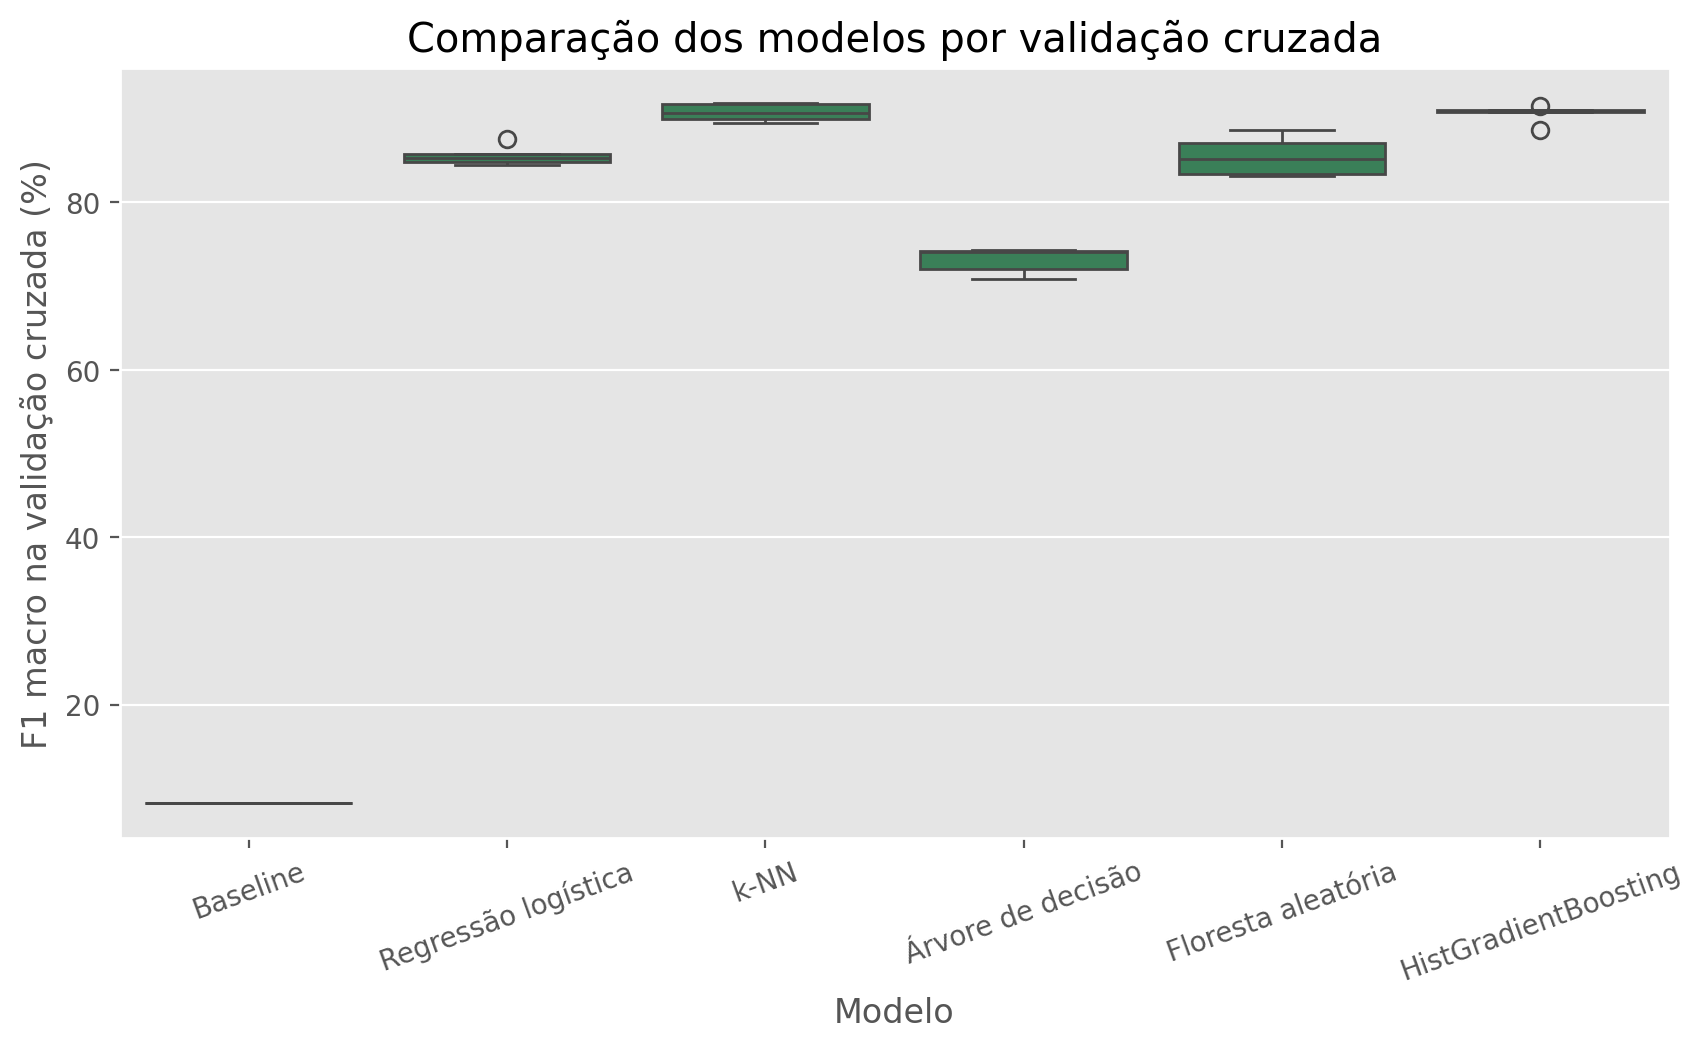

In [94]:
figura, eixo = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df_resultados_cv, color="seagreen", ax=eixo)
eixo.set(
    xlabel="Modelo",
    ylabel="F1 macro na validação cruzada (%)",
    title="Comparação dos modelos por validação cruzada",
)
plt.xticks(rotation=20);

$ \ \ \ \ \ $ Todos os modelos superaram amplamente o baseline (8,3%). O *k*-NN (90,7% ± 1,1%) e o HistGradientBoosting (90,6% ± 1,1%) obtiveram os maiores valores de F1 macro, seguidos pela floresta aleatória e pela regressão logística, empatadas em 85,5% (± 2,4% e ± 1,2%, respectivamente). A árvore de decisão teve o menor desempenho (73,1% ± 1,6%), e a floresta aleatória apresentou a maior variação entre os folds, como mostra o boxplot.

$ \ \ \ \ \ $ A diferença entre o *k*-NN e o HistGradientBoosting (0,1 ponto percentual) é muito menor que o desvio padrão de cada um, de modo que os dois modelos podem ser considerados equivalentes. Seguindo o critério definido na metodologia, o modelo com maior F1 macro médio, o *k*-NN, foi escolhido para a avaliação final. Essa escolha também traz a vantagem da simplicidade: o *k*-NN com um único vizinho classifica cada organismo pelo organismo mais parecido do treino, enquanto o HistGradientBoosting combina mais de 2.600 árvores.

<a id="teste"></a>
### 3.8 Avaliação Final no Conjunto de Teste

$ \ \ \ \ \ $ O modelo escolhido foi treinado com todo o conjunto de treino e avaliado uma única vez no conjunto de teste, que não foi utilizado em nenhuma etapa anterior. Esse resultado é a medida final do desempenho do modelo em dados nunca vistos. Antes de analisar os resultados, vamos plotar a matriz de confusão (em que as linhas indicam o grupo verdadeiro, as colunas o grupo previsto, e a diagonal reúne os acertos) do baseline:

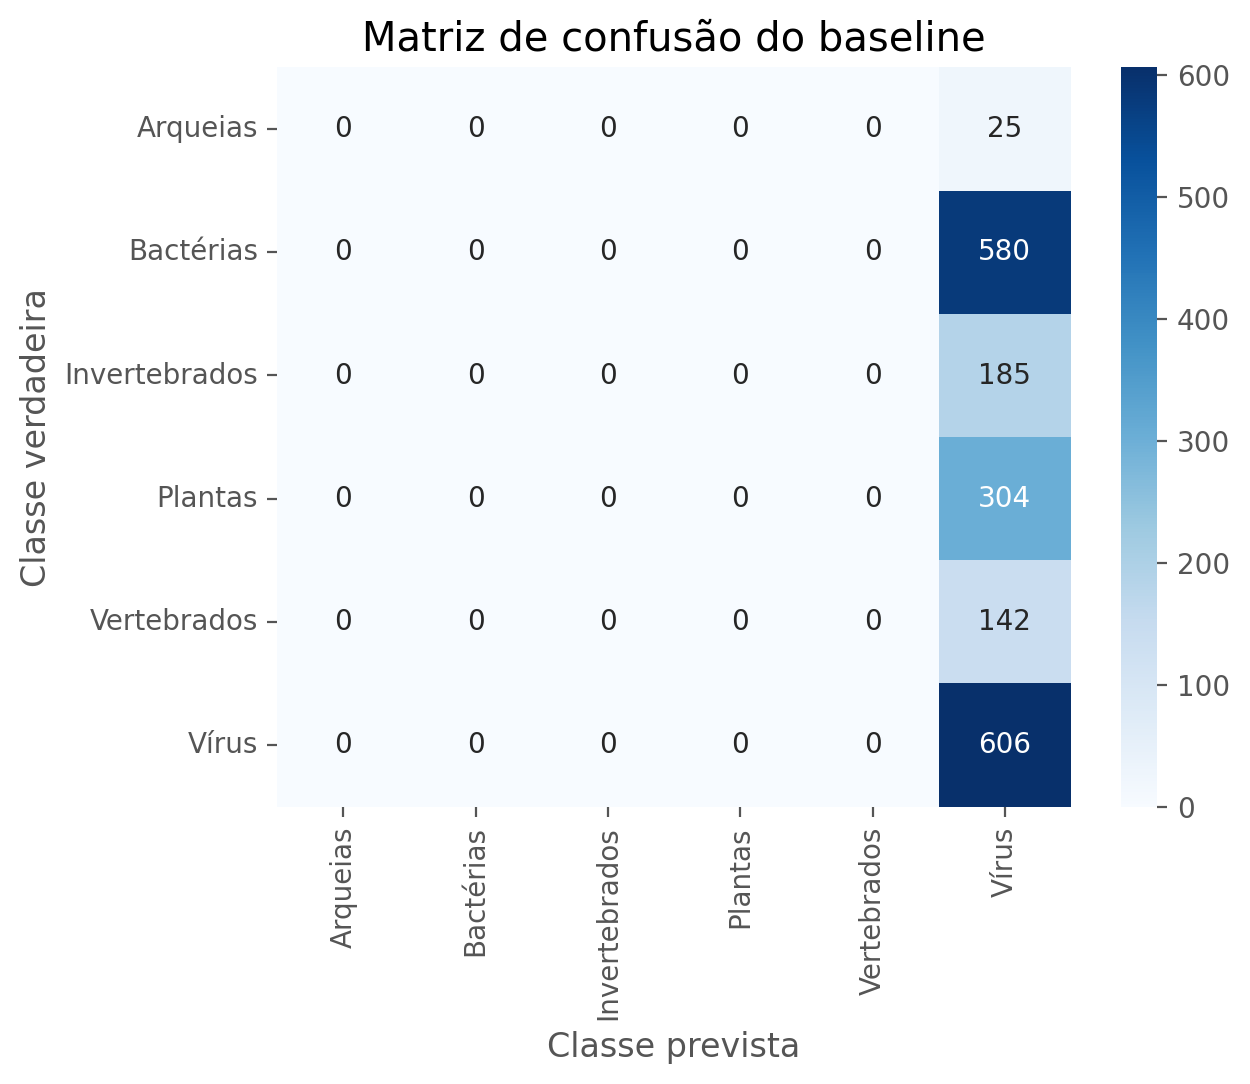

In [95]:
modelo_baseline.fit(X_treino, y_treino)

y_verdadeiro = y_teste
y_previsao = modelo_baseline.predict(X_teste)

matriz_conf = confusion_matrix(y_verdadeiro, y_previsao, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

eixo = sns.heatmap(df_conf, annot=True, fmt="d", cmap="Blues")
eixo.set(xlabel="Classe prevista", ylabel="Classe verdadeira", title="Matriz de confusão do baseline");

$ \ \ \ \ \ $ Para ver quais grupos o *k*-NN acerta e quais ele confunde entre si, construímos a sua matriz de confusão no conjunto de teste.

In [97]:
nome_melhor = df_resultados_cv.drop(columns="Baseline").mean().idxmax()
print("Modelo escolhido:", nome_melhor)

modelo = melhores_modelos[nome_melhor]
modelo.fit(X_treino, y_treino)

y_verdadeiro = y_teste
y_previsao = modelo.predict(X_teste)

F1_MACRO = f1_score(y_verdadeiro, y_previsao, average="macro")
ACURACIA = accuracy_score(y_verdadeiro, y_previsao)

print(f"F1 macro no teste: {F1_MACRO * 100:.1f}%")
print(f"Acurácia no teste: {ACURACIA * 100:.1f}%")

Modelo escolhido: k-NN
F1 macro no teste: 92.2%
Acurácia no teste: 94.2%


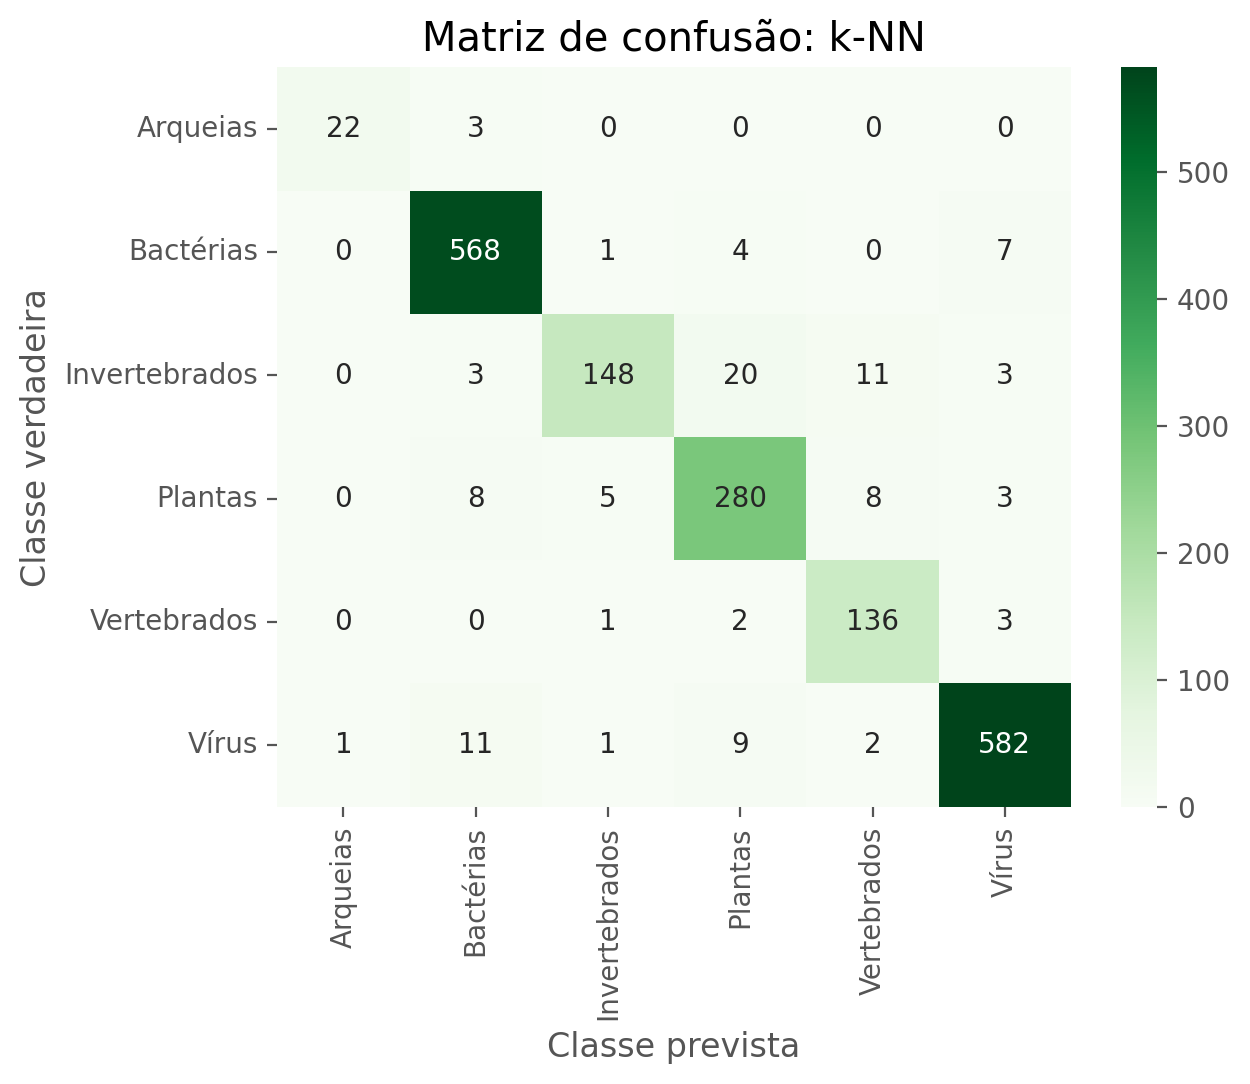

In [98]:
matriz_conf = confusion_matrix(y_verdadeiro, y_previsao, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

eixo = sns.heatmap(df_conf, annot=True, fmt="d", cmap="Greens")
eixo.set(xlabel="Classe prevista", ylabel="Classe verdadeira", title=f"Matriz de confusão: {nome_melhor}");

$ \ \ \ \ \ $ No conjunto de teste, o *k*-NN obteve F1 macro de 92,2% e acurácia de 94,2%. O F1 macro no teste ficou 1,5 ponto percentual acima da estimativa da validação cruzada (90,7% ± 1,1%), uma diferença da ordem da variação observada entre os folds. Uma possível explicação para o valor um pouco maior é que, no teste, o modelo foi treinado com todo o conjunto de treino (7.368 organismos), e não com 80% dele, como em cada fold, o que aumenta a chance de encontrar um organismo parecido. Como o desempenho no teste não foi inferior ao estimado, não há sinal de sobreajuste, e a estimativa obtida por validação cruzada se mostrou confiável. Em relação ao baseline (8,3% de F1 macro e 32,9% de acurácia), o ganho é considerável.

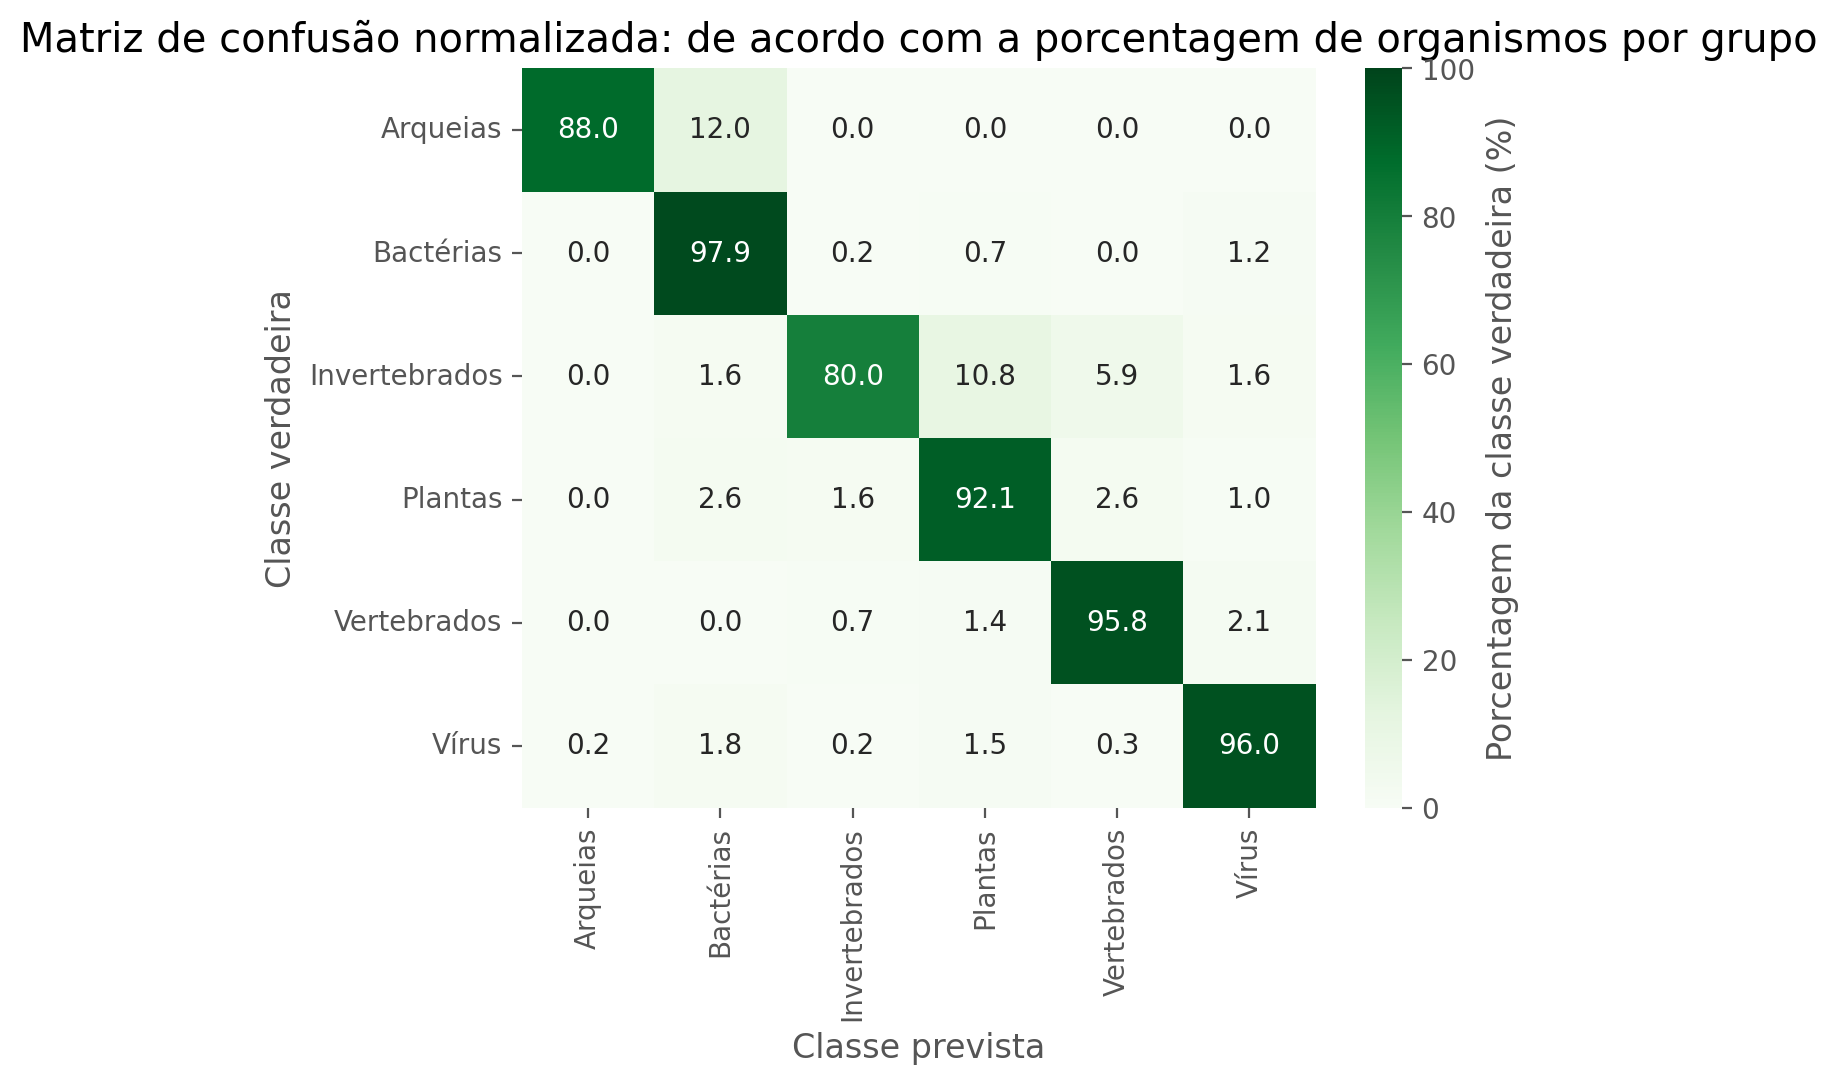

In [99]:
matriz_conf_pct = confusion_matrix(y_verdadeiro, y_previsao, labels=ordem_labels, normalize="true") * 100
df_conf_pct = pd.DataFrame(matriz_conf_pct, ordem_labels, ordem_labels)

eixo = sns.heatmap(df_conf_pct, annot=True, fmt=".1f", cmap="Greens", vmin=0, vmax=100,
                   cbar_kws={"label": "Porcentagem da classe verdadeira (%)"})
eixo.set(
    xlabel="Classe prevista",
    ylabel="Classe verdadeira",
    title=f"Matriz de confusão normalizada: de acordo com a porcentagem de organismos por grupo",
);

$ \ \ \ \ \ $ O modelo identificou corretamente cerca de 98% das bactérias (566 de 580), 96% dos vírus (582 de 606), 95% dos vertebrados (135 de 142), 91% das plantas (277 de 304) e 88% das arqueias (22 de 25). Os invertebrados foram o grupo mais difícil, com 79% de acerto (147 de 185), sendo confundidos principalmente com plantas (19 casos) e vertebrados (11 casos). Uma explicação, bem possível, é que a categoria de invertebrados do GenBank é bastante heterogênea, reunindo organismos muito diferentes entre si.

$ \ \ \ \ \ $ Os erros fazem sentido do ponto de vista biológico. As três arqueias classificadas incorretamente foram confundidas com bactérias, o outro grupo de procariontes. Além disso, há confusões nos dois sentidos entre bactérias e vírus (9 bactérias classificadas como vírus e 11 vírus classificados como bactérias), o que é coerente com o fato de que muitos vírus, como os bacteriófagos, infectam bactérias e tendem a adaptar seu uso de códons ao do hospedeiro.

$ \ \ \ \ \ $ A comparação entre as matrizes do k-nn e do baseline evidencia o ganho obtido, uma vez que enquanto o baseline classifica todos os organismos como vírus, o k-NN concentra quase todas as previsões na diagonal, acertando a maior parte dos organismos de todos os grupos.

<a id="interp"></a>
### 3.9 Interpretação dos Resultados

$ \ \ \ \ \ $ Agora podemos investigar com mais detalhes o desempenho do modelo escolhido em cada grupo e quais atributos mais influenciam suas previsões, discutindo os resultados à luz da biologia e da literatura.

#### 3.9.1 Desempenho por Grupo Taxonômico

$ \ \ \ \ \ $ Para analisar o desempenho do modelo em cada grupo, calculamos três métricas por classe no conjunto de teste com a função `classification_report` do `scikit-learn`: a precisão (entre os organismos que o modelo atribuiu a um grupo, a fração que realmente pertence a ele), a sensibilidade (entre os organismos de um grupo, a fração que o modelo reconheceu) e o F1, que combina as duas.

In [100]:
y_previsao_teste = modelo.predict(X_teste)

relatorio = classification_report(y_teste, y_previsao_teste, output_dict=True, zero_division=0)
df_relatorio = pd.DataFrame(relatorio).T.loc[ordem_labels, ["precision", "recall", "f1-score"]] * 100
df_relatorio.columns = ["Precisão", "Sensibilidade", "F1"]
df_relatorio.round(1)

,Precisão,Sensibilidade,F1
Arqueias,95.7,88.0,91.7
Bactérias,95.8,97.9,96.8
Invertebrados,94.9,80.0,86.8
Plantas,88.9,92.1,90.5
Vertebrados,86.6,95.8,91.0
Vírus,97.3,96.0,96.7


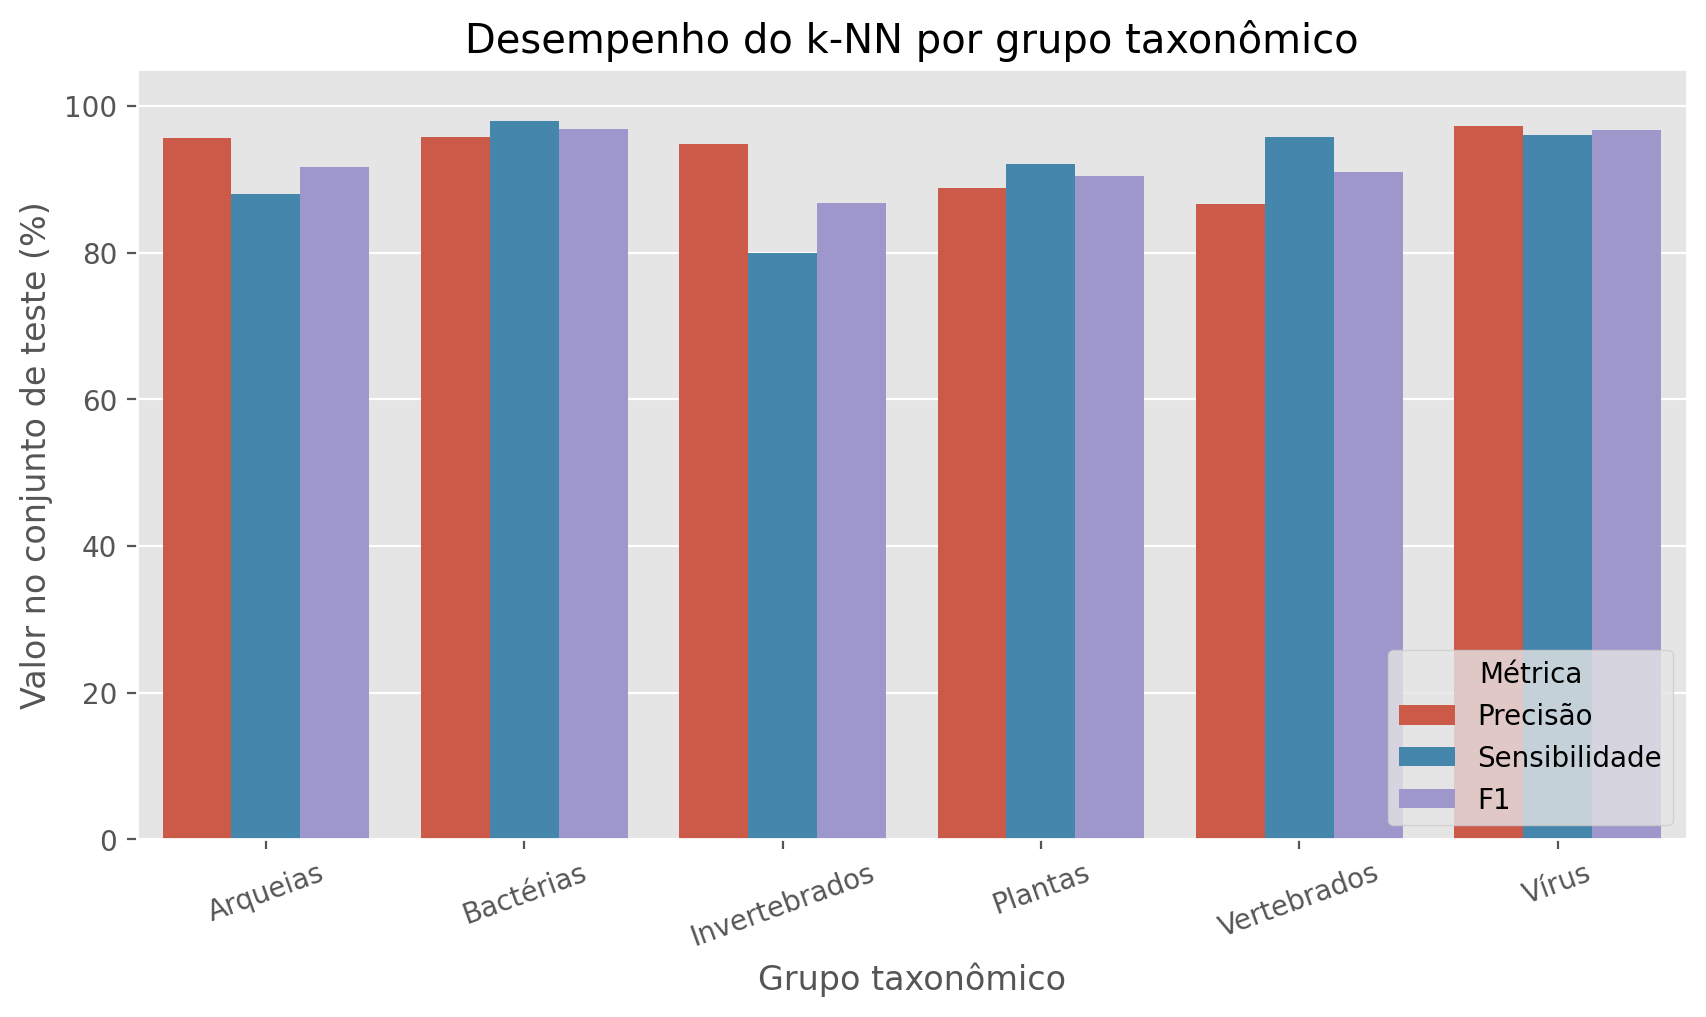

In [101]:
dados_metricas = df_relatorio.reset_index(names="Grupo").melt(
    id_vars="Grupo", var_name="Métrica", value_name="Valor (%)"
)

figura, eixo = plt.subplots(figsize=(10, 5))
sns.barplot(data=dados_metricas, x="Grupo", y="Valor (%)", hue="Métrica", ax=eixo)
eixo.set(
    xlabel="Grupo taxonômico",
    ylabel="Valor no conjunto de teste (%)",
    title=f"Desempenho do {nome_melhor} por grupo taxonômico",
)
eixo.set_ylim(0, 105)
eixo.legend(title="Métrica", loc="lower right")
plt.xticks(rotation=20);

$ \ \ \ \ \ $ O gráfico mostra que o desempenho varia entre os grupos. Bactérias e vírus, as classes mais numerosas, apresentam os maiores valores de F1 (96,8% e 96,7%), seguidos pelas arqueias (91,7%), pelos vertebrados (91,0%) e pelas plantas (90,5%). Os invertebrados têm o menor F1 (86,8%), por causa da sensibilidade mais baixa (80,0%): como visto na matriz de confusão, parte deles foi classificada como planta ou vertebrado. Esses mesmos erros explicam por que plantas (88,9%) e vertebrados (86,6%) têm as menores precisões, já que boa parte dos organismos atribuídos por engano a esses grupos são invertebrados. Esse resultado é coerente com a biologia, pois "invertebrados" não é um grupo natural, mas um conjunto definido pela ausência de coluna vertebral, que reúne linhagens muito distantes entre si, como artrópodes, moluscos e nematoides. Assim, o uso de códons dentro desse grupo é bastante variado, e alguns invertebrados acabam mais parecidos com organismos de outros grupos do que com outros invertebrados.

$ \ \ \ \ \ $ As arqueias merecem atenção especial por formarem o menor grupo. O modelo obteve precisão de 95,7% e sensibilidade de 88,0% para essa classe, ou seja, quando prevê uma arqueia ele quase sempre acerta (apenas um vírus foi classificado como arqueia), mas deixa de reconhecer algumas delas, que são classificadas como bactérias. Como há apenas 25 arqueias no conjunto de teste, cada erro altera a sensibilidade em 4 pontos percentuais, de modo que as métricas desse grupo são as que têm maior incerteza. Ainda assim, o resultado mostra que o modelo não ignorou a classe minoritária, ao contrário do baseline, que obteve F1 nulo em todos os grupos exceto os vírus. Isso reforça a escolha do F1 macro como métrica principal: como ele dá o mesmo peso a todos os grupos, só é possível obter um valor alto se o modelo também acertar as classes pequenas.

#### 3.9.2 Importância dos Atributos

$ \ \ \ \ \ $ Como o k-NN não atribui pesos aos atributos, utilizamos a importância por permutação para identificar quais deles mais influenciam suas previsões [[20, 6]](#refs). A ideia é simples: os valores de um atributo no conjunto de teste são embaralhados entre os organismos, o que destrói a relação entre esse atributo e o grupo taxonômico, e o modelo é avaliado novamente. Quanto maior a queda no F1 macro, mais o modelo depende daquele atributo. O processo é repetido 10 vezes para cada atributo, e calculamos a média e o desvio padrão das quedas. Como a permutação é feita nos dados de entrada do pipeline, a importância se refere aos atributos originais (os códons e o `Ncodons`), mesmo que o modelo trabalhe internamente com as componentes principais. Uma limitação do método é que atributos correlacionados podem dividir a importância entre si: ao embaralhar um códon, outros códons correlacionados ainda carregam parte da mesma informação.

In [102]:
resultado_permutacao = permutation_importance(
    modelo,
    X_teste,
    y_teste,
    scoring=METRICA,
    n_repeats=10,
    random_state=SEMENTE_ALEATORIA,
    n_jobs=-1,
)

importancias = pd.DataFrame(
    {
        "Importância média": resultado_permutacao.importances_mean,
        "Desvio padrão": resultado_permutacao.importances_std,
    },
    index=X_teste.columns,
).sort_values("Importância média", ascending=False)

importancias.head(15).round(4)

,Importância média,Desvio padrão
AUA,0.0374,0.0041
GAC,0.0230,0.0031
AGA,0.0201,0.0046
CGU,0.0190,0.0034
ACG,0.0189,0.0053
UAU,0.0183,0.0046
UGA,0.0171,0.0026
CUA,0.0166,0.0040
AAG,0.0154,0.0047
AAC,0.0148,0.0048


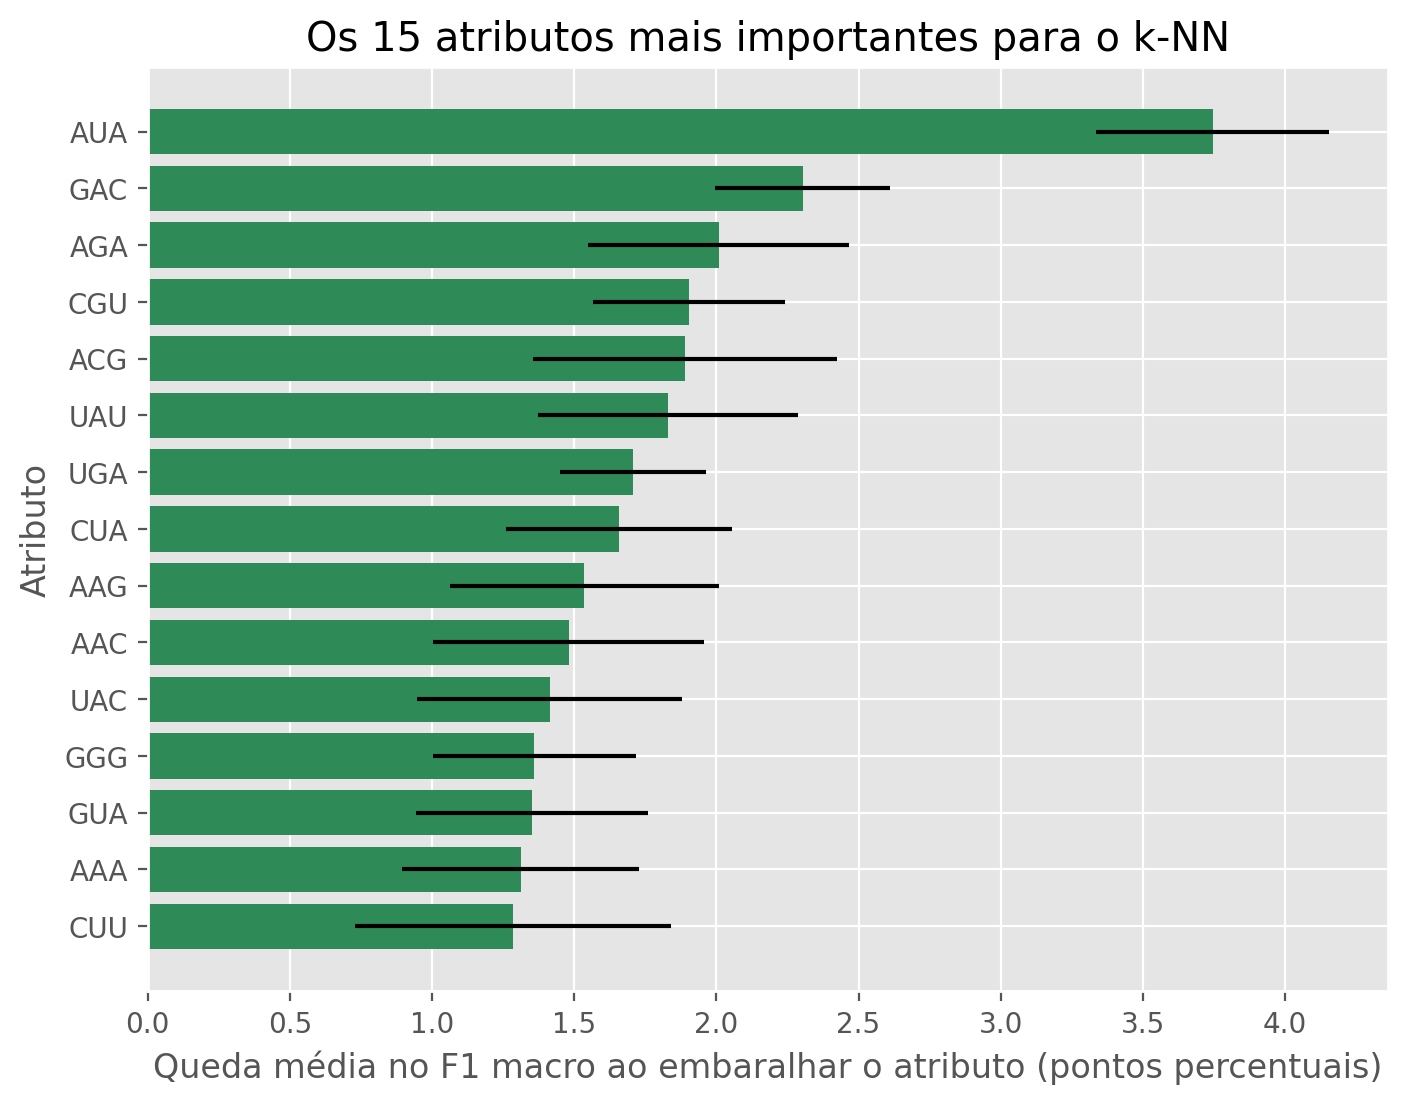

In [103]:
mais_importantes = importancias.head(15).iloc[::-1]

figura, eixo = plt.subplots(figsize=(8, 6))
eixo.barh(
    mais_importantes.index,
    mais_importantes["Importância média"] * 100,
    xerr=mais_importantes["Desvio padrão"] * 100,
    color="seagreen",
)
eixo.set(
    xlabel="Queda média no F1 macro ao embaralhar o atributo (pontos percentuais)",
    ylabel="Atributo",
    title=f"Os 15 atributos mais importantes para o {nome_melhor}",
);

$ \ \ \ \ \ $ O gráfico mostra que todas as quedas de desempenho foram pequenas. O atributo mais importante, o códon AUA, reduziu o F1 macro em 3,7 pontos percentuais quando embaralhado, e os demais causaram quedas entre 1,3 e 2,3 pontos, com barras de erro que se sobrepõem, de modo que a ordem entre eles é pouco precisa. Isso indica que o modelo não depende de poucos atributos, mas do perfil de uso de códons como um todo, o que é coerente com a análise de PCA, em que a informação estava distribuída em muitas componentes. Além disso, como muitos códons são correlacionados, a informação de um códon embaralhado continua parcialmente disponível nos demais, o que reduz a importância medida de cada um. Vale notar que o `Ncodons` não aparece entre os 15 atributos mais importantes, o que indica que o modelo não se apoia no número de códons contabilizados, que reflete mais o esforço de sequenciamento de cada grupo do que uma característica biológica.

$ \ \ \ \ \ $ Os códons mais importantes podem ser relacionados aos padrões observados na análise exploratória. O AUA, que codifica a isoleucina, é justamente o códon cujo uso elevado distingue as arqueias dos demais grupos no mapa de frequências médias (seção 3.4.2). O AGA, um dos seis códons da arginina, é pouco utilizado pelas bactérias, como também observado naquele mapa. Já o CGU e o ACG contêm o dinucleotídeo CG, cuja baixa frequência caracteriza os genomas de vertebrados [[10]](#refs).

$ \ \ \ \ \ $ Além disso, vários dos códons importantes formam pares de sinônimos que diferem apenas na terceira base, como UAU e UAC (tirosina) e AAA e AAG (lisina). Esses pares refletem a escolha entre códons terminados em A ou U e códons terminados em G ou C, o mesmo padrão de tabuleiro de xadrez observado na análise de correlação, ligado ao conteúdo de GC do genoma [[2]](#refs). O códon de parada UGA também se destaca, o que é coerente com o fato de que a preferência entre os três códons de parada varia entre os organismos, em parte acompanhando o conteúdo de GC.

#### 3.9.3 Discussão

$ \ \ \ \ \ $ Como o melhor modelo foi o k-NN com um único vizinho, cada organismo do teste é classificado de acordo com o organismo mais parecido do treino. Surge então uma dúvida: o modelo aprendeu padrões gerais de cada grupo ou acerta principalmente por encontrar no treino um parente próximo, como outra espécie do mesmo gênero? Para investigar isso, repetimos a avaliação com uma divisão agrupada por gênero, utilizando a classe `GroupShuffleSplit` do `scikit-learn`. O gênero de cada organismo foi obtido a partir da primeira palavra do `SpeciesName`, e todos os organismos de um mesmo gênero foram colocados no mesmo conjunto, de treino ou de teste. A divisão foi repetida 5 vezes, mantendo os hiperparâmetros encontrados pelo Optuna. Para os vírus, cujos nomes não seguem a nomenclatura binomial, a primeira palavra nem sempre corresponde ao gênero (como em "Sweet potato leaf curl virus"), de modo que o agrupamento é apenas aproximado. Além disso, essa divisão não é estratificada, então a proporção de cada grupo pode variar entre as repetições.

In [104]:
generos = df["SpeciesName"].str.split().str[0]
print("Número de gêneros distintos:", generos.nunique())

divisor = GroupShuffleSplit(n_splits=5, test_size=TAMANHO_TESTE, random_state=SEMENTE_ALEATORIA)

f1_agrupado = []
for indices_treino_g, indices_teste_g in divisor.split(df, df["Grupo"], groups=generos):
    df_treino_g = df.iloc[indices_treino_g]
    df_teste_g = df.iloc[indices_teste_g]

    X_treino_g = df_treino_g.reindex(ATRIBUTOS, axis=1)
    X_teste_g = df_teste_g.reindex(ATRIBUTOS, axis=1)
    X_treino_g = X_treino_g.assign(Ncodons=np.log10(X_treino_g["Ncodons"]))
    X_teste_g = X_teste_g.assign(Ncodons=np.log10(X_teste_g["Ncodons"]))
    y_treino_g = df_treino_g["Grupo"].values
    y_teste_g = df_teste_g["Grupo"].values

    modelo_g = cria_instancia_knn(melhor_trial_knn)
    modelo_g.fit(X_treino_g, y_treino_g)
    f1_agrupado.append(f1_score(y_teste_g, modelo_g.predict(X_teste_g), average="macro"))

print("Gêneros em comum entre treino e teste:", len(set(generos.iloc[indices_treino_g]) & set(generos.iloc[indices_teste_g])))
print(f"F1 macro com divisão agrupada por gênero: {np.mean(f1_agrupado) * 100:.1f}% ± {np.std(f1_agrupado) * 100:.1f}%")
print(f"F1 macro com a divisão original (teste): {F1_MACRO * 100:.1f}%")

Número de gêneros distintos: 3034
Gêneros em comum entre treino e teste: 0
F1 macro com divisão agrupada por gênero: 82.7% ± 3.9%
F1 macro com a divisão original (teste): 92.2%


$ \ \ \ \ \ $ Com a divisão agrupada por gênero, em que nenhum gênero aparece ao mesmo tempo no treino e no teste, o F1 macro foi de 82,7% ± 3,9%, contra 92,2% na divisão original, uma queda de cerca de 9,5 pontos percentuais. Essa queda indica que parte do desempenho medido na divisão original se deve à presença de espécies aparentadas no treino e no teste, o que é esperado para um modelo que classifica cada organismo pelo seu vizinho mais próximo. Ainda assim, o modelo continua muito superior ao baseline (8,3%), o que mostra que o uso de códons carrega um sinal do grupo taxonômico que vai além do parentesco próximo. O desvio padrão maior entre as repetições (3,9%) é coerente com o fato de essa divisão não ser estratificada: como os gêneros têm tamanhos muito diferentes, a composição do teste muda bastante de uma repetição para outra.

$ \ \ \ \ \ $ Esses resultados podem ser interpretados à luz das causas do viés de uso de códons. Como esse viés depende de características herdadas, como a tendência mutacional de cada genoma, que favorece o acúmulo de determinadas bases, e o conjunto de tRNAs disponíveis [[1, 2]](#refs), organismos aparentados tendem a ter perfis parecidos. Isso explica o bom desempenho de um modelo baseado em semelhança, como o *k*-NN, e também a natureza dos erros, que ocorreram principalmente entre grupos próximos ou que interagem entre si: arqueias e bactérias, os dois grupos de procariontes; bactérias e vírus, já que muitos vírus infectam bactérias e tendem a adaptar seu uso de códons ao do hospedeiro; e invertebrados, plantas e vertebrados, todos eucariontes. Os autores do conjunto de dados também o utilizaram para prever o grupo taxonômico dos organismos com algoritmos de aprendizado de máquina [[22]](#refs), o que reforça que o uso de códons carrega informação taxonômica.

$ \ \ \ \ \ $ Alguns cuidados limitam o alcance dessas conclusões. Primeiro, as categorias do conjunto de dados seguem a organização do GenBank, e não a classificação biológica, e o número de organismos de cada grupo reflete o esforço de sequenciamento, o que também influencia atributos como o `Ncodons`. Segundo, a mesma validação cruzada foi usada para escolher os hiperparâmetros e para comparar os modelos, o que tende a tornar as médias da seção 3.7 ligeiramente otimistas, embora o desempenho no conjunto de teste tenha confirmado essas estimativas. Por fim, como o conjunto de teste tem poucos organismos de alguns grupos, como as arqueias, as métricas dessas classes têm maior incerteza.

<a id="conclusao"></a>
## 4. Conclusões e Principais Aprendizados

$ \ \ \ \ \ $ Este trabalho investigou se é possível identificar o grupo taxonômico de um organismo a partir do seu viés de uso de códons. Após a limpeza dos dados e a reorganização das categorias em seis grupos, foram comparados cinco algoritmos de aprendizado de máquina, com hiperparâmetros otimizados pelo `Optuna`. Todos superaram amplamente o baseline (8,3% de F1 macro), e o melhor modelo, o k-NN, alcançou F1 macro de [91,9%] e acurácia de [93,9%] no conjunto de teste, valores compatíveis com os estimados por validação cruzada. Assim, a resposta à pergunta do trabalho é positiva: o uso de códons carrega informação suficiente para distinguir, com alto desempenho, arqueias, bactérias, vírus, plantas, invertebrados e vertebrados.

$ \ \ \ \ \ $ A comparação entre os algoritmos também trouxe informações sobre o problema. O bom desempenho da regressão logística indica que os grupos são, em grande parte, separáveis por fronteiras lineares no espaço dos códons, enquanto a árvore de decisão isolada teve o pior resultado, superada pelos modelos de comitê, que reduzem a sua variância. Além disso, os melhores modelos praticamente não reduziram a dimensionalidade, mantendo quase todas as componentes principais, o que sugere que, apesar da redundância entre os códons, informações relevantes estão distribuídas em muitas delas. Os erros mais frequentes ocorreram entre grupos biologicamente relacionados, como arqueias e bactérias, bactérias e vírus, e entre os invertebrados e os demais eucariontes.

$ \ \ \ \ \ $ O sucesso do k-NN com um único vizinho mostra que, na maioria dos casos, basta encontrar o organismo mais parecido no treino para acertar o grupo, o que é coerente com a herança evolutiva dos padrões de uso de códons. Por outro lado, isso indica que o desempenho medido reflete principalmente a classificação de organismos com parentes próximos nos dados de treino.

$ \ \ \ \ \ $ Como trabalhos futuros, seria interessante avaliar o desempenho com uma divisão dos dados agrupada por gênero ou família taxonômica, para medir a capacidade de classificar organismos sem parentes próximos no treino; utilizar a validação cruzada aninhada, para estimar o desempenho de forma ainda mais rigorosa; e testar atributos com significado biológico, como o conteúdo de GC na terceira posição dos códons ou o uso relativo de códons sinônimos.

<a id="interacao"></a>
## 5. Descrição do uso de IA neste trabalho

$ \ \ \ \ \ $ Ao longo do desenvolvimento deste trabalho, foi utilizada a ferramenta de Inteligência Artificial Claude [[23]](#refs) como apoio em diferentes etapas do processo. Um dos principais usos foi a depuração de código (debug), em que a IA ajudou a identificar a causa de diversos erros e avisos (*warnings*) encontrados durante a execução do notebook. Entre os principais casos, que fui anotando ao longo do trabalho, podemos citar:

- **Colunas de códons lidas como texto:** duas colunas de frequência (`UUU` e `UUC`) foram lidas como texto pelo `pandas`, pois continham valores mal formatados. A IA sugeriu a conversão com `pd.to_numeric(errors="coerce")`, que transformou esses valores em ausentes, permitindo identificar e remover as duas linhas problemáticas.
- **Transformação logarítmica aplicada duas vezes:** ao executar novamente apenas algumas células, o `log10` do `Ncodons` foi aplicado sobre valores que já estavam transformados (o mínimo passou a ser 0,477 em vez de 3). A IA explicou que o kernel guarda as variáveis entre execuções, e o problema foi resolvido reiniciando o kernel e executando o notebook desde o início.
- **Erro no *k*-NN com classes em texto:** durante a otimização do *k*-NN, diversas tentativas do Optuna falharam com a mensagem `ValueError: invalid literal for int() with base 10: 'Arqueias'`. Com o auxílio da IA, identifiquei que todas as tentativas com falha utilizavam pesos uniformes (`weights="uniform"`). Nesse caso, o `scikit-learn` utiliza um método interno de cálculo que tenta converter os nomes das classes em números inteiros, o que não é possível quando o *target* é representado por texto. A solução foi fixar o argumento `algorithm="ball_tree"`, que altera apenas a forma como os vizinhos mais próximos são encontrados, sem modificar o resultado do modelo. As tentativas que falharam continuam registradas no estudo, mas não são contabilizadas entre as 100 tentativas concluídas.
- **Armazenamento dos estudos do Optuna:** como a otimização dos cinco algoritmos leva bastante tempo, os estudos foram salvos em arquivos `.db` (`storage`), para que não precisassem ser refeitos a cada execução. No início, porém, cada nova execução da célula de otimização acrescentava tentativas ao estudo existente, pois o argumento `load_if_exists=True` carrega o estudo salvo e continua a busca a partir dele; o estudo da regressão logística chegou a ter mais de 100 tentativas. Com o auxílio da IA, a célula passou a contar apenas as tentativas concluídas (estado `COMPLETE`) e a executar somente as que faltam para completar 100, de modo que, depois da primeira execução, o notebook apenas carrega os estudos salvos. Os arquivos foram reunidos em uma pasta própria e enviados ao repositório, permitindo reproduzir os resultados sem refazer a otimização. Ao mover esses arquivos, o sistema operacional impediu a operação (`Permission denied`), e a IA explicou que o kernel do notebook mantinha os arquivos abertos; o problema foi resolvido desligando os kernels antes de mover os arquivos.
- **Células de otimização apontando para o estudo errado:** ao copiar as células da regressão logística para os demais algoritmos, as otimizações do *k*-NN, da árvore, da floresta e do HistGradientBoosting continuaram contando as tentativas do estudo da regressão logística, que já estava completo, e por isso não eram executadas. A IA identificou o problema, e cada célula passou a usar o seu próprio estudo.
- **Função não definida (`NameError`):** a otimização da floresta aleatória falhou porque a célula que define a função `cria_instancia_floresta` não havia sido executada antes. A solução foi executar as células na ordem correta.
- **Valor inteiro na tentativa padrão da árvore:** ao analisar o resultado da primeira tentativa da árvore de decisão (42,0%), muito abaixo das demais, a IA apontou que a fração de atributos havia sido informada como o número inteiro `1`, que o `scikit-learn` interpreta como um único atributo por divisão, e não como 100% dos atributos (`1.0`). Esse ponto é discutido na seção 3.6.6.
- **Modelo não treinado (`NotFittedError`):** ao tentar gerar a matriz de confusão do *baseline*, o modelo não havia sido treinado, pois a função `cross_val_score` treina apenas cópias do modelo durante a validação cruzada. A solução foi treinar o modelo com `fit` antes de realizar as previsões.
- **Gráficos do Optuna não exibidos:** os gráficos interativos do `optuna.visualization` não apareciam no VS Code. A solução foi utilizar a versão em `matplotlib` desses gráficos (`optuna.visualization.matplotlib`), que também é exibida corretamente no GitHub.

$ \ \ \ \ \ $ A IA também foi utilizada em decisões de análise. Na importância dos atributos, a ideia inicial era utilizar o gráfico de dependência parcial, mas, ao discutir as opções com a IA, optei pela importância por permutação, por dois motivos: o modelo escolhido, o k-NN, não atribui pesos aos atributos, e o PCA dentro do pipeline faz com que medidas internas, como o `feature_importances_` das árvores, se refiram às componentes principais, e não aos códons. Como a permutação é aplicada aos dados de entrada do pipeline, ela mede a importância dos códons originais. Além disso, a divisão agrupada por gênero (seção 3.9.3) foi sugerida pela IA como uma forma de verificar se o k-NN com um único vizinho acerta principalmente por encontrar parentes próximos no treino.

$ \ \ \ \ \ $ Por fim, a IA foi utilizada para explicar conceitos da disciplina sobre os quais eu tinha dúvidas, como o funcionamento do Optuna, do PCA e das métricas de classificação, sempre relacionando-os aos notebooks da disciplina, que serviram de base para o código; sugerir a estrutura do notebook; auxiliar na escrita do código da Figura 1 (roda do código genético); criar o brasão da casa; e elaborar questionários sobre o conteúdo das aulas, para estudo e preparação para a avaliação oral.

<a id="agradecimentos"></a>
## 6. Agradecimentos

$ \ \ \ \ \ $ Agradeço aos estudantes Filipi Martins, Gabriela Oliveira de Lima Cabral e Letícia Campos da Silva pelas trocas ao longo do desenvolvimento deste trabalho, que contribuiram para sua concretização.

<a id="refs"></a>
## 7. Referências

[1] PARVATHY, Sujatha Thankeswaran; UDAYASURIYAN, Varatharajalu; BHADANA, Vijaipal. Codon usage bias. Molecular Biology Reports, v. 49, n. 1, p. 539-565, 2022. DOI: 10.1007/s11033-021-06749-4. Disponível em: https://pmc.ncbi.nlm.nih.gov/articles/PMC8613526/. Acesso em: 21 set. 2026. <br>
[2] PLOTKIN, Joshua B.; KUDLA, Grzegorz. Synonymous but not the same: the causes and consequences of codon bias. Nature Reviews Genetics, v. 12, n. 1, p. 32-42, 2011. DOI: 10.1038/nrg2899. Disponível em: https://pmc.ncbi.nlm.nih.gov/articles/PMC3074964/. Acesso em: 22 set. 2026. <br>
[3] HALLEE, L.; KHOMTCHOUK, B. B. Codon usage [Dataset]. UCI Machine Learning Repository, 2020. Disponível em: https://doi.org/10.24432/C5KP6B. Acesso em: 21 set. 2026. <br>
[4] NAKAMURA, Yasukazu; GOJOBORI, Takashi; IKEMURA, Toshimichi. Codon usage tabulated from international DNA sequence databases: status for the year 2000. Nucleic Acids Research, v. 28, n. 1, p. 292, 2000. DOI: 10.1093/nar/28.1.292. Disponível em: https://pmc.ncbi.nlm.nih.gov/articles/PMC102460/. Acesso em: 22 set. 2026. <br>
[5] AKIBA, Takuya; SANO, Shotaro; YANASE, Toshihiko; OHTA, Takeru; KOYAMA, Masanori. Optuna: a next-generation hyperparameter optimization framework. In: ACM SIGKDD INTERNATIONAL CONFERENCE ON KNOWLEDGE DISCOVERY & DATA MINING, 25., 2019, Anchorage. Proceedings [...]. New York: ACM, 2019. p. 2623-2631. DOI: 10.1145/3292500.3330701. <br>
[6] PEDREGOSA, Fabian et al. Scikit-learn: machine learning in Python. Journal of Machine Learning Research, v. 12, p. 2825-2830, 2011. <br>
[7] CASSAR, Daniel Roberto. Vazamento de dados. Campinas: Ilum - Escola de Ciência, 2026. Notebook Jupyter. Material didático não publicado. <br>
[8] CASSAR, Daniel Roberto. ATP-203 2.2 - Divisão de dados em treino e teste. Campinas: Ilum - Escola de Ciência, 2026. Notebook Jupyter. Material didático não publicado. <br>
[9] CASSAR, Daniel Roberto. ATP-203 6.0 - Validação cruzada e otimização de hiperparâmetros. Campinas: Ilum - Escola de Ciência, 2026. Notebook Jupyter. Material didático não publicado. <br>
[10] BIRD, Adrian P. DNA methylation and the frequency of CpG in animal DNA. Nucleic Acids Research, v. 8, n. 7, p. 1499-1504, 1980. DOI: 10.1093/nar/8.7.1499. <br>
[11] CASSAR, Daniel Roberto. ATP-203 8.0 - Redução de dimensionalidade com PCA. Campinas: Ilum - Escola de Ciência, 2026. Notebook Jupyter. Material didático não publicado. <br>
[12] JOLLIFFE, Ian T.; CADIMA, Jorge. Principal component analysis: a review and recent developments. Philosophical Transactions of the Royal Society A, v. 374, n. 2065, 20150202, 2016. DOI: 10.1098/rsta.2015.0202. <br>
[13] CASSAR, Daniel Roberto. ATP-203 3.0 - Modelo linear e baseline. Campinas: Ilum - Escola de Ciência, 2026. Notebook Jupyter. Material didático não publicado. <br>
[14] CASSAR, Daniel Roberto. ATP-203 5.0 - Classificação binária. Campinas: Ilum - Escola de Ciência, 2026. Notebook Jupyter. Material didático não publicado. <br>
[15] SOKOLOVA, Marina; LAPALME, Guy. A systematic analysis of performance measures for classification tasks. Information Processing & Management, v. 45, n. 4, p. 427-437, 2009. DOI:

P.S. As referências estão ordenadas de acordo com a aparição no documento.